In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 1e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0004
Discriminator learning rate: 0.0001
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 232,833
Discriminator parameters: 138,689
Generator learning rate: 0.0004
Discriminator learning rate: 0.0001
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(16, 1, 1))
    (1): ConvTranspose2d(16, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.350195	G_loss: 0.934224
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.161882	G_loss: 0.956135
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.162662	G_loss: 0.906504
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.191001	G_loss: 0.884354
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.195005	G_loss: 0.896715
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.209493	G_loss: 0.909486
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.137822	G_loss: 1.069692
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.164227	G_loss: 0.955806
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.169054	G_loss: 0.957519
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.182915	G_loss: 1.136572
====> Epoch: 1 Train D_loss: 1.1640, Train G_loss: 0.9310
====> Epoch: 1 Val D_loss: 1.2982, Val G_loss: 0.6221
📈 Epoch 1 Summary:
   Train D Loss: 1.1640, Val D Loss: 1.2982
   Train G Loss: 0.9310, Val G Loss: 0.6221

📊 Epoch 2/100
------------------------

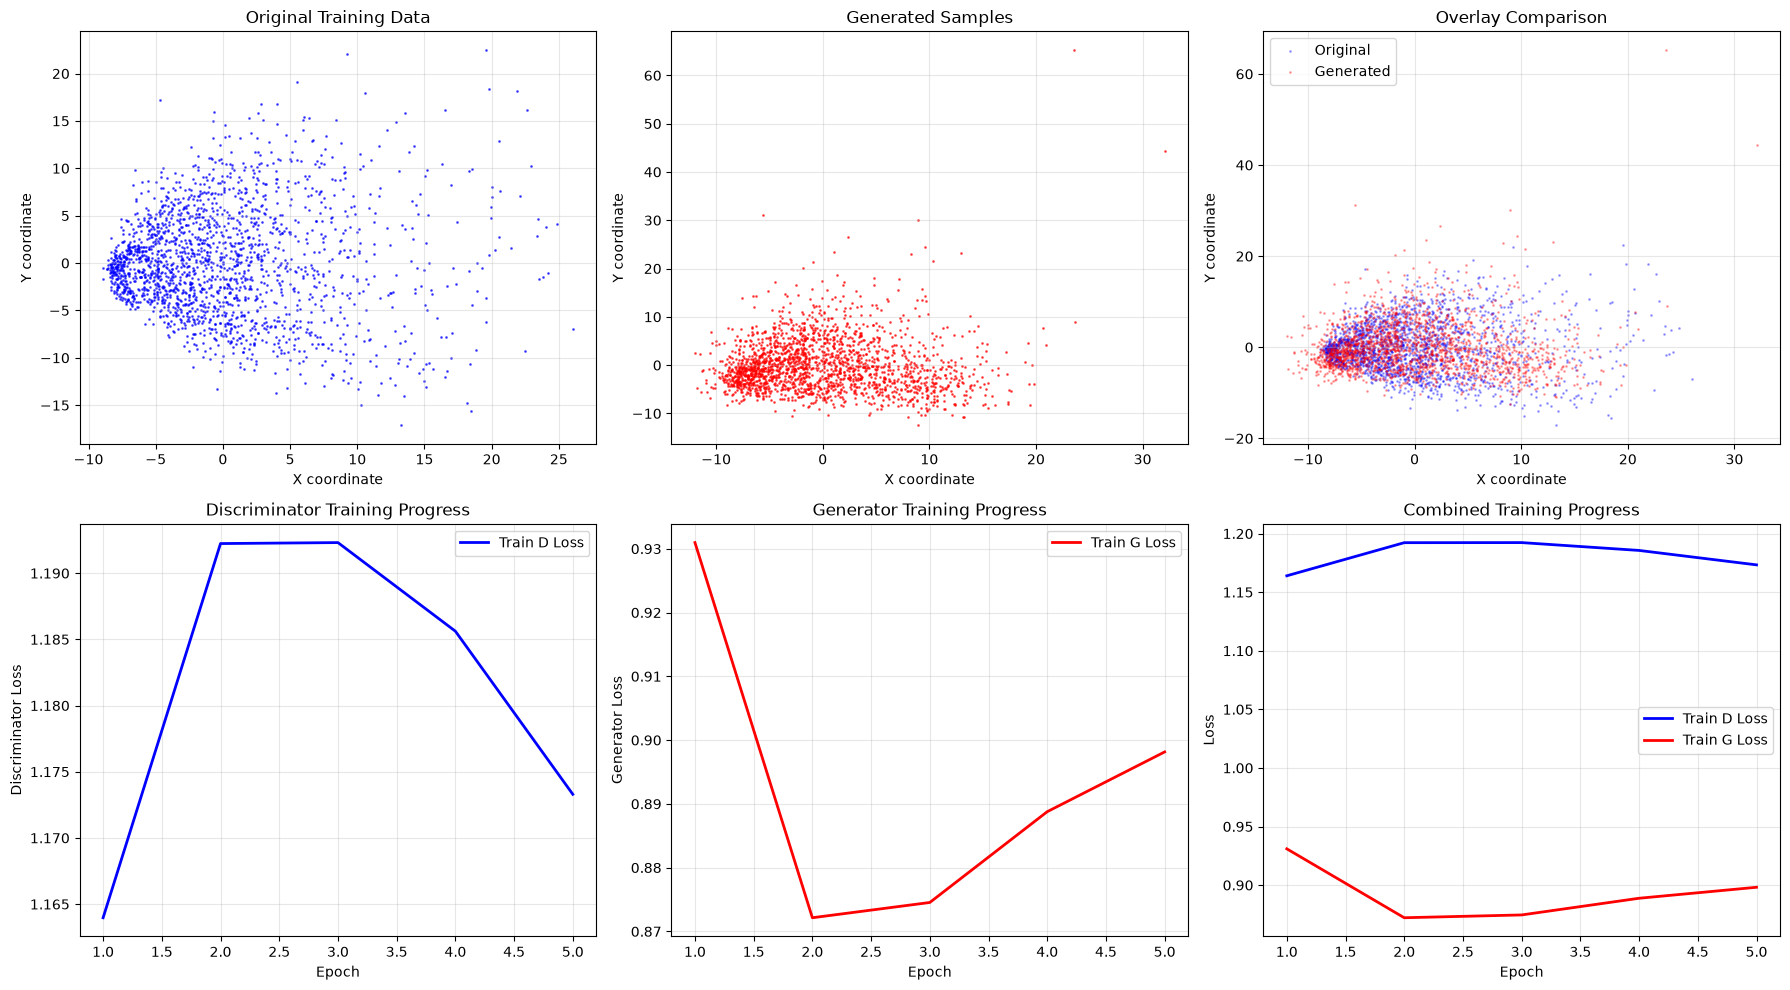

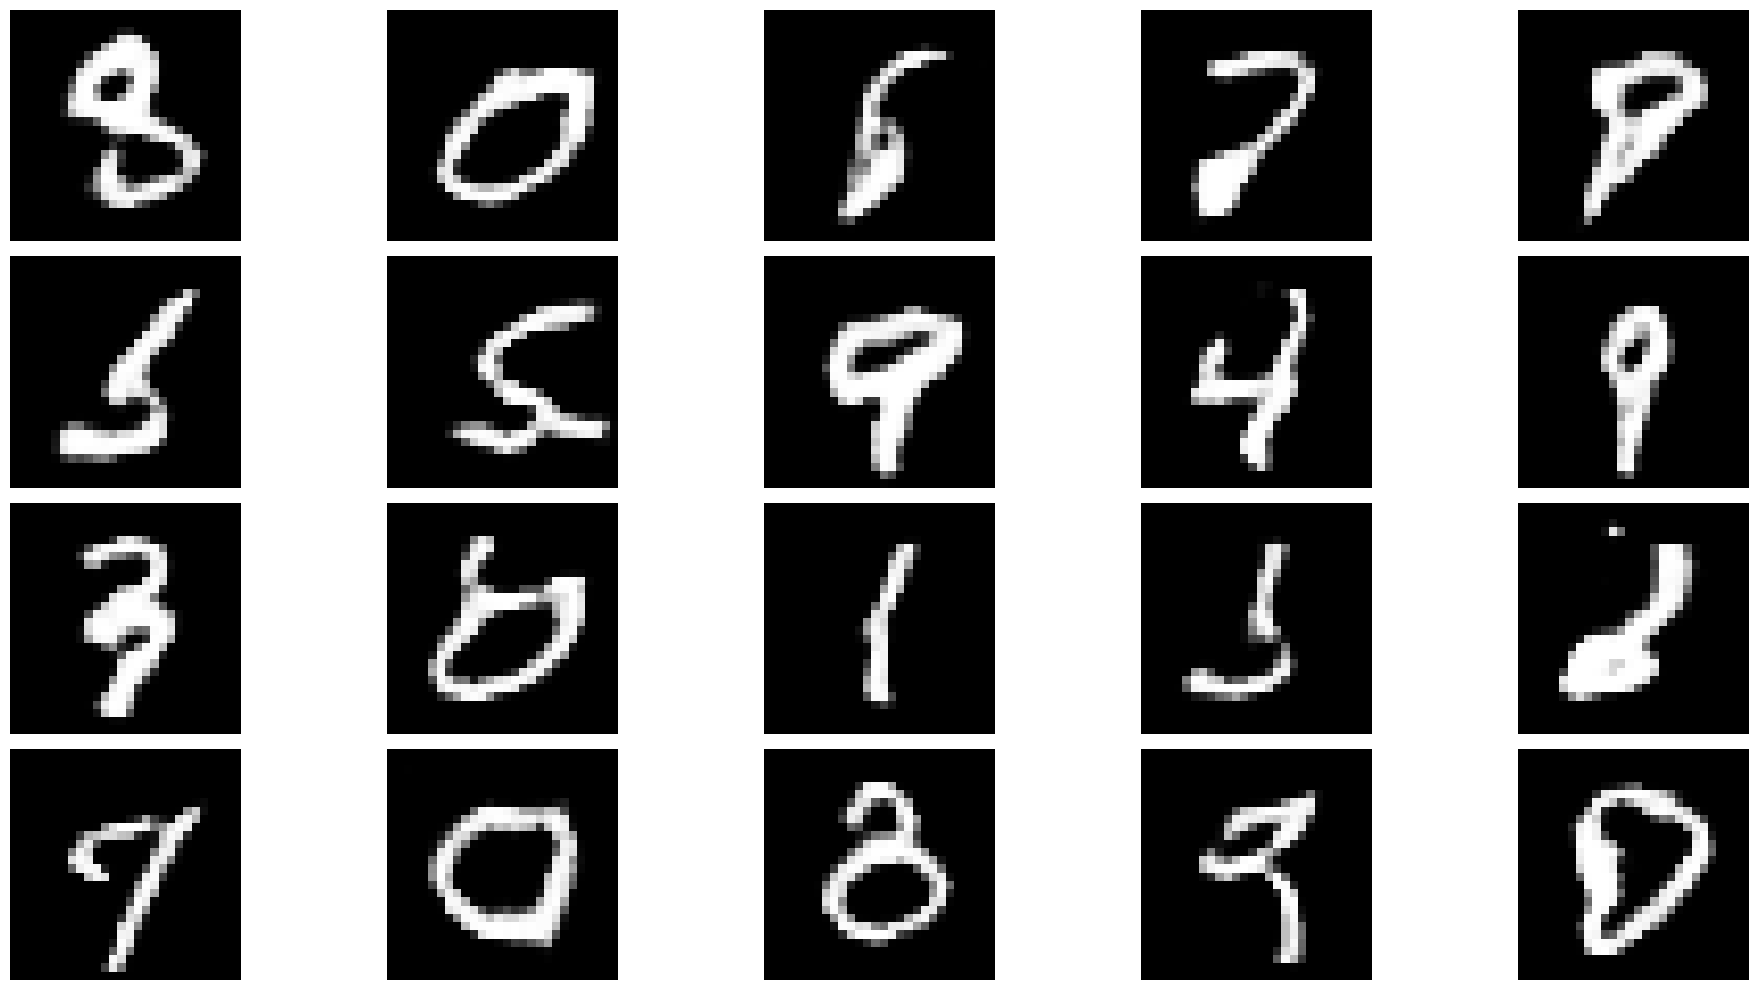

📈 Epoch 5 Summary:
   Train D Loss: 1.1733, Val D Loss: 1.2693
   Train G Loss: 0.8981, Val G Loss: 0.9023

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.143525	G_loss: 0.854174
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.131132	G_loss: 1.366182
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.538613	G_loss: 1.578006
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.107415	G_loss: 0.931329
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.162082	G_loss: 0.892812
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.106024	G_loss: 1.178373
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.169053	G_loss: 1.093087
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.182649	G_loss: 1.101551
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.158827	G_loss: 0.835899
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.196763	G_loss: 0.860613
====> Epoch: 6 Train D_loss: 1.1648, Train G_loss: 0.9048
====> Epoch: 6 Val D_loss: 1.2755, Val G_loss: 0.6284
📈 Epoch 6 Summary:
   Train D Loss: 1.1648, Val D Loss: 1.2755
   Train G Loss: 0.9048, Val G Loss: 0

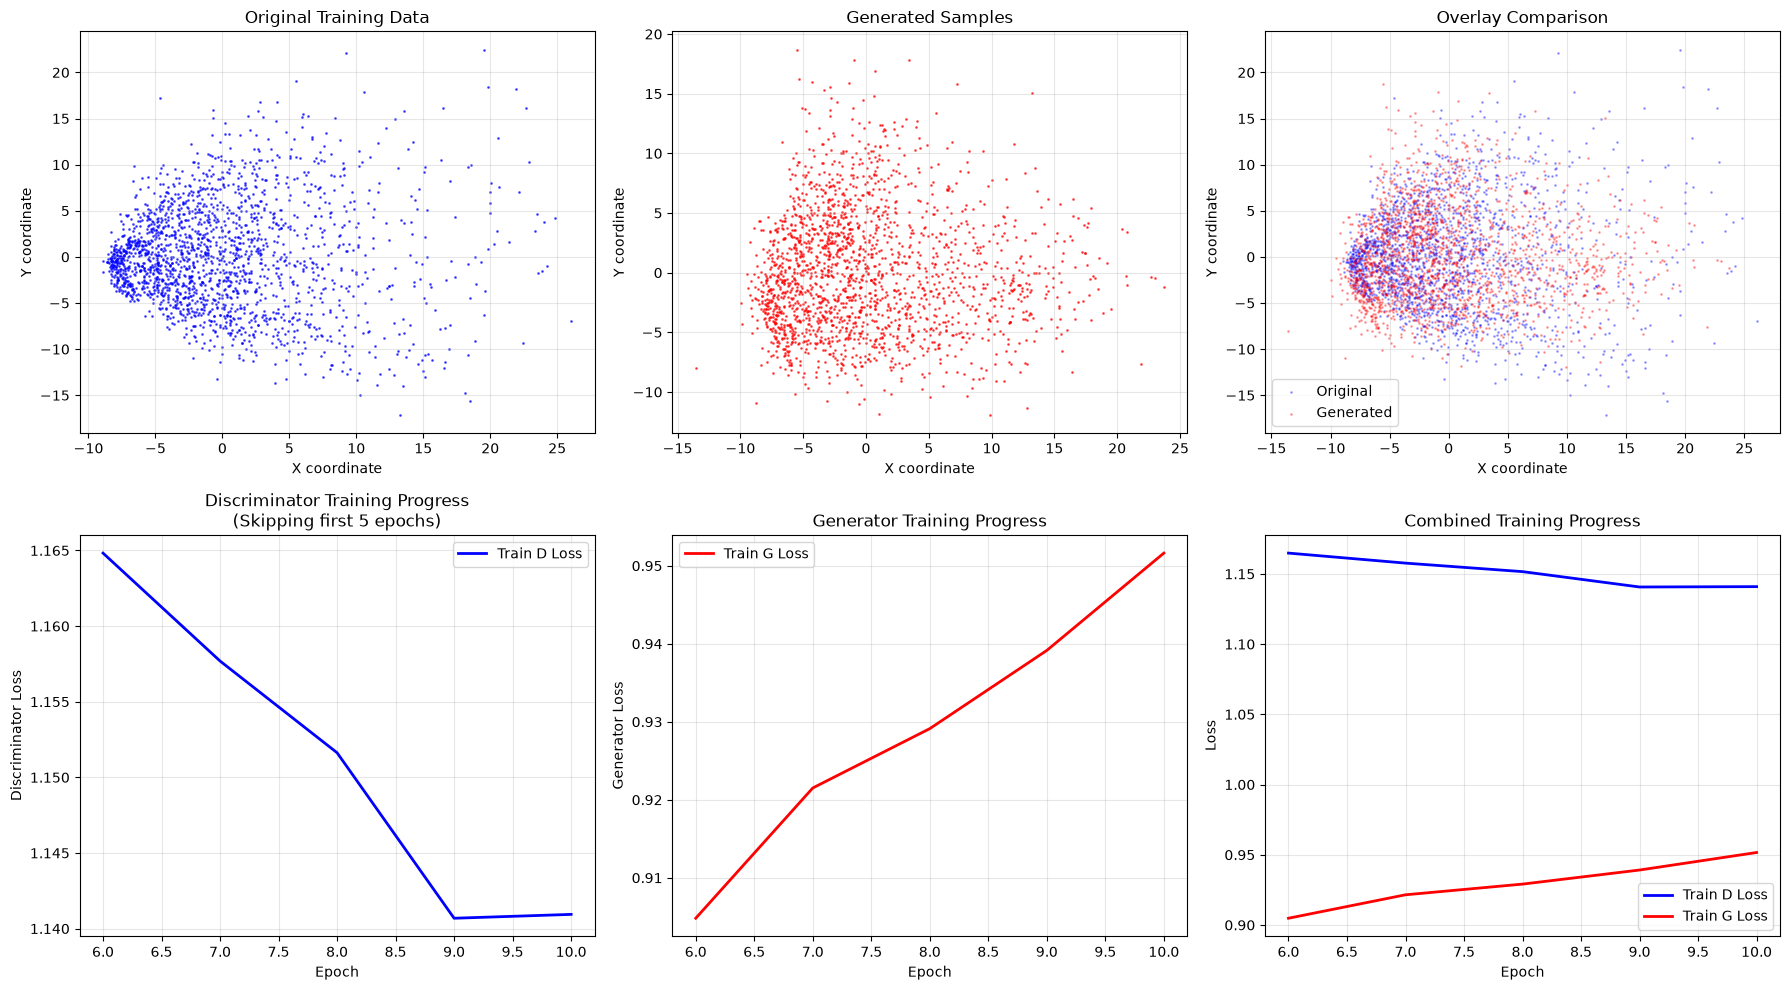

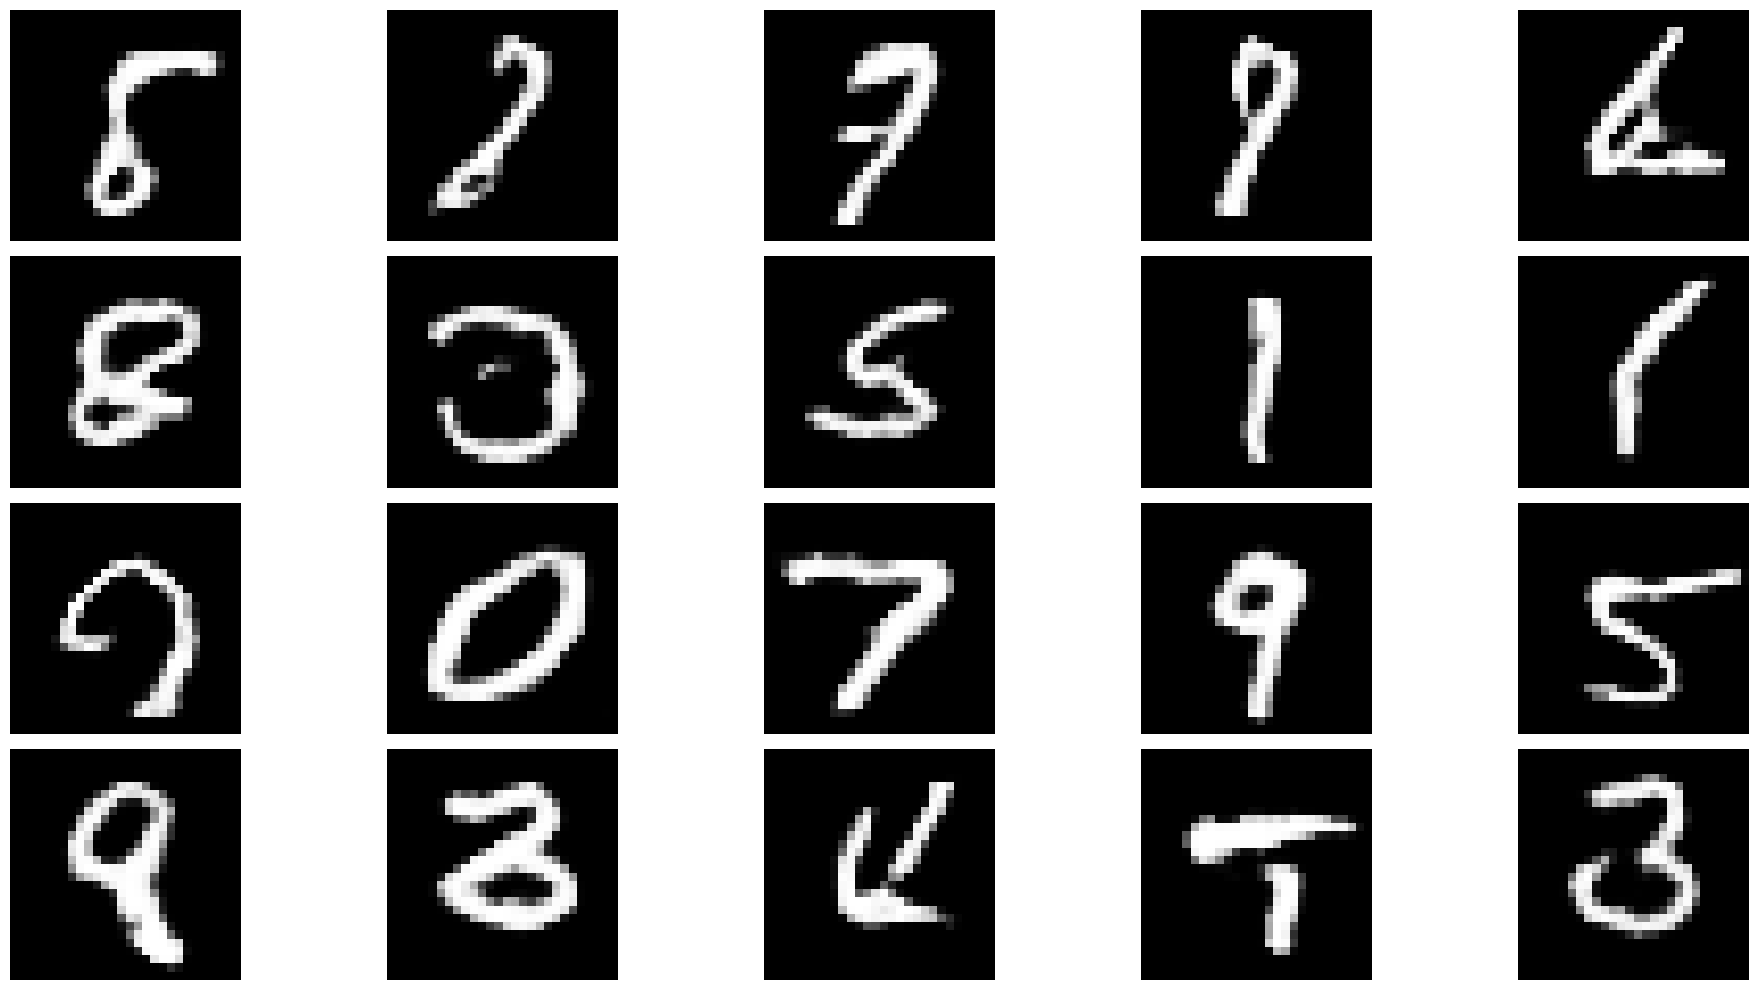

📈 Epoch 10 Summary:
   Train D Loss: 1.1409, Val D Loss: 1.2087
   Train G Loss: 0.9516, Val G Loss: 0.8033

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.174788	G_loss: 1.010188
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.084873	G_loss: 0.713020
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.098337	G_loss: 0.827566
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.072639	G_loss: 0.884769
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.109994	G_loss: 1.038975
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.199580	G_loss: 0.815216
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.088493	G_loss: 1.059712
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.093205	G_loss: 1.184191
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.118465	G_loss: 1.212607
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.075543	G_loss: 1.075121
====> Epoch: 11 Train D_loss: 1.1273, Train G_loss: 0.9582
====> Epoch: 11 Val D_loss: 1.2080, Val G_loss: 0.8608
📈 Epoch 11 Summary:
   Train D Loss: 1.1273, Val D Loss: 1.2080
   Train G Loss: 0.9582

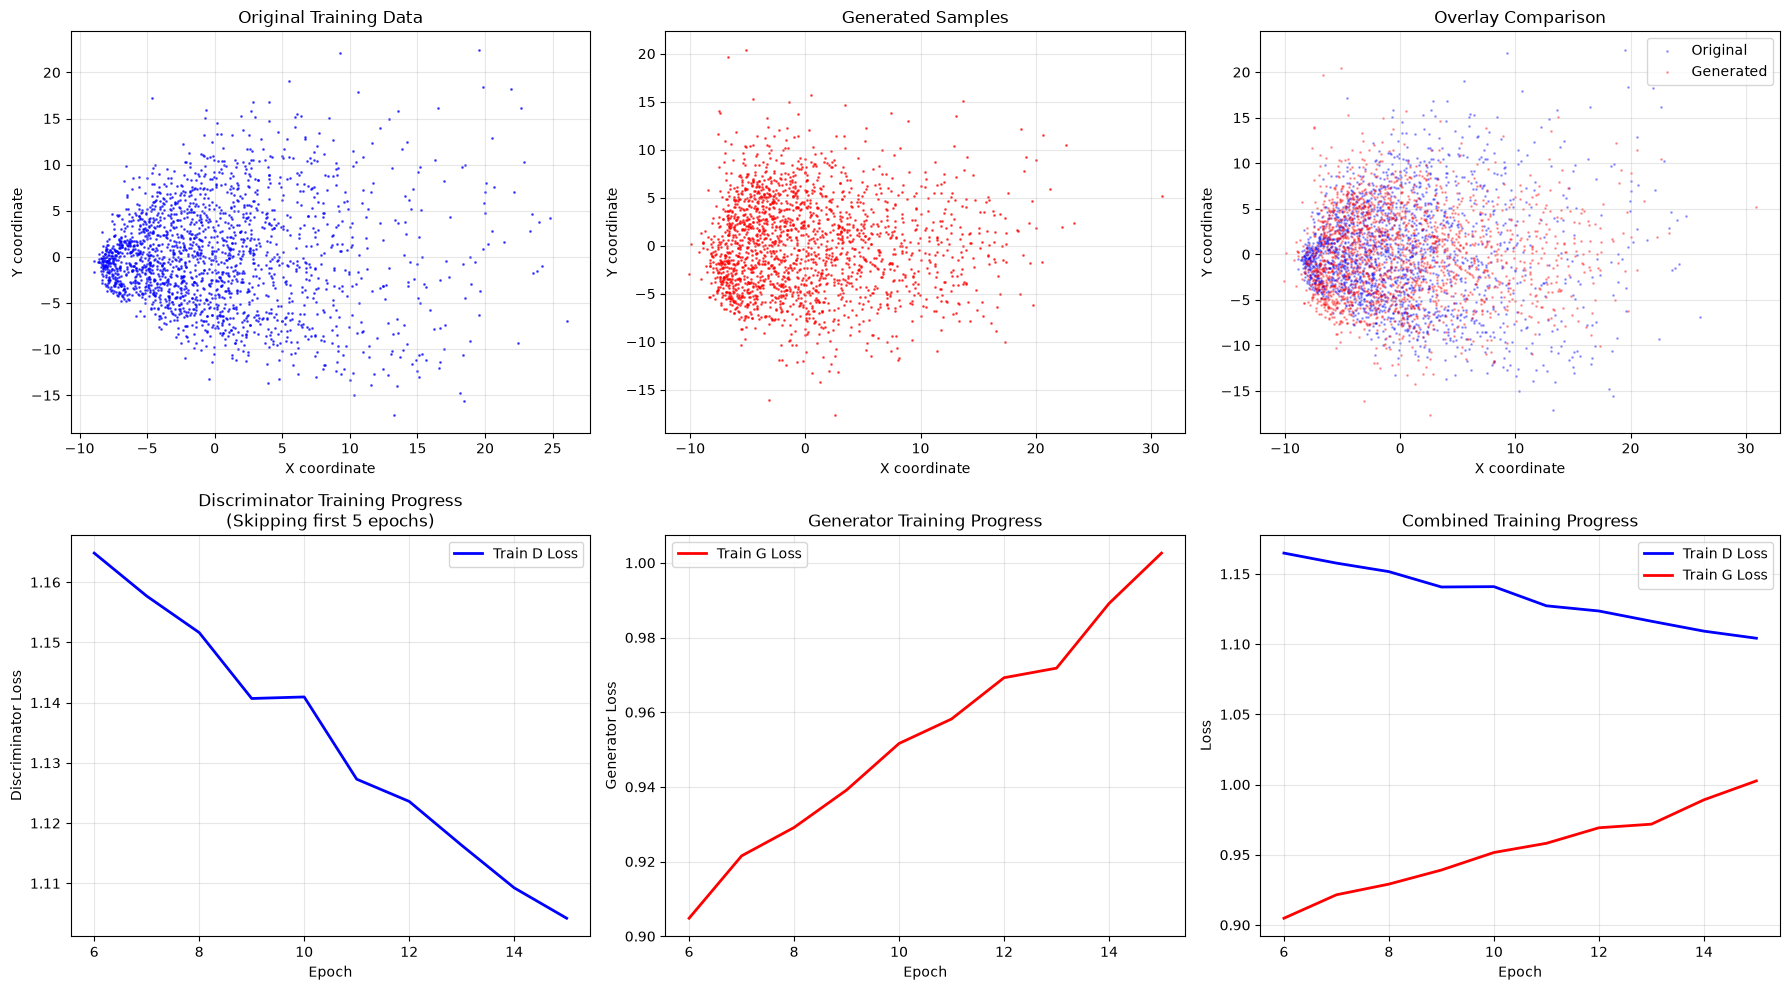

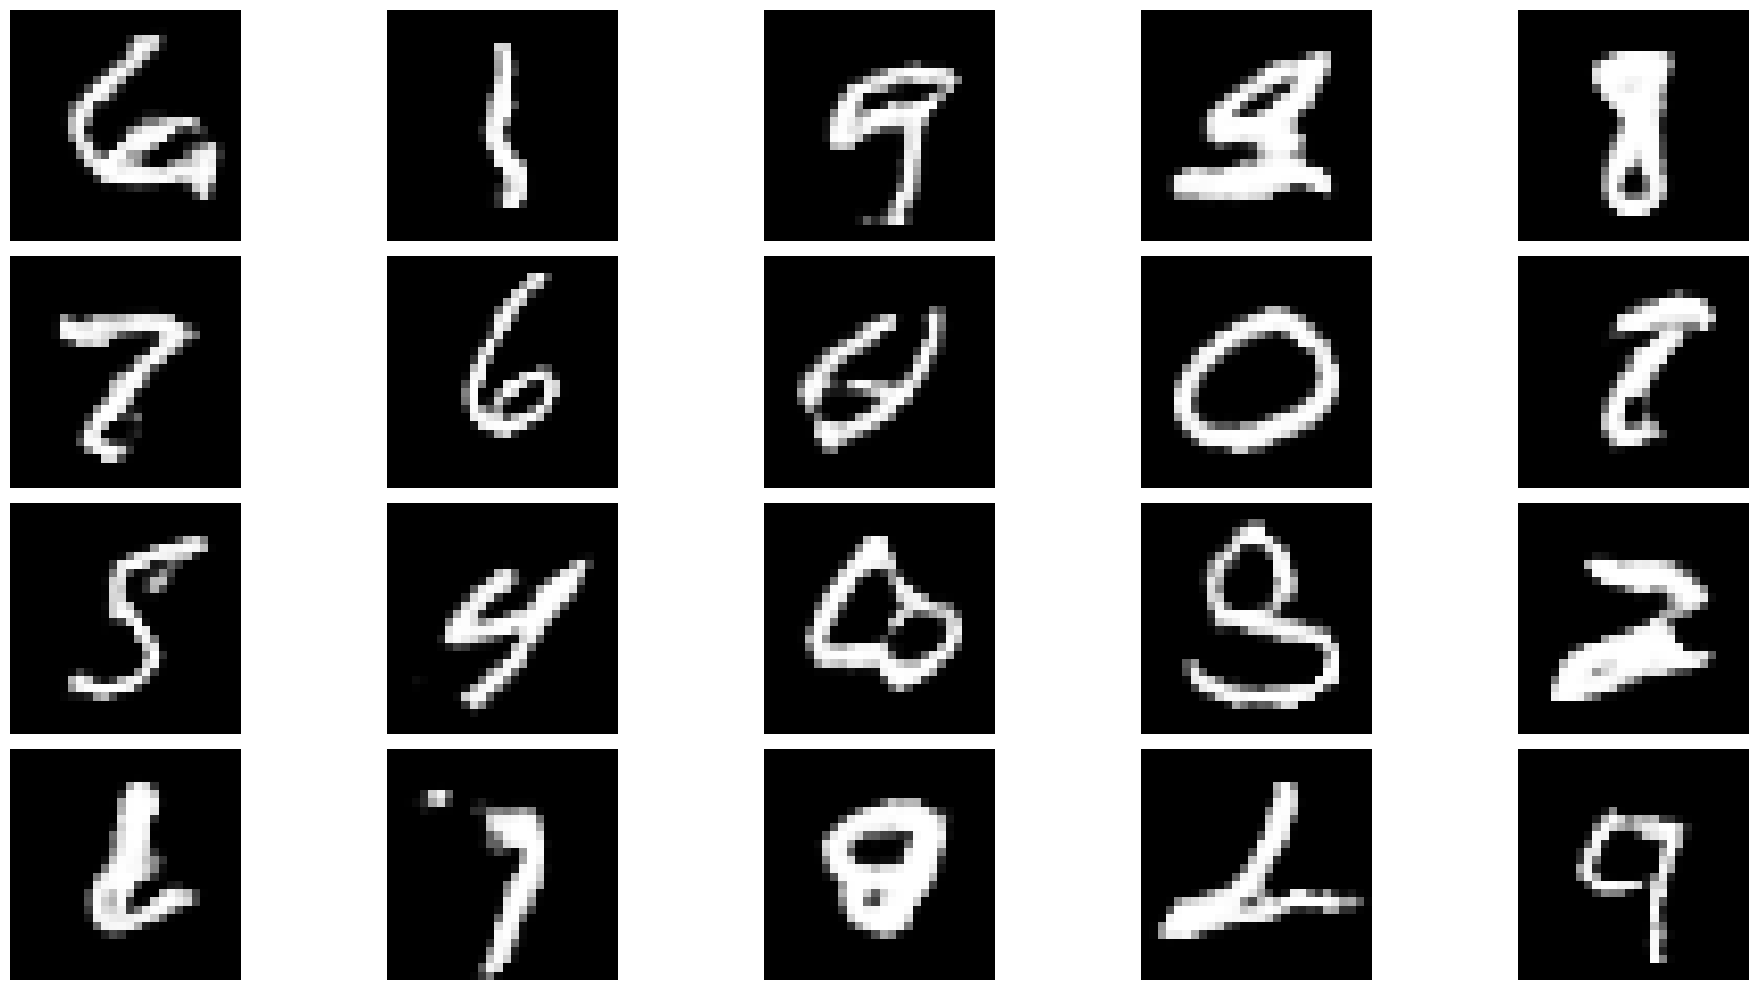

📈 Epoch 15 Summary:
   Train D Loss: 1.1042, Val D Loss: 1.2510
   Train G Loss: 1.0026, Val G Loss: 1.0486

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.066871	G_loss: 1.013853
Epoch: 16 [6400/60000 (11%)]	D_loss: 1.136972	G_loss: 0.844752
Epoch: 16 [12800/60000 (21%)]	D_loss: 1.115963	G_loss: 0.926263
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.034830	G_loss: 0.975337
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.021553	G_loss: 1.037923
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.013626	G_loss: 1.161731
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.113674	G_loss: 0.857614
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.073771	G_loss: 0.904162
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.126450	G_loss: 0.892697
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.017652	G_loss: 1.266600
====> Epoch: 16 Train D_loss: 1.0948, Train G_loss: 1.0111
====> Epoch: 16 Val D_loss: 1.2021, Val G_loss: 0.9346
📈 Epoch 16 Summary:
   Train D Loss: 1.0948, Val D Loss: 1.2021
   Train G Loss: 1.0111

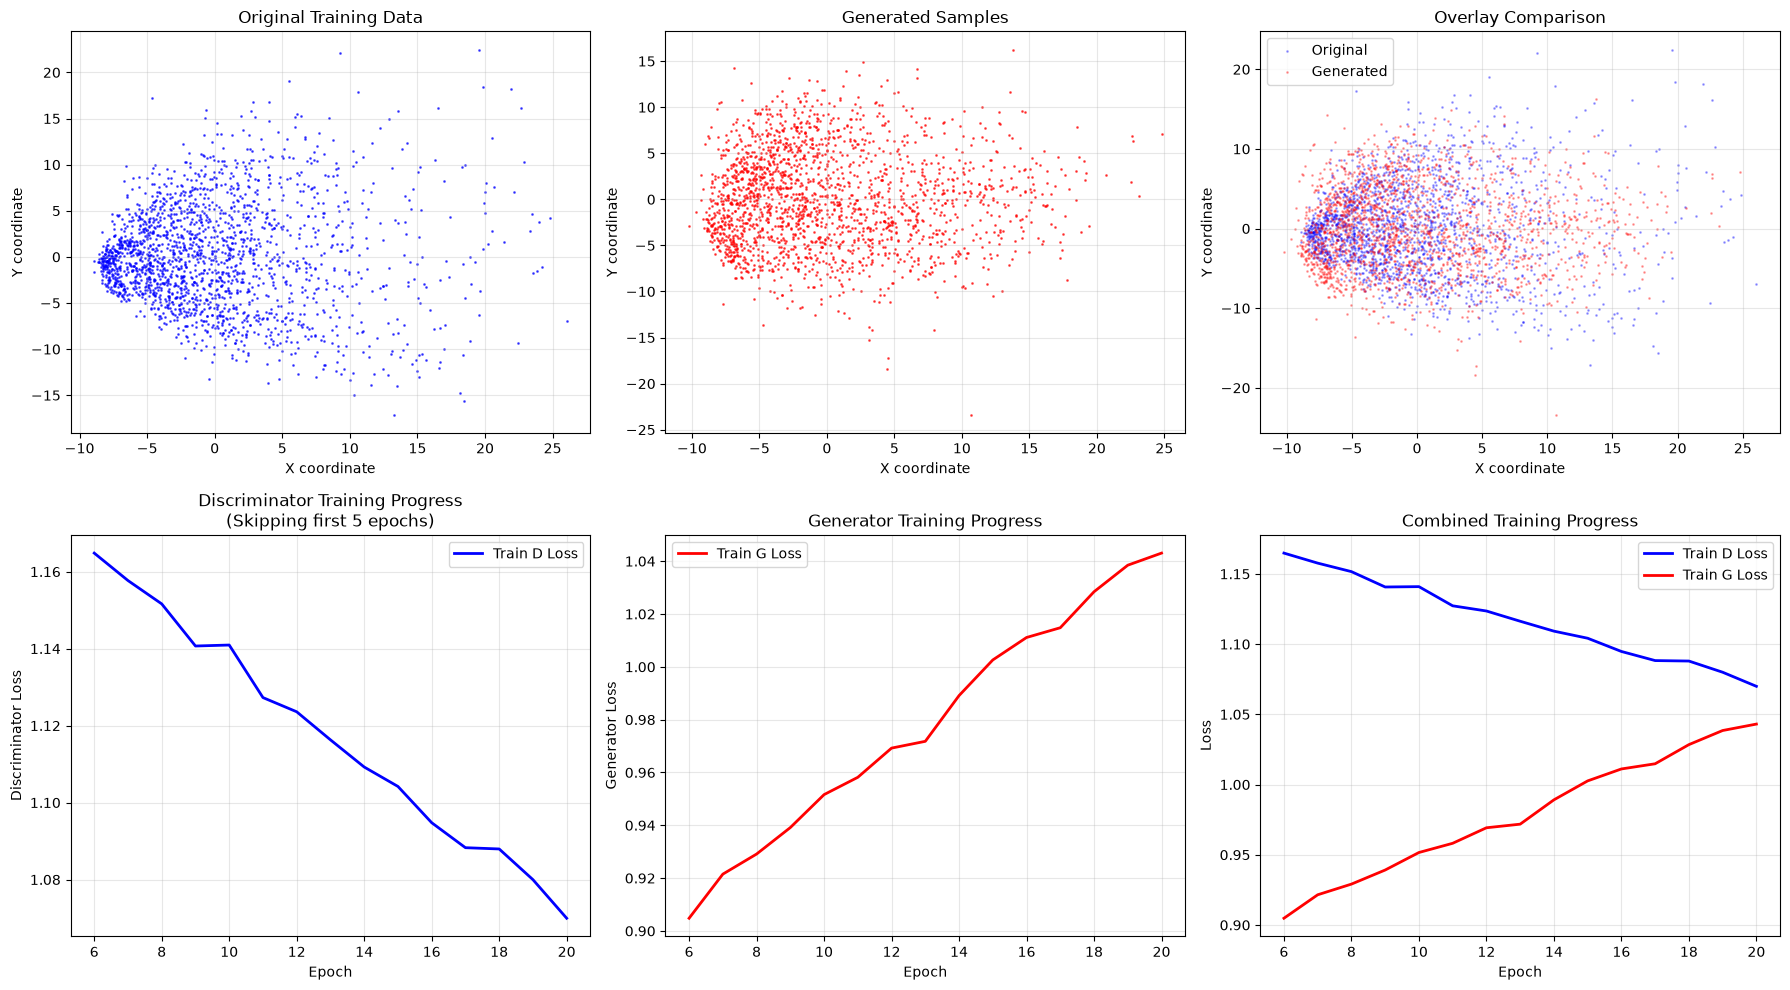

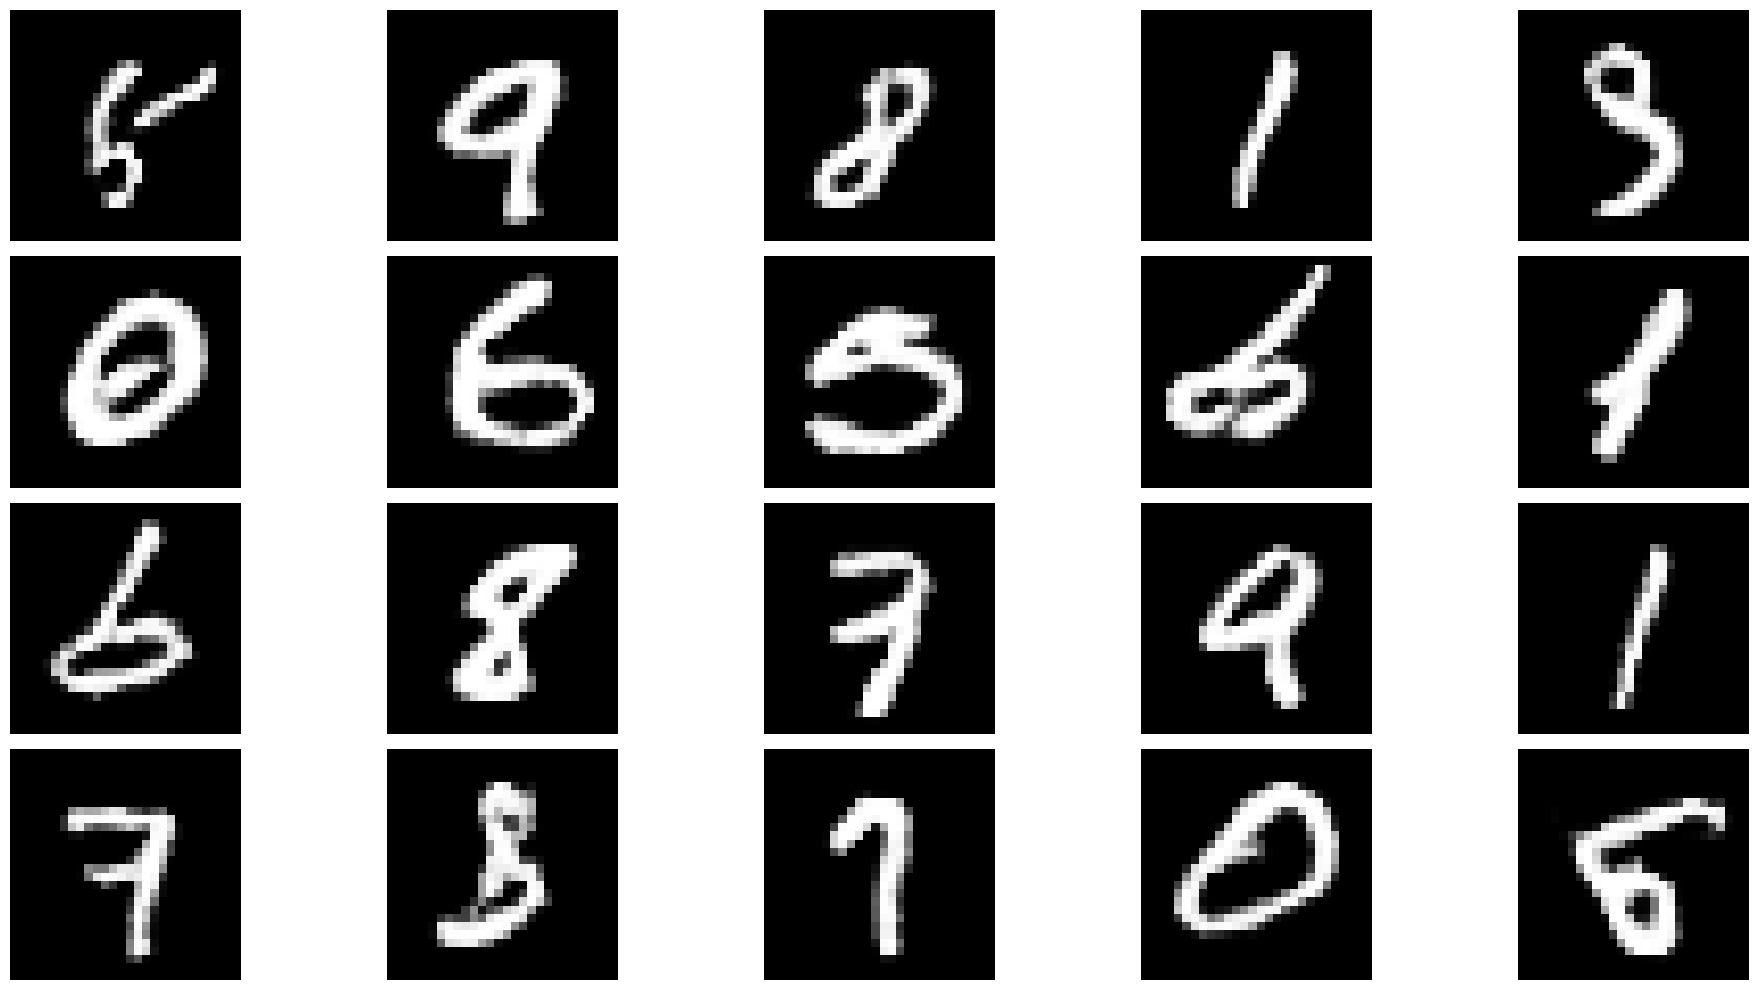

📈 Epoch 20 Summary:
   Train D Loss: 1.0700, Val D Loss: 1.1840
   Train G Loss: 1.0431, Val G Loss: 0.7872

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 1.043915	G_loss: 1.175193
Epoch: 21 [6400/60000 (11%)]	D_loss: 1.069743	G_loss: 0.800952
Epoch: 21 [12800/60000 (21%)]	D_loss: 1.149270	G_loss: 1.637588
Epoch: 21 [19200/60000 (32%)]	D_loss: 1.065725	G_loss: 1.069884
Epoch: 21 [25600/60000 (43%)]	D_loss: 1.051221	G_loss: 0.880098
Epoch: 21 [32000/60000 (53%)]	D_loss: 1.146504	G_loss: 1.520550
Epoch: 21 [38400/60000 (64%)]	D_loss: 1.109184	G_loss: 1.229640
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.166399	G_loss: 0.767087
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.999527	G_loss: 0.919766
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.996161	G_loss: 1.220195
====> Epoch: 21 Train D_loss: 1.0631, Train G_loss: 1.0509
====> Epoch: 21 Val D_loss: 1.1749, Val G_loss: 0.9823
📈 Epoch 21 Summary:
   Train D Loss: 1.0631, Val D Loss: 1.1749
   Train G Loss: 1.0509

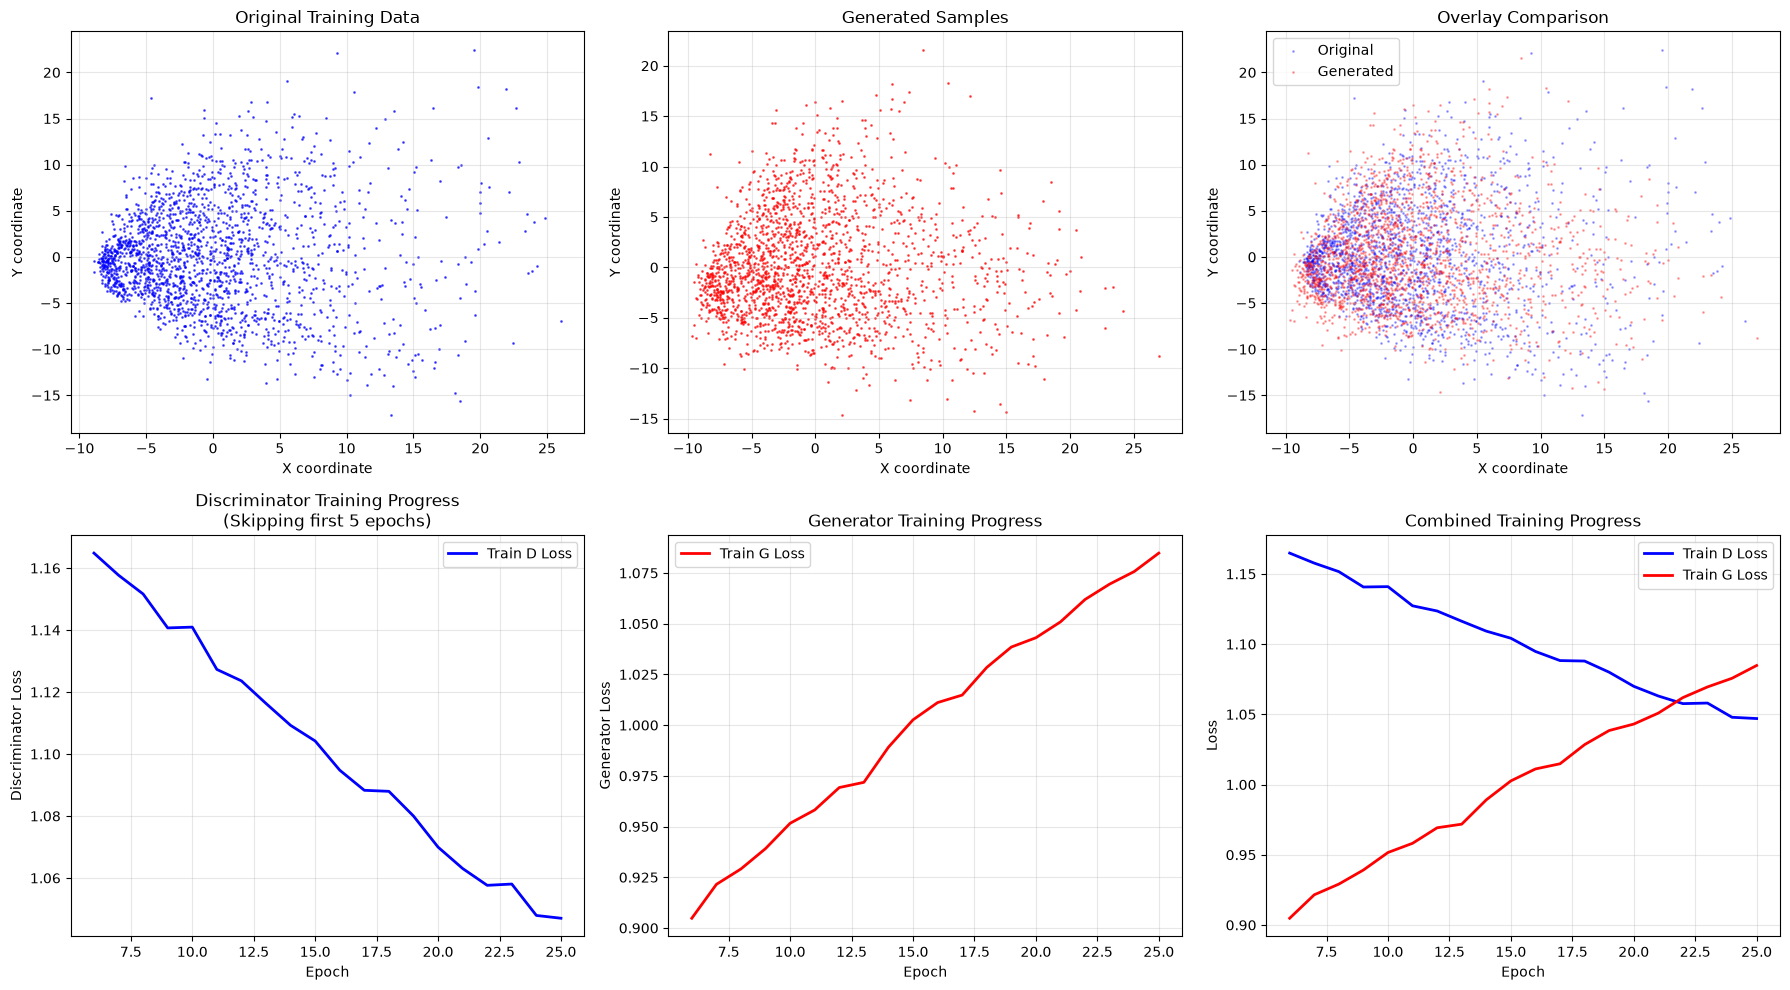

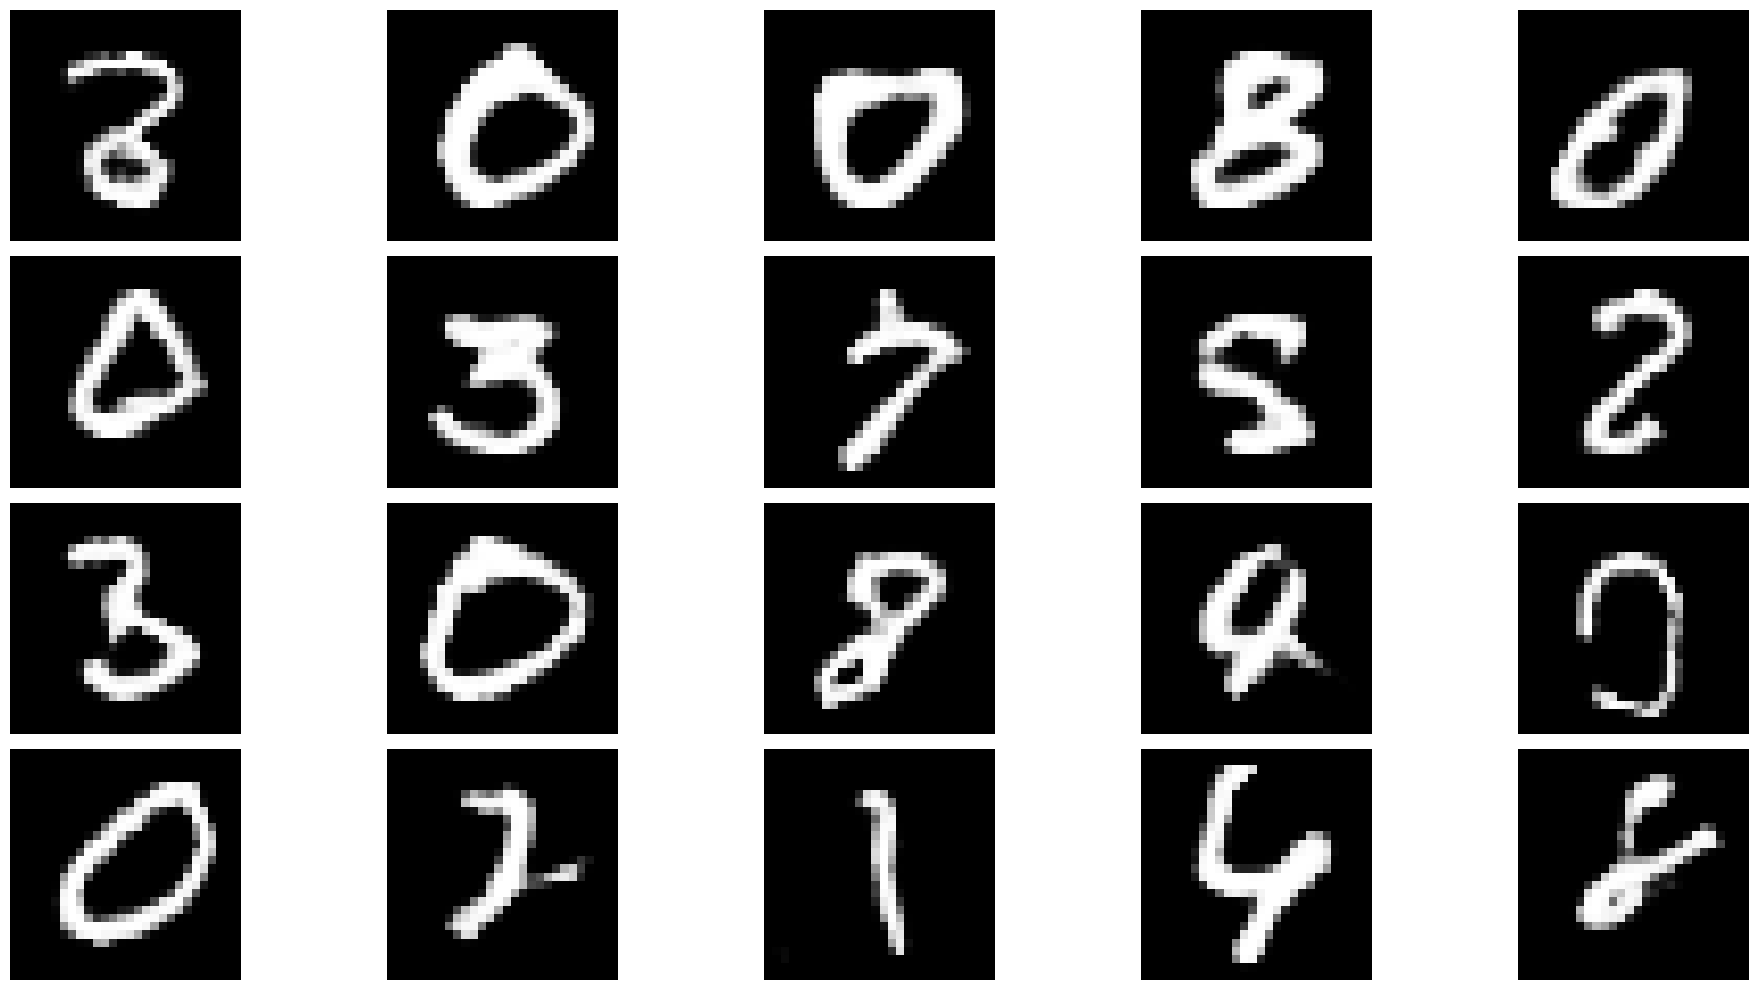

📈 Epoch 25 Summary:
   Train D Loss: 1.0470, Val D Loss: 1.2789
   Train G Loss: 1.0848, Val G Loss: 0.5850

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 1.132568	G_loss: 1.740536
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.998471	G_loss: 0.671800
Epoch: 26 [12800/60000 (21%)]	D_loss: 1.025913	G_loss: 1.283652
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.088155	G_loss: 0.736297
Epoch: 26 [25600/60000 (43%)]	D_loss: 1.075103	G_loss: 1.126348
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.883158	G_loss: 1.106746
Epoch: 26 [38400/60000 (64%)]	D_loss: 1.091070	G_loss: 1.283879
Epoch: 26 [44800/60000 (75%)]	D_loss: 1.012385	G_loss: 0.739588
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.945359	G_loss: 1.103681
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.950111	G_loss: 0.998874
====> Epoch: 26 Train D_loss: 1.0457, Train G_loss: 1.0936
====> Epoch: 26 Val D_loss: 1.4150, Val G_loss: 1.6414
📈 Epoch 26 Summary:
   Train D Loss: 1.0457, Val D Loss: 1.4150
   Train G Loss: 1.0936

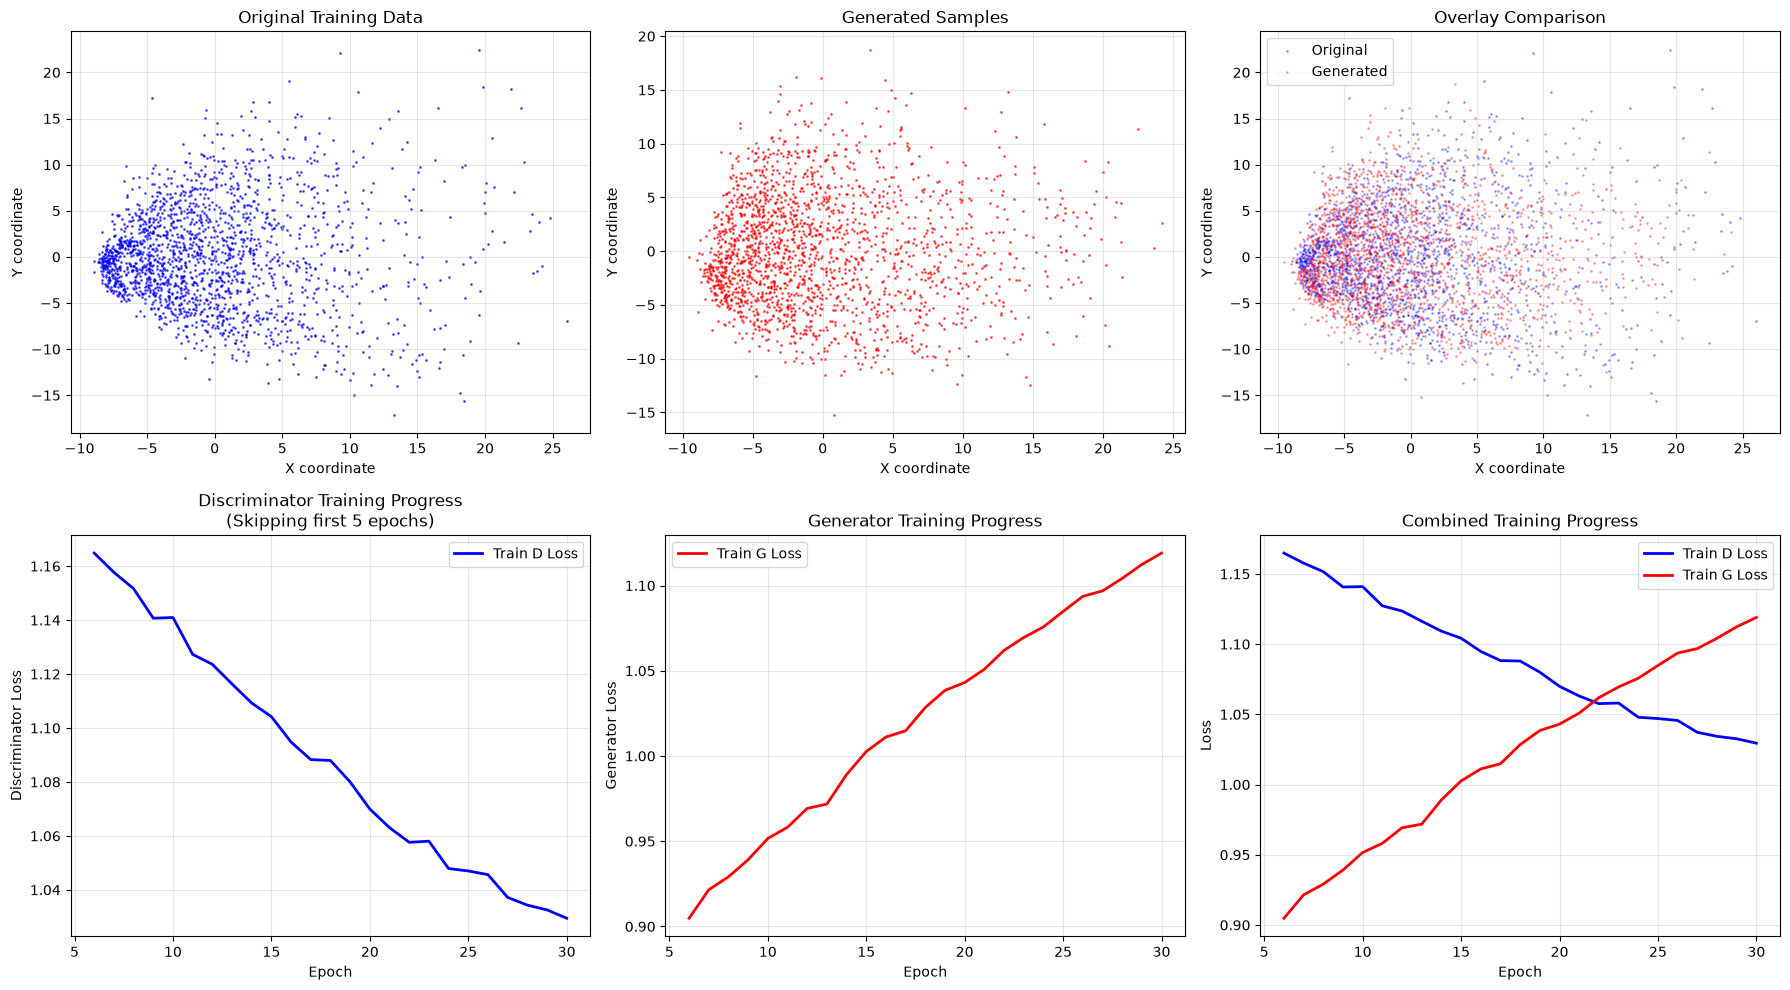

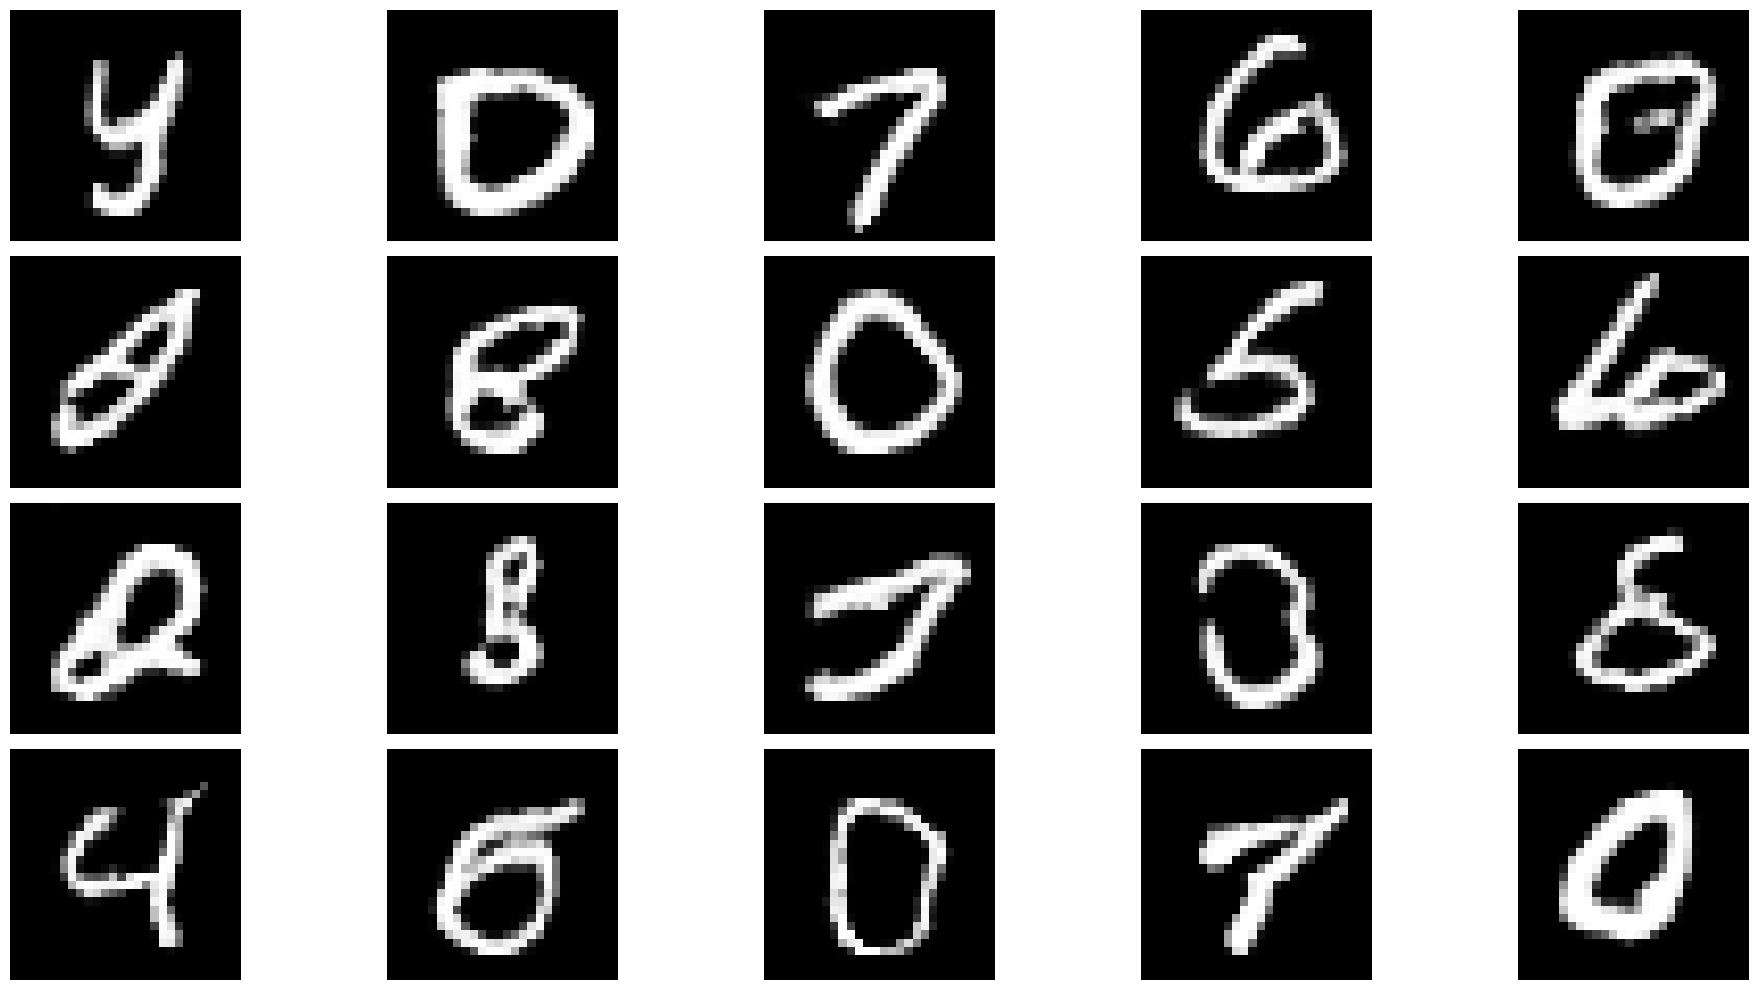

📈 Epoch 30 Summary:
   Train D Loss: 1.0295, Val D Loss: 1.2005
   Train G Loss: 1.1190, Val G Loss: 1.1427

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 1.056147	G_loss: 1.143034
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.011282	G_loss: 1.233314
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.963014	G_loss: 1.212261
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.959456	G_loss: 1.058275
Epoch: 31 [25600/60000 (43%)]	D_loss: 1.078951	G_loss: 0.766523
Epoch: 31 [32000/60000 (53%)]	D_loss: 1.006242	G_loss: 1.082471
Epoch: 31 [38400/60000 (64%)]	D_loss: 1.054856	G_loss: 0.863935
Epoch: 31 [44800/60000 (75%)]	D_loss: 1.137382	G_loss: 1.050649
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.962022	G_loss: 1.191255
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.933367	G_loss: 1.193933
====> Epoch: 31 Train D_loss: 1.0235, Train G_loss: 1.1230
====> Epoch: 31 Val D_loss: 1.4503, Val G_loss: 1.7655
📈 Epoch 31 Summary:
   Train D Loss: 1.0235, Val D Loss: 1.4503
   Train G Loss: 1.1230

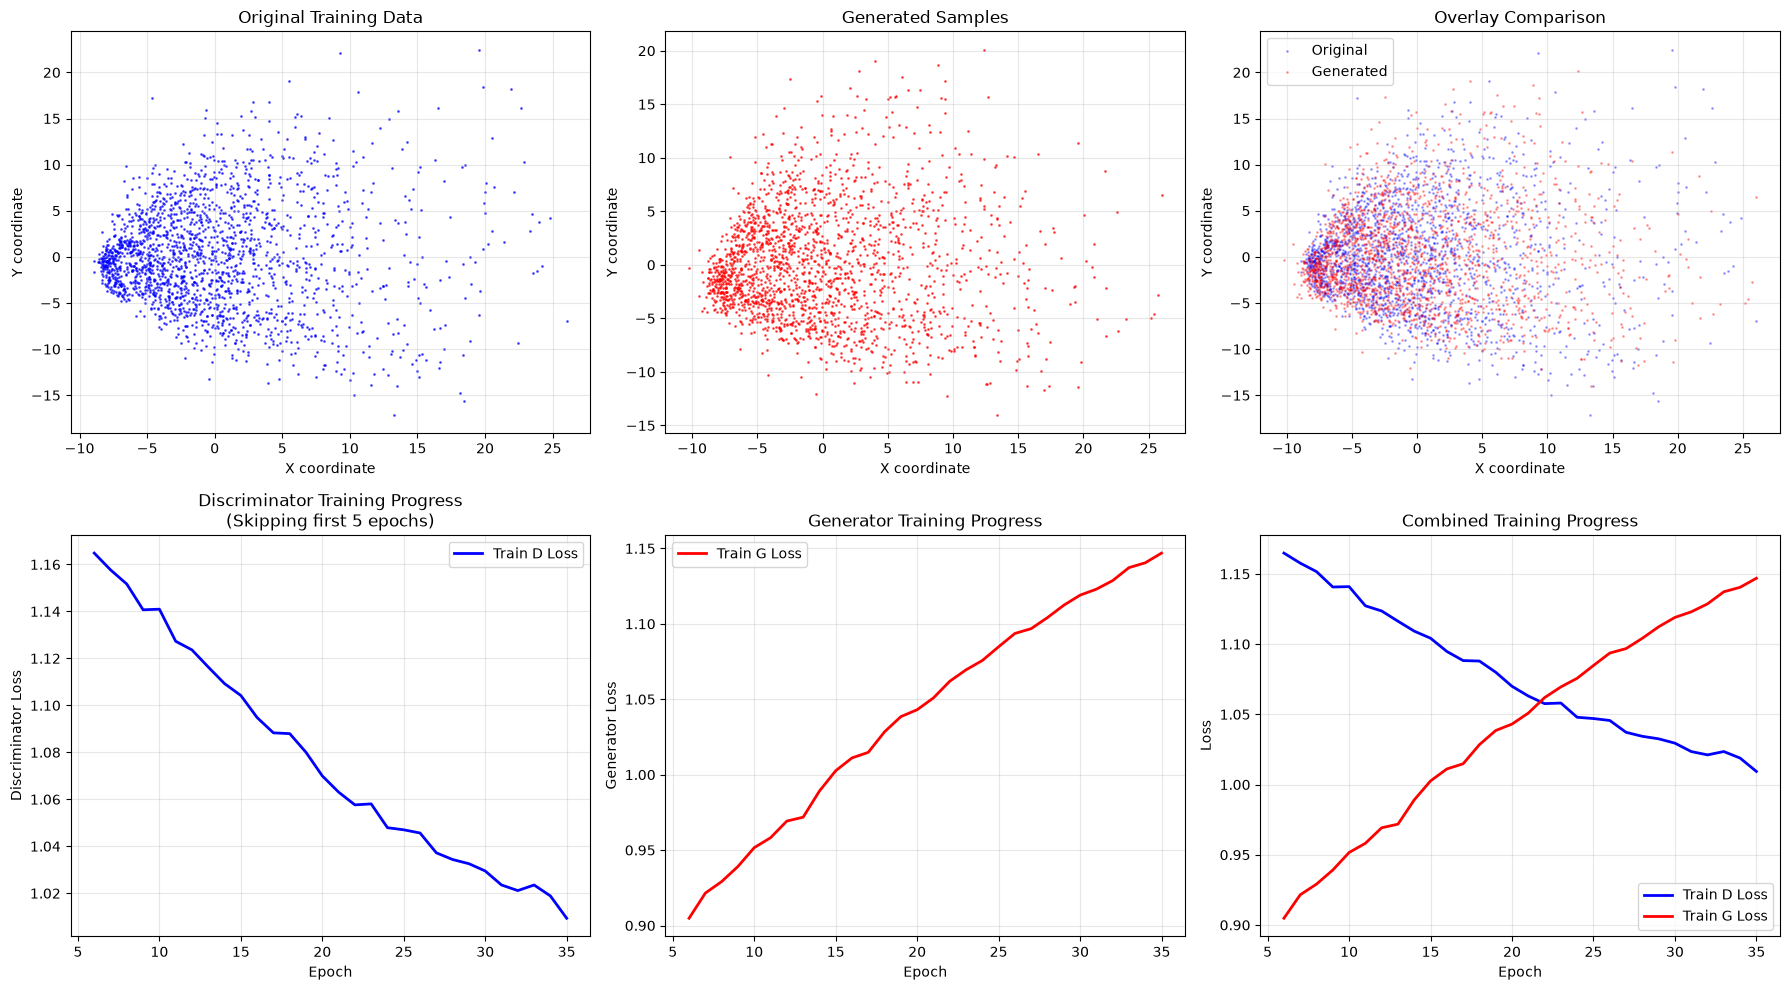

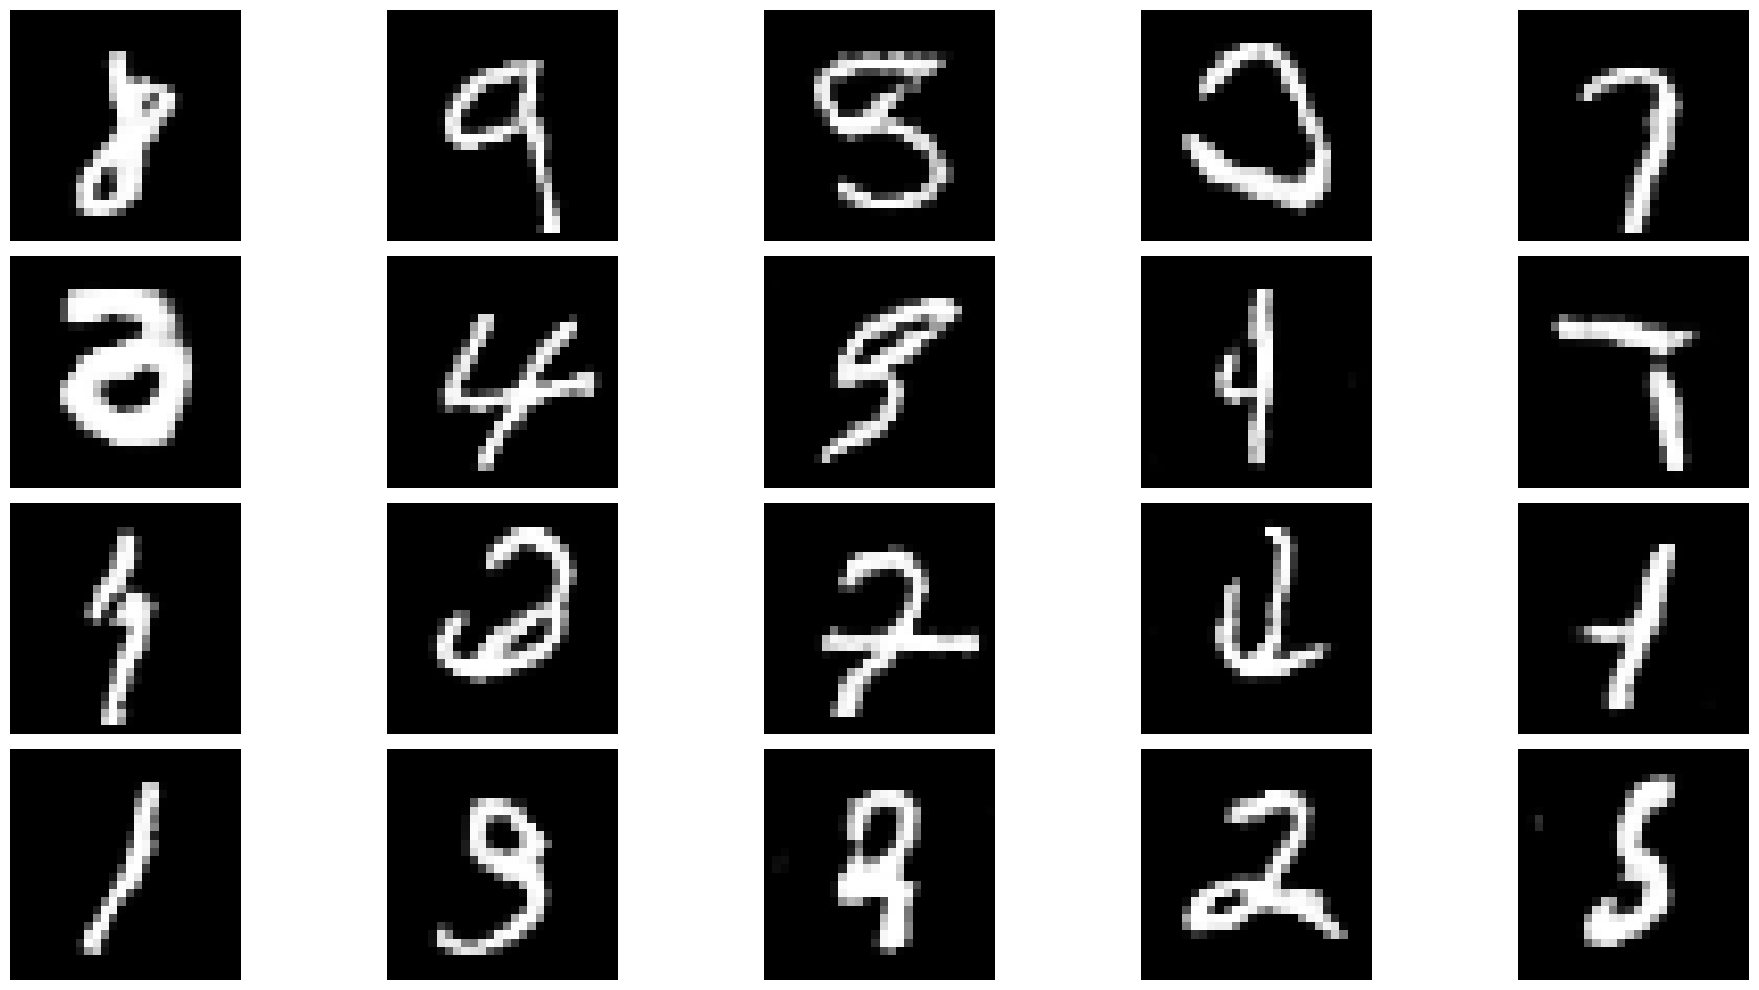

📈 Epoch 35 Summary:
   Train D Loss: 1.0094, Val D Loss: 1.1704
   Train G Loss: 1.1469, Val G Loss: 1.0975

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.929974	G_loss: 1.196527
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.903726	G_loss: 0.749067
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.996968	G_loss: 1.408101
Epoch: 36 [19200/60000 (32%)]	D_loss: 1.191152	G_loss: 1.805121
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.966920	G_loss: 1.498192
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.902583	G_loss: 1.191843
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.907698	G_loss: 1.361861
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.943803	G_loss: 1.207993
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.994363	G_loss: 0.888293
Epoch: 36 [57600/60000 (96%)]	D_loss: 1.044532	G_loss: 1.473333
====> Epoch: 36 Train D_loss: 1.0105, Train G_loss: 1.1488
====> Epoch: 36 Val D_loss: 1.1806, Val G_loss: 1.0009
📈 Epoch 36 Summary:
   Train D Loss: 1.0105, Val D Loss: 1.1806
   Train G Loss: 1.1488

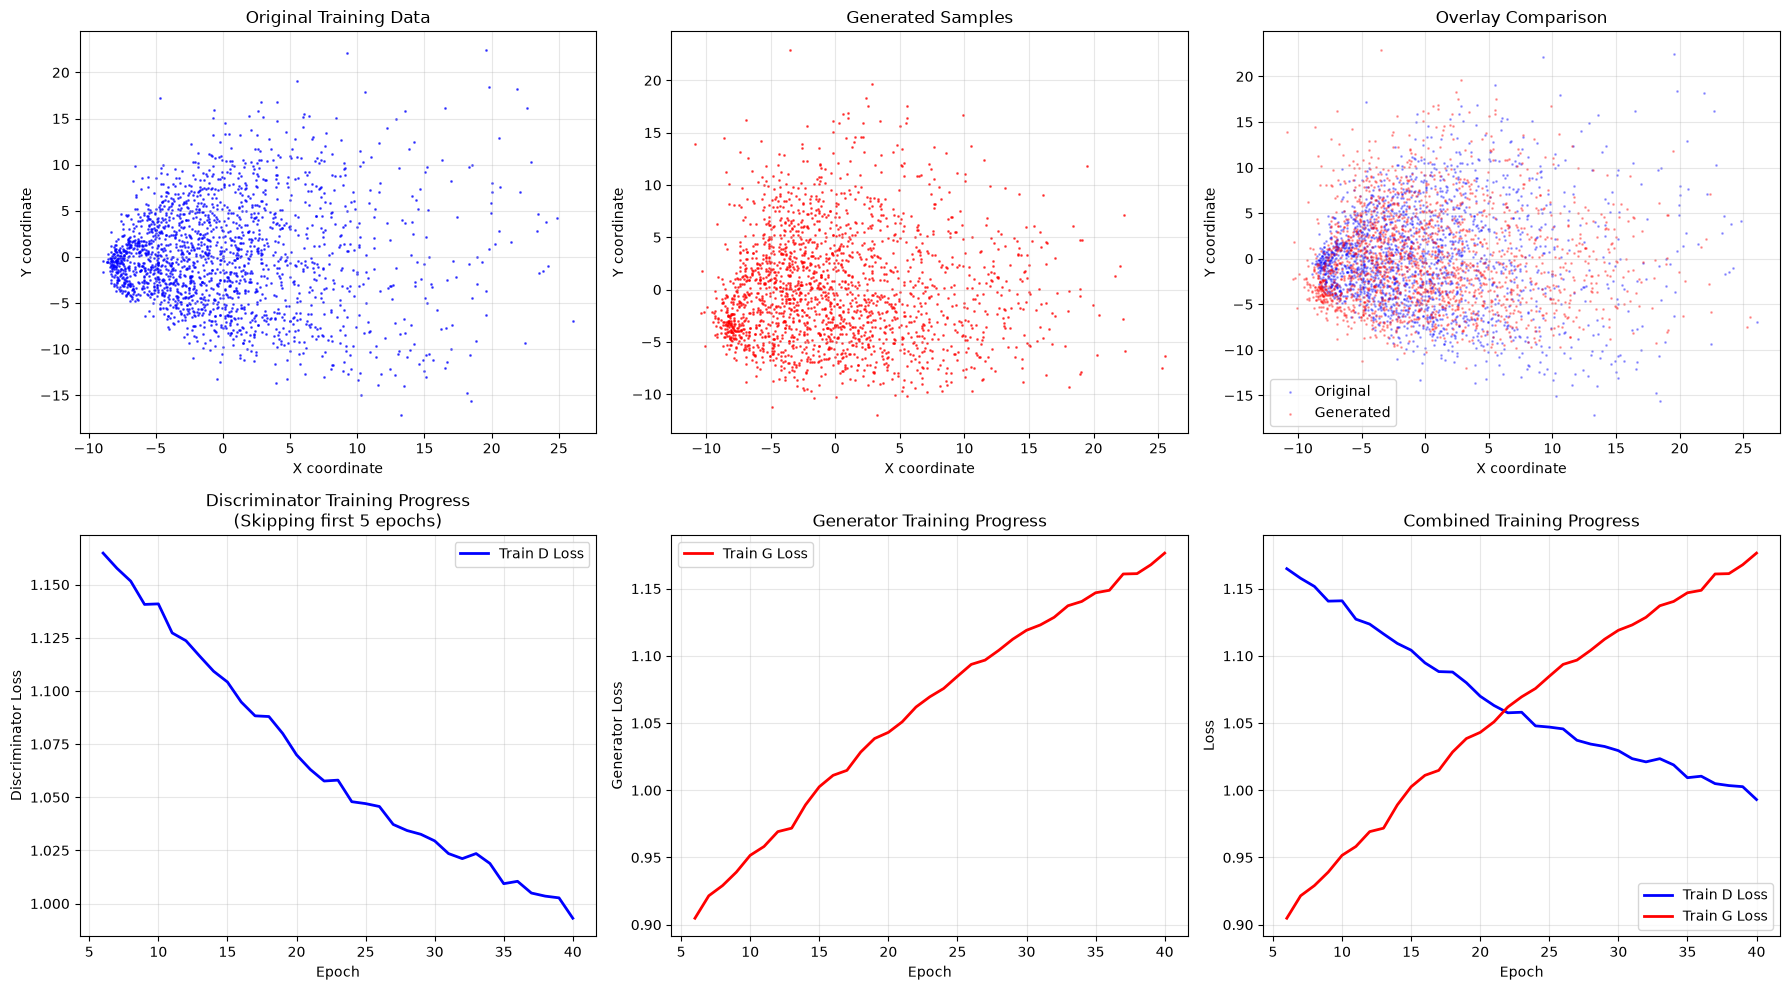

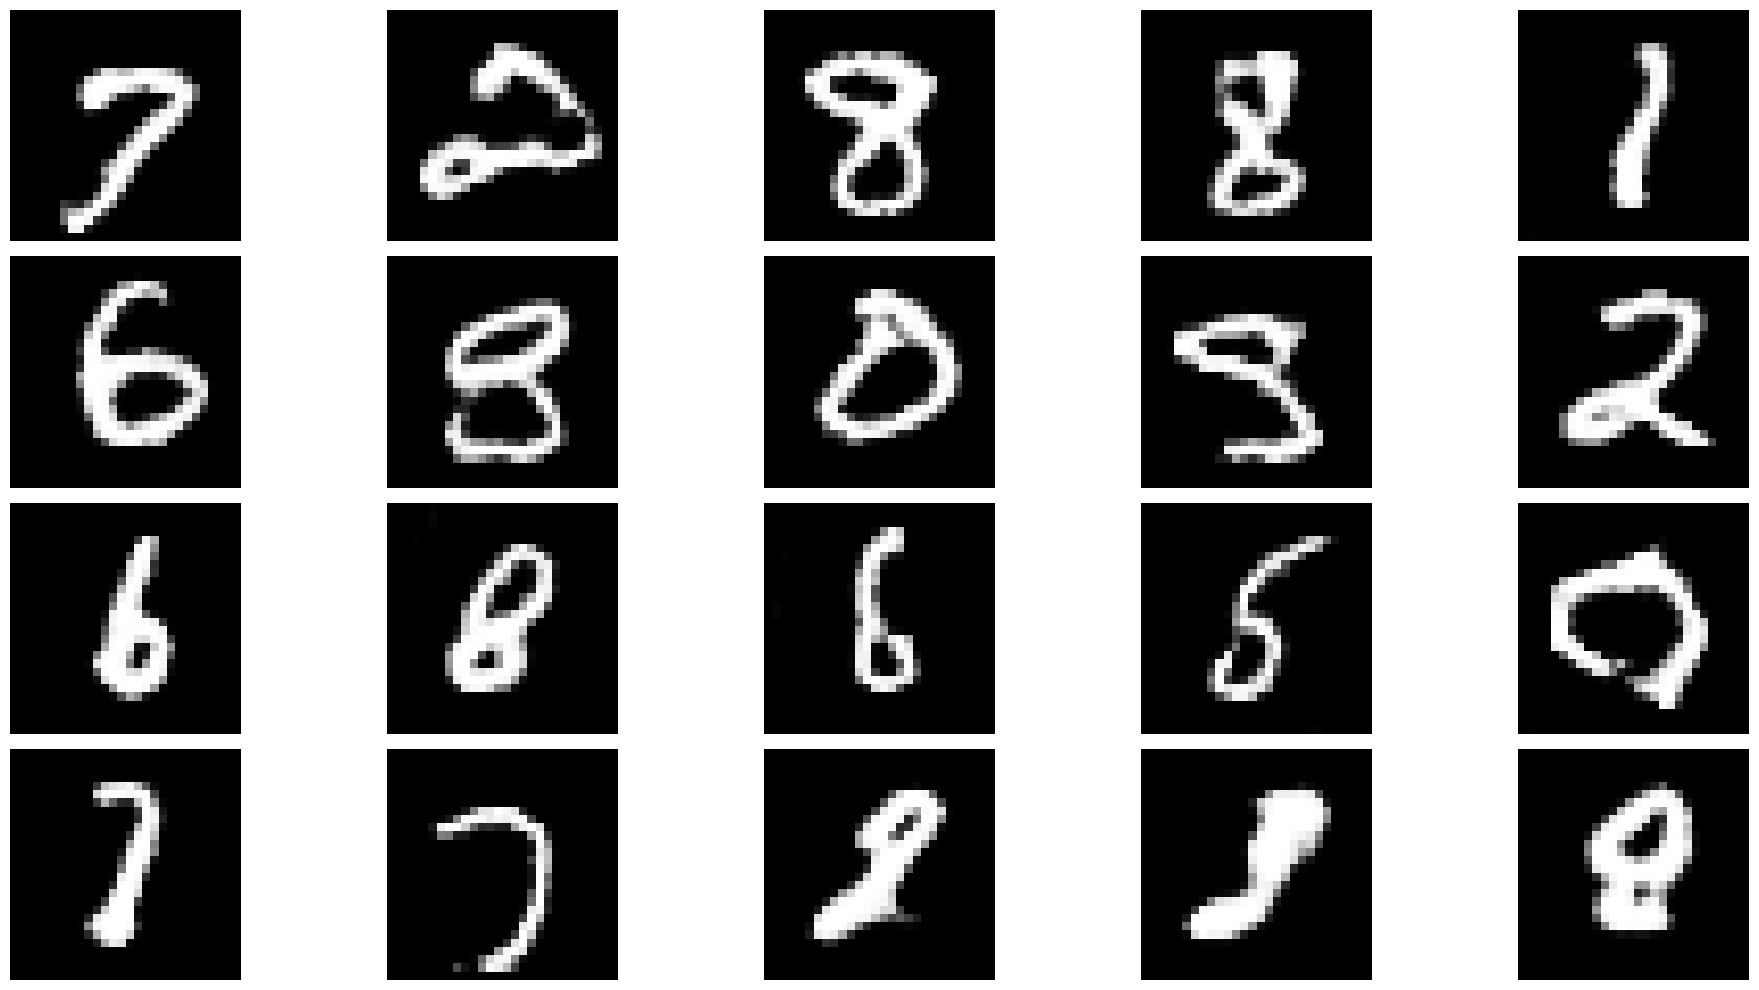

📈 Epoch 40 Summary:
   Train D Loss: 0.9931, Val D Loss: 1.2525
   Train G Loss: 1.1764, Val G Loss: 0.6308

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.985208	G_loss: 1.771472
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.893745	G_loss: 1.263737
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.956581	G_loss: 1.417123
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.964707	G_loss: 1.237713
Epoch: 41 [25600/60000 (43%)]	D_loss: 1.209823	G_loss: 0.419065
Epoch: 41 [32000/60000 (53%)]	D_loss: 1.089369	G_loss: 1.801144
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.982549	G_loss: 1.794625
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.857453	G_loss: 1.044606
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.946662	G_loss: 1.423059
Epoch: 41 [57600/60000 (96%)]	D_loss: 1.004861	G_loss: 0.974761
====> Epoch: 41 Train D_loss: 0.9905, Train G_loss: 1.1804
====> Epoch: 41 Val D_loss: 1.1551, Val G_loss: 0.8562
📈 Epoch 41 Summary:
   Train D Loss: 0.9905, Val D Loss: 1.1551
   Train G Loss: 1.1804

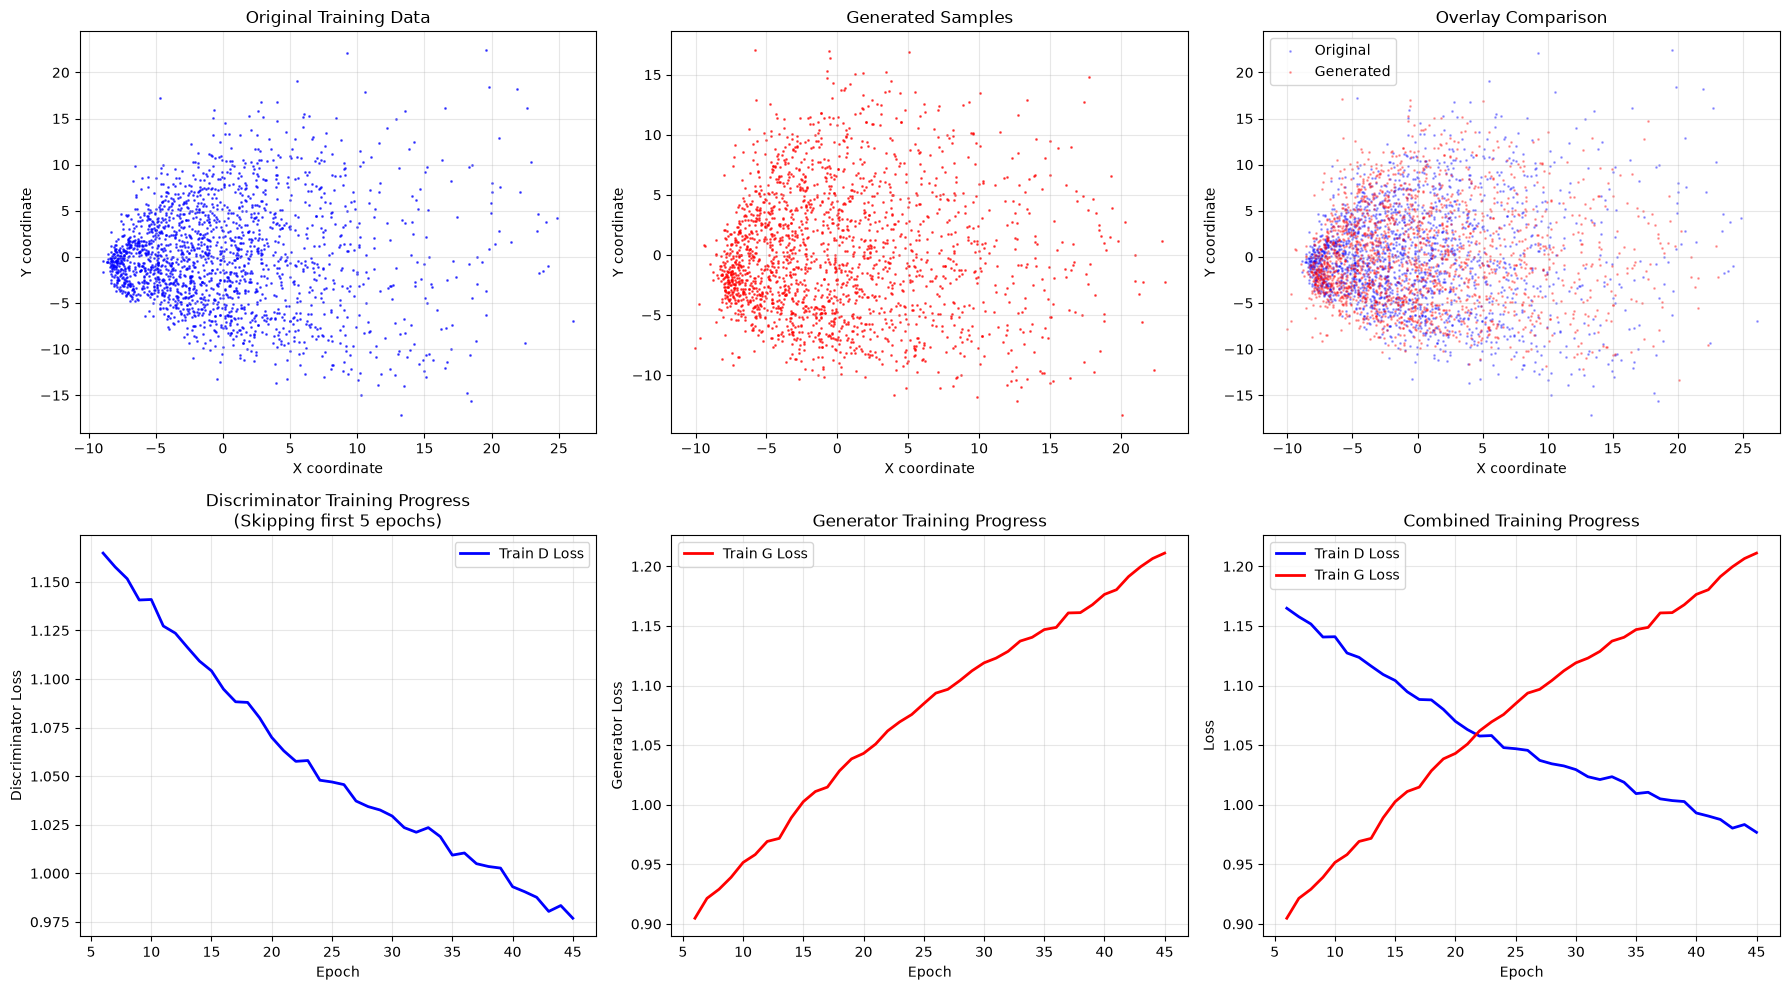

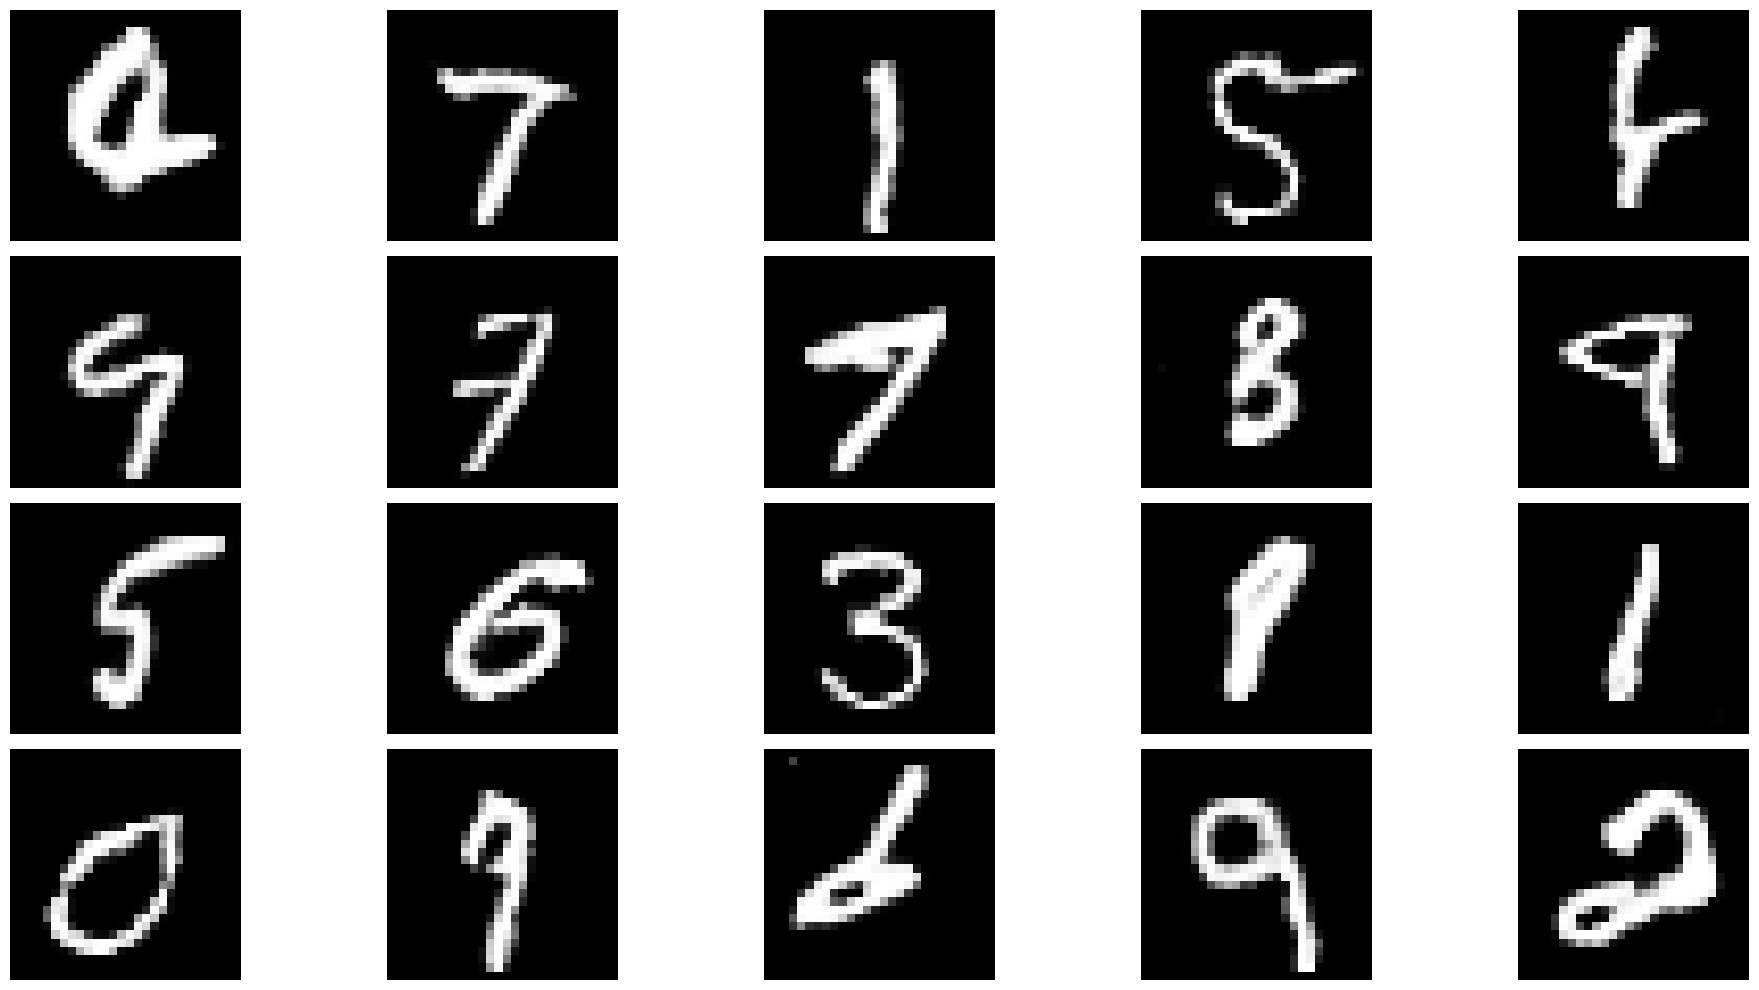

📈 Epoch 45 Summary:
   Train D Loss: 0.9769, Val D Loss: 1.4204
   Train G Loss: 1.2111, Val G Loss: 1.7963

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 1.034348	G_loss: 0.694444
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.979761	G_loss: 1.544390
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.959817	G_loss: 0.996131
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.956576	G_loss: 1.225636
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.866835	G_loss: 1.341049
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.979897	G_loss: 1.396670
Epoch: 46 [38400/60000 (64%)]	D_loss: 1.050607	G_loss: 2.353128
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.904653	G_loss: 1.314860
Epoch: 46 [51200/60000 (85%)]	D_loss: 1.008844	G_loss: 1.360534
Epoch: 46 [57600/60000 (96%)]	D_loss: 1.063430	G_loss: 1.689208
====> Epoch: 46 Train D_loss: 0.9759, Train G_loss: 1.2113
====> Epoch: 46 Val D_loss: 1.1392, Val G_loss: 1.0518
📈 Epoch 46 Summary:
   Train D Loss: 0.9759, Val D Loss: 1.1392
   Train G Loss: 1.2113

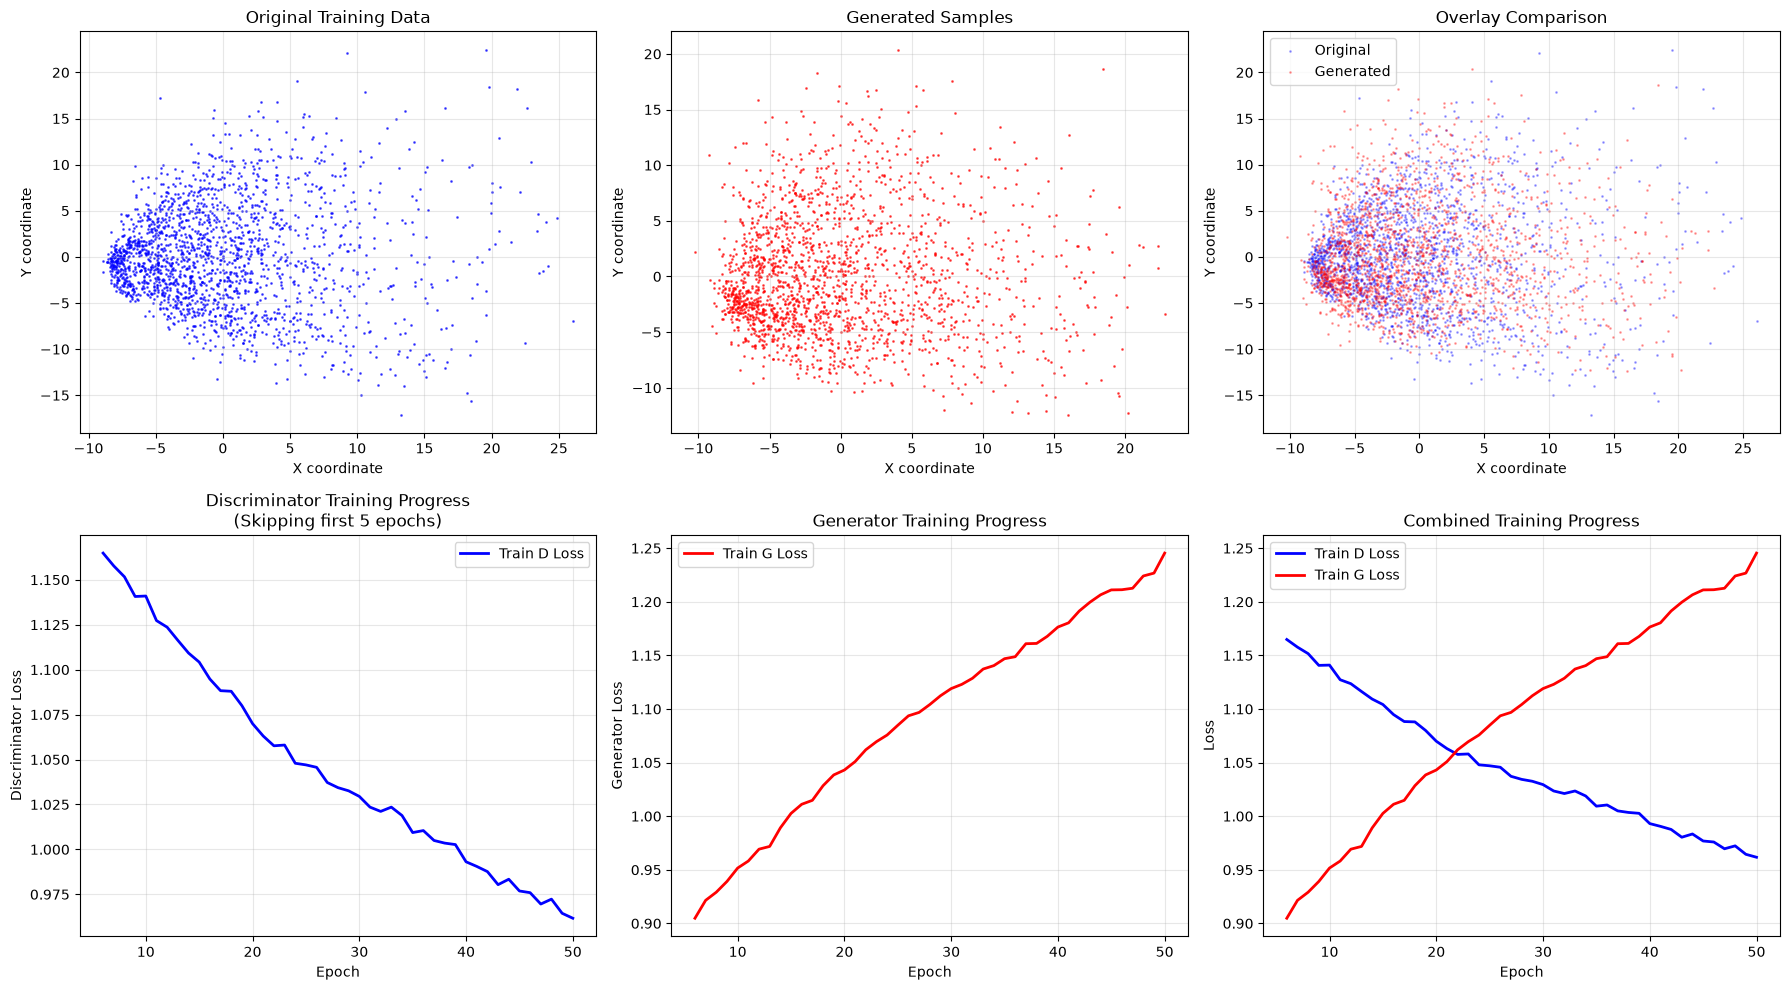

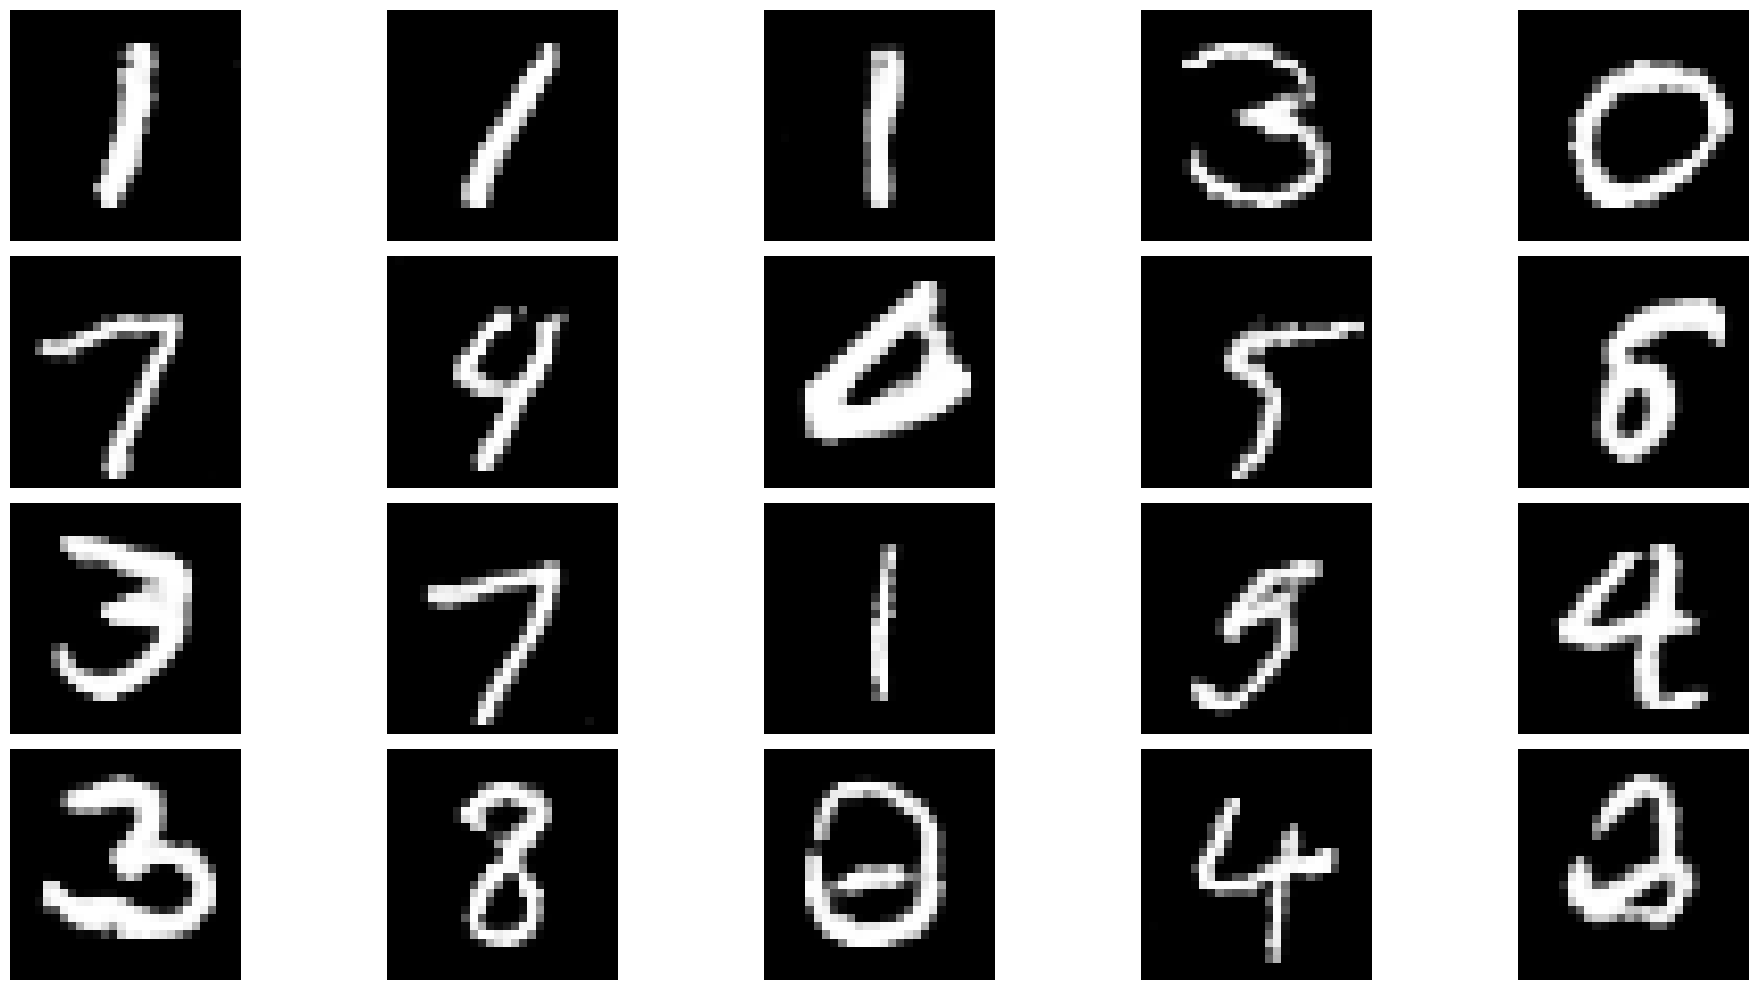

📈 Epoch 50 Summary:
   Train D Loss: 0.9617, Val D Loss: 1.2863
   Train G Loss: 1.2454, Val G Loss: 1.5871

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.942870	G_loss: 0.789192
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.902685	G_loss: 1.397472
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.855786	G_loss: 0.996174
Epoch: 51 [19200/60000 (32%)]	D_loss: 1.037315	G_loss: 1.743980
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.981154	G_loss: 0.916854
Epoch: 51 [32000/60000 (53%)]	D_loss: 1.011413	G_loss: 0.949121
Epoch: 51 [38400/60000 (64%)]	D_loss: 1.011333	G_loss: 1.289875
Epoch: 51 [44800/60000 (75%)]	D_loss: 1.005727	G_loss: 1.459151
Epoch: 51 [51200/60000 (85%)]	D_loss: 1.016085	G_loss: 1.276185
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.998579	G_loss: 1.742958
====> Epoch: 51 Train D_loss: 0.9576, Train G_loss: 1.2467
====> Epoch: 51 Val D_loss: 1.1921, Val G_loss: 0.7484
📈 Epoch 51 Summary:
   Train D Loss: 0.9576, Val D Loss: 1.1921
   Train G Loss: 1.2467

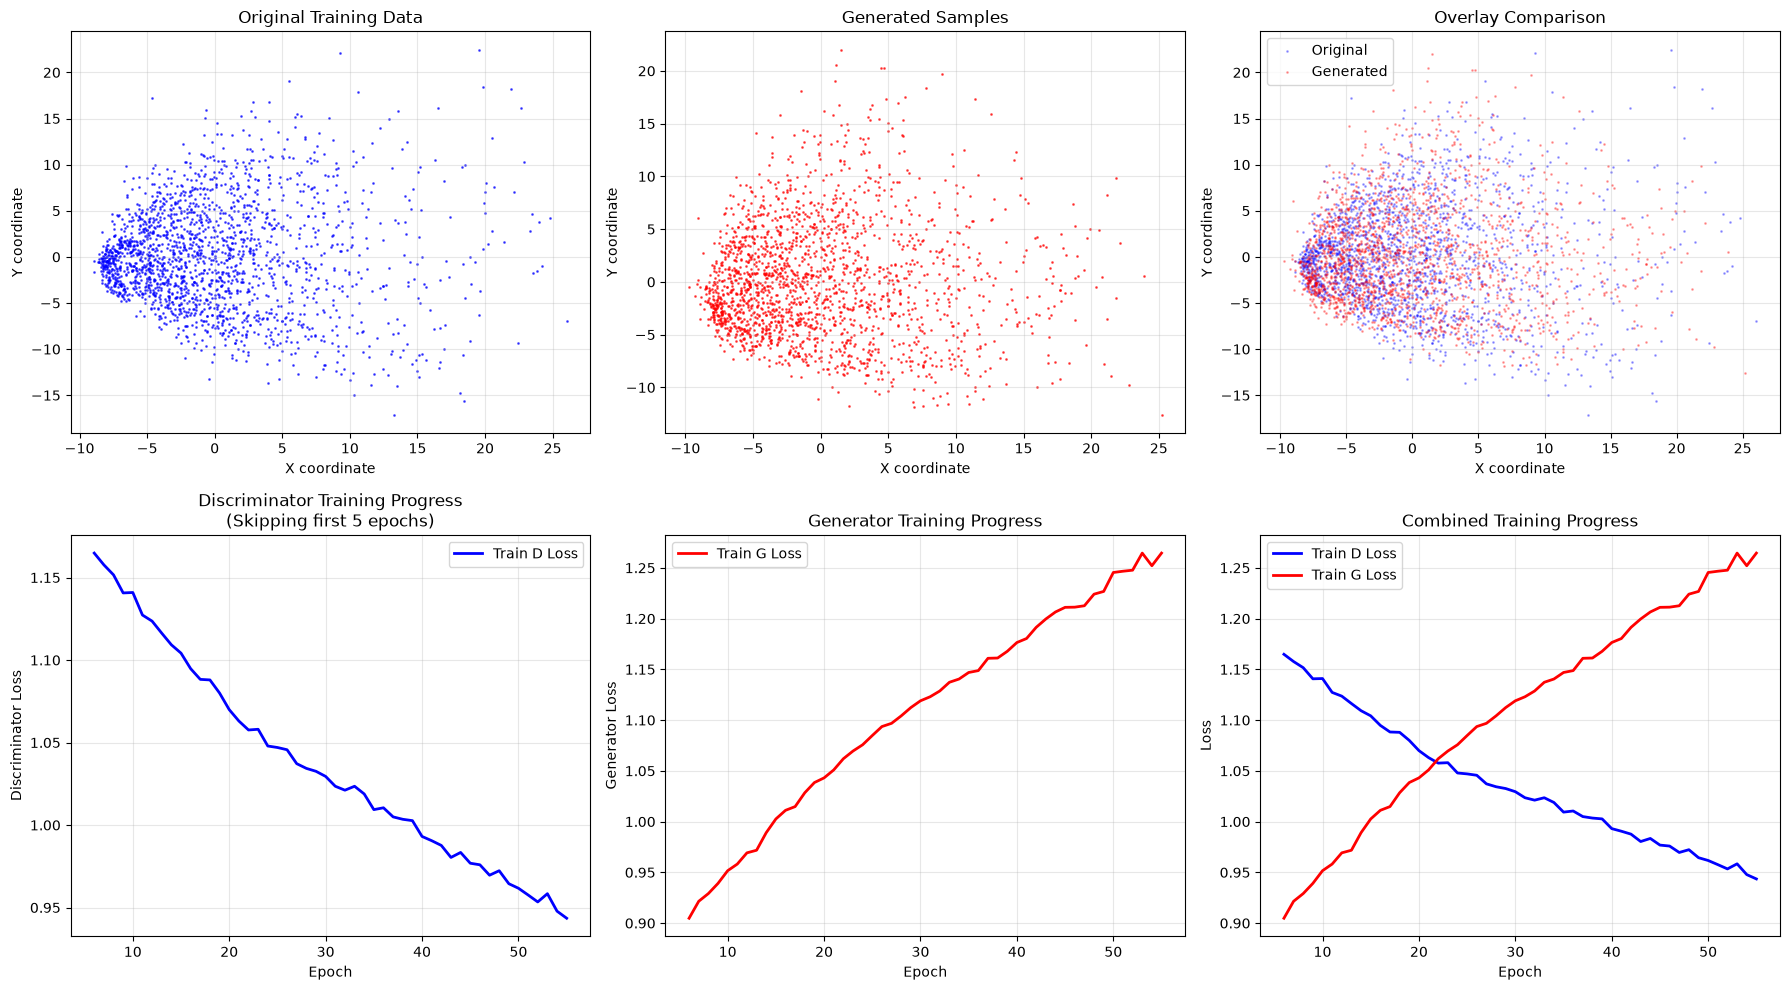

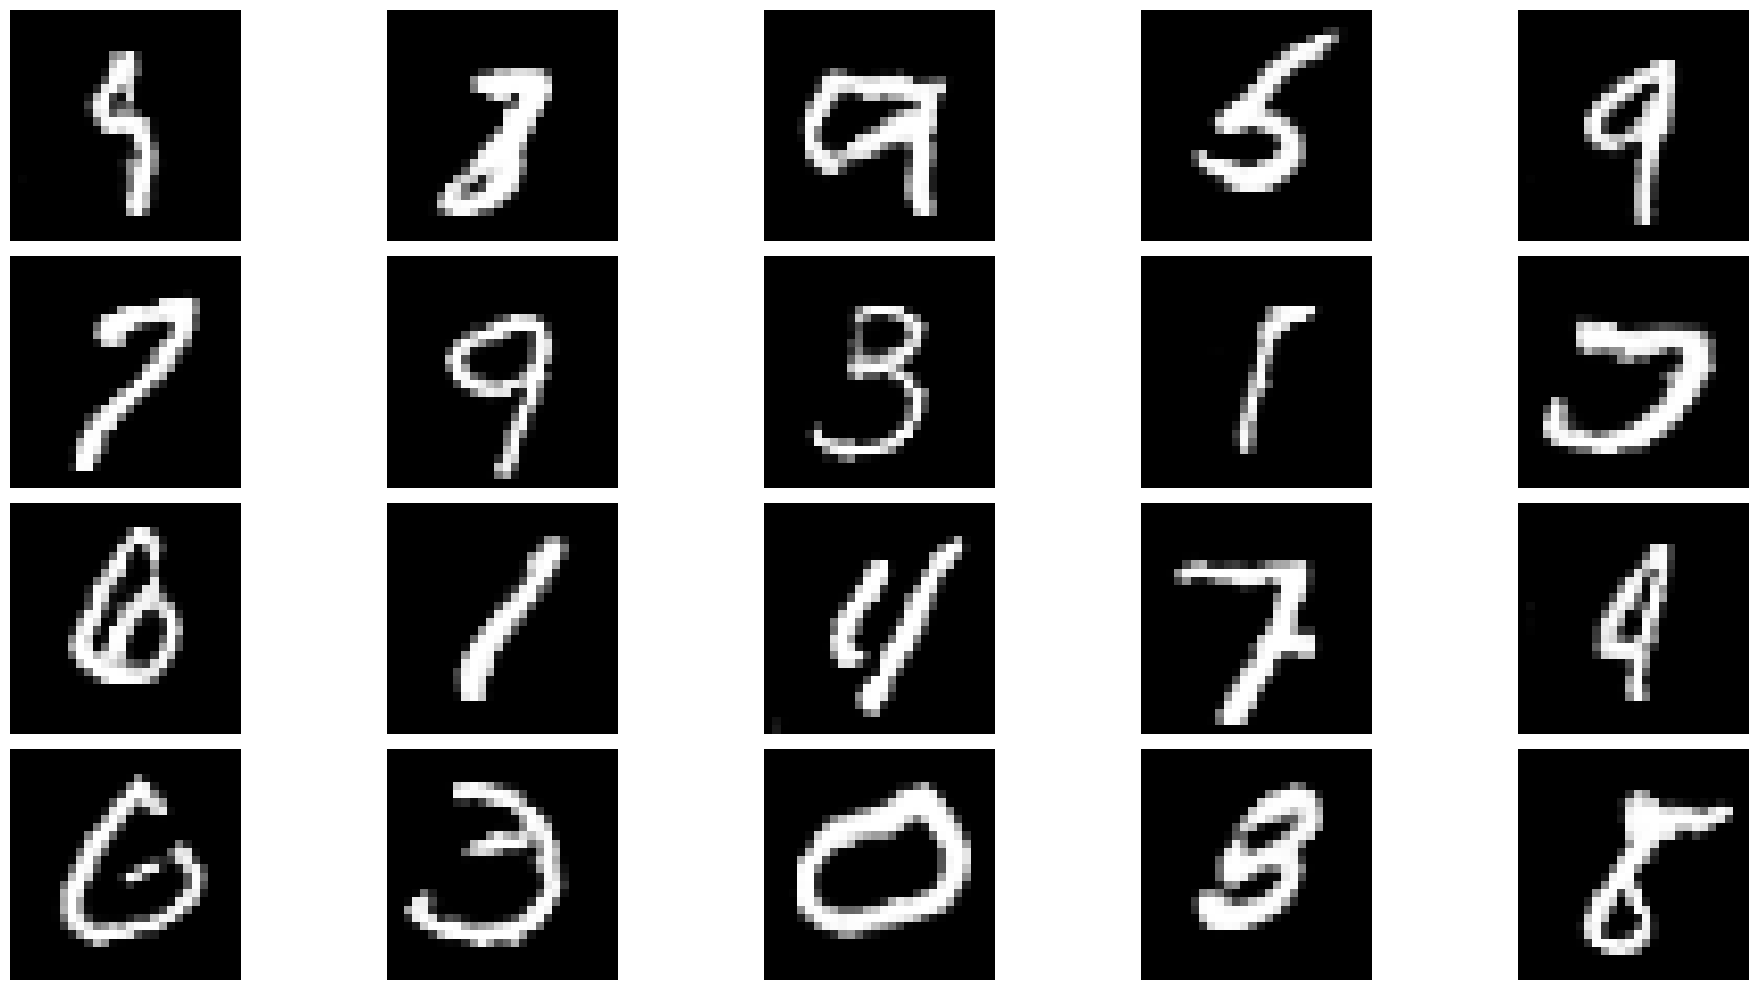

📈 Epoch 55 Summary:
   Train D Loss: 0.9435, Val D Loss: 1.1412
   Train G Loss: 1.2645, Val G Loss: 1.0344

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.864908	G_loss: 1.174449
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.979985	G_loss: 0.738855
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.927077	G_loss: 1.329301
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.989379	G_loss: 1.027023
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.918610	G_loss: 1.069522
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.921734	G_loss: 1.227569
Epoch: 56 [38400/60000 (64%)]	D_loss: 1.227232	G_loss: 0.385759
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.899387	G_loss: 1.207262
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.950814	G_loss: 1.403427
Epoch: 56 [57600/60000 (96%)]	D_loss: 1.169418	G_loss: 0.407864
====> Epoch: 56 Train D_loss: 0.9443, Train G_loss: 1.2714
====> Epoch: 56 Val D_loss: 1.1699, Val G_loss: 0.8204
📈 Epoch 56 Summary:
   Train D Loss: 0.9443, Val D Loss: 1.1699
   Train G Loss: 1.2714

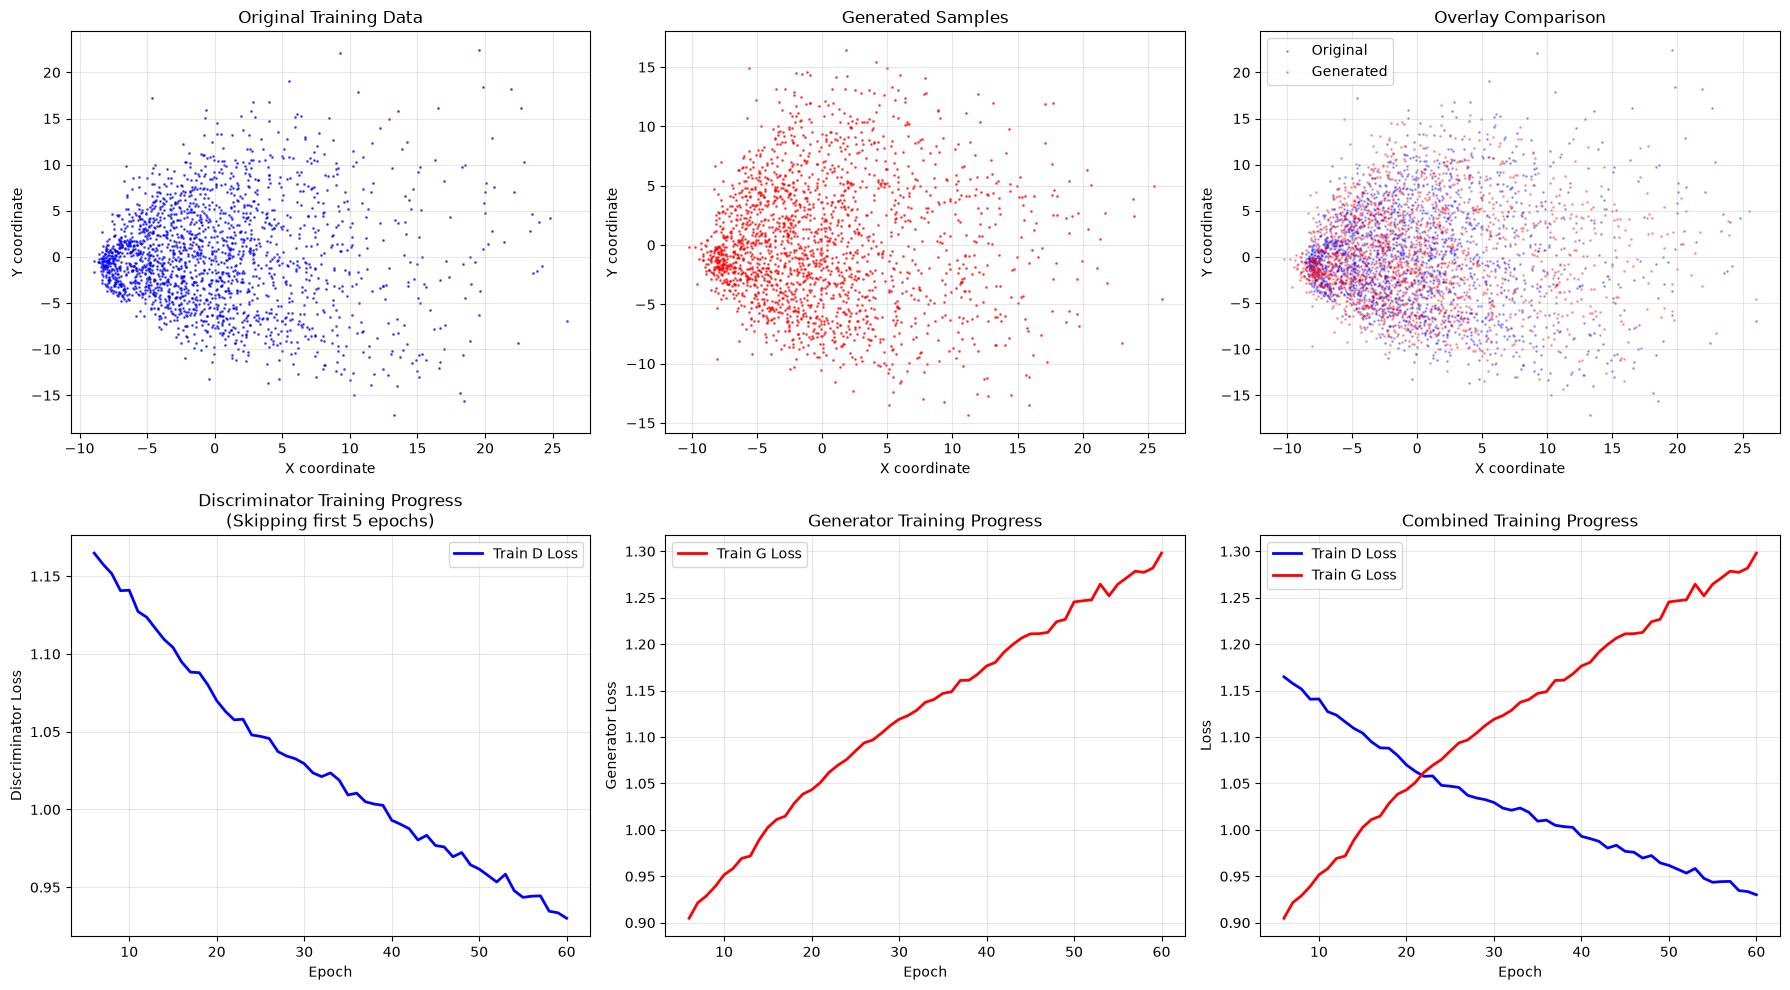

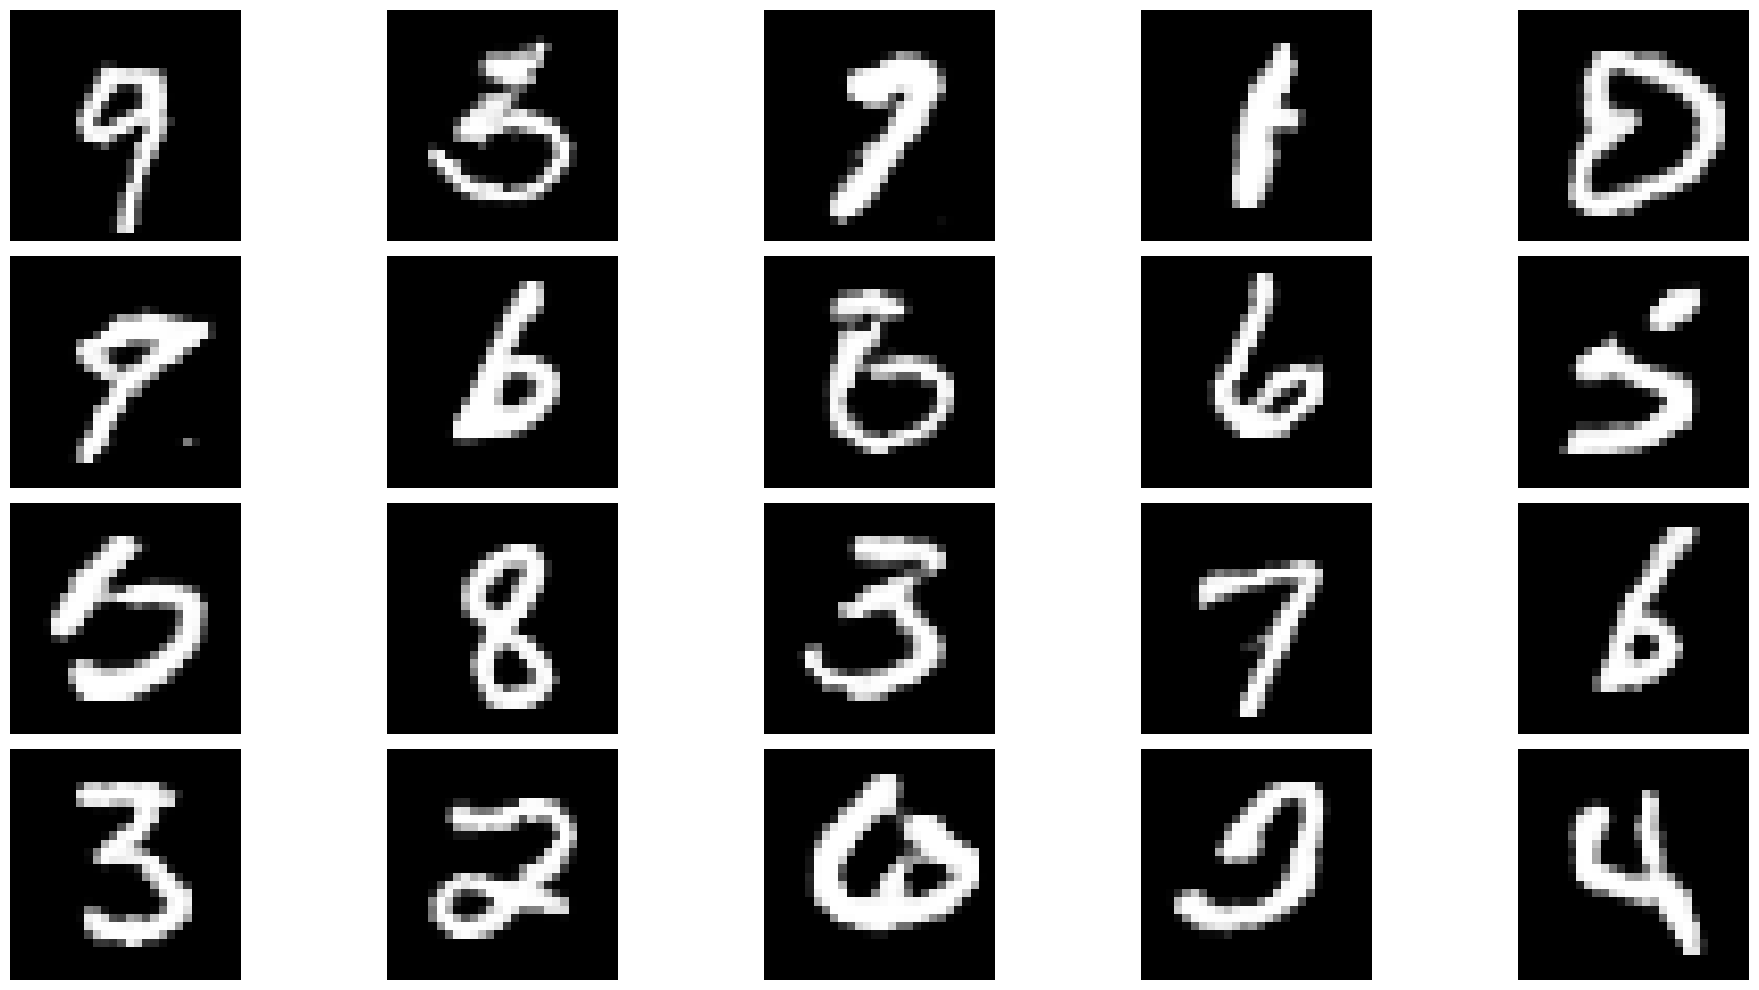

📈 Epoch 60 Summary:
   Train D Loss: 0.9301, Val D Loss: 1.1679
   Train G Loss: 1.2980, Val G Loss: 1.2135

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.925356	G_loss: 1.670257
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.869506	G_loss: 1.050624
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.977132	G_loss: 0.911616
Epoch: 61 [19200/60000 (32%)]	D_loss: 1.015048	G_loss: 1.257555
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.944827	G_loss: 1.042593
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.894526	G_loss: 0.905211
Epoch: 61 [38400/60000 (64%)]	D_loss: 1.001171	G_loss: 0.897177
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.939446	G_loss: 1.017840
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.902829	G_loss: 1.112815
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.895766	G_loss: 1.351961
====> Epoch: 61 Train D_loss: 0.9288, Train G_loss: 1.3054
====> Epoch: 61 Val D_loss: 1.1269, Val G_loss: 0.9317
📈 Epoch 61 Summary:
   Train D Loss: 0.9288, Val D Loss: 1.1269
   Train G Loss: 1.3054

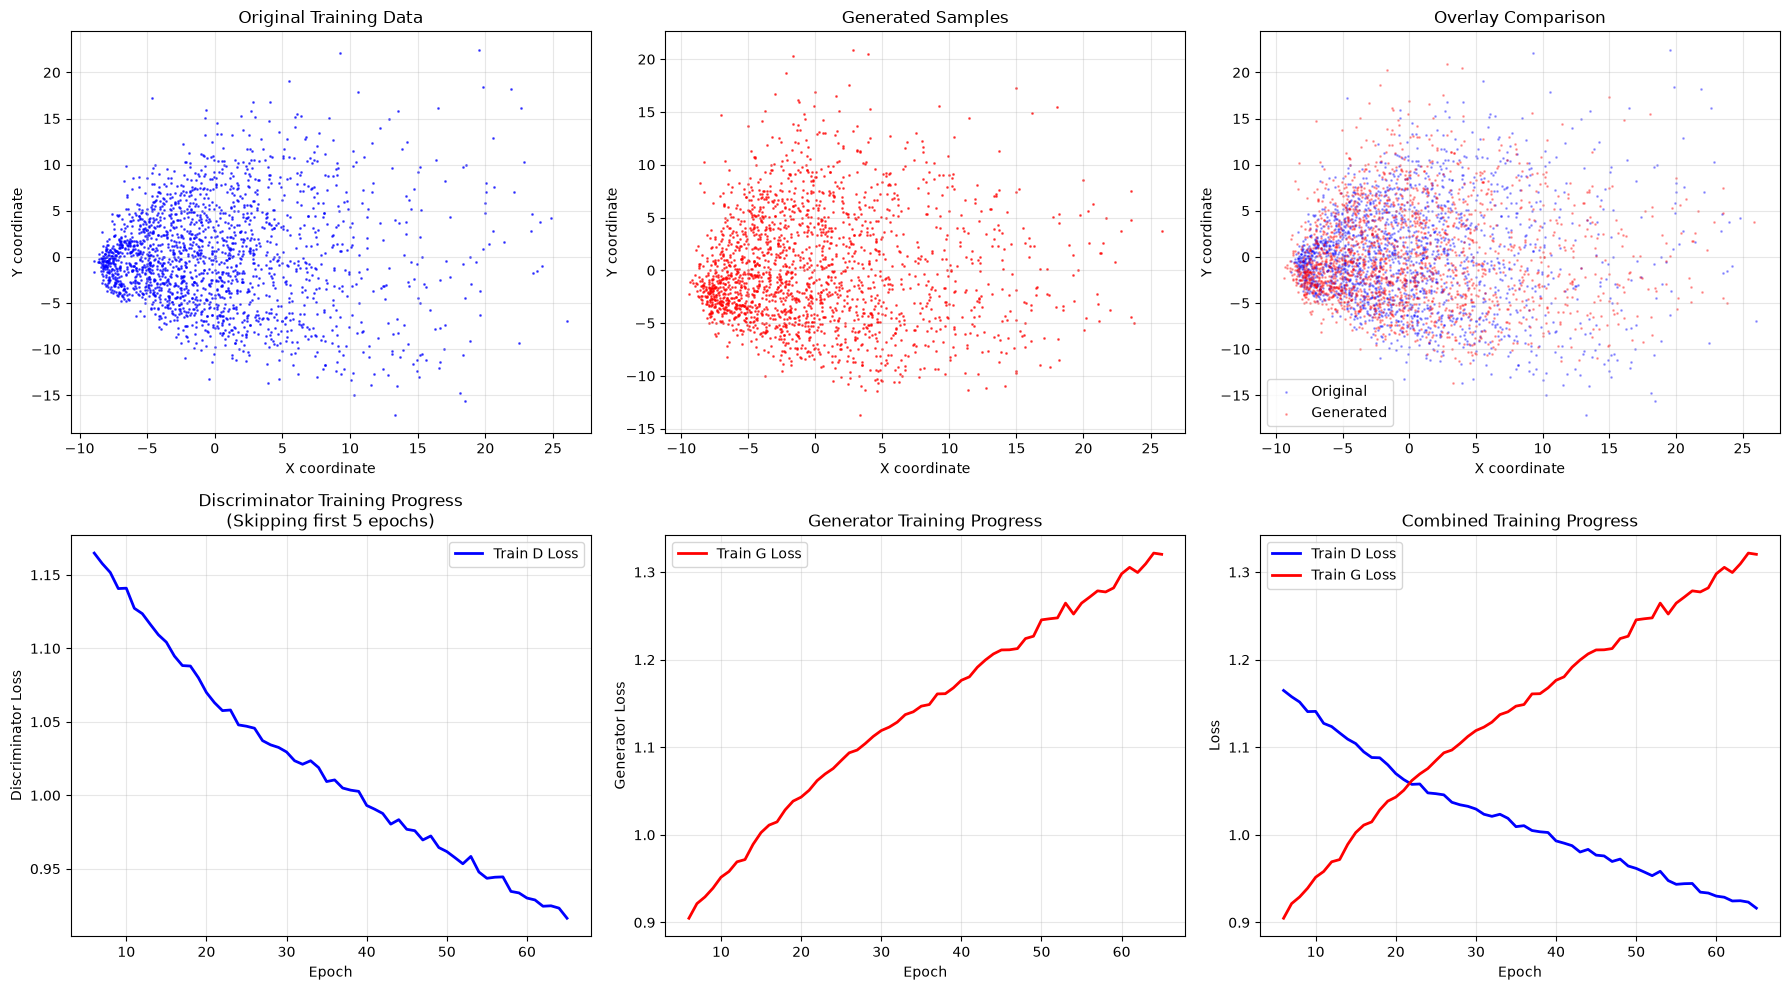

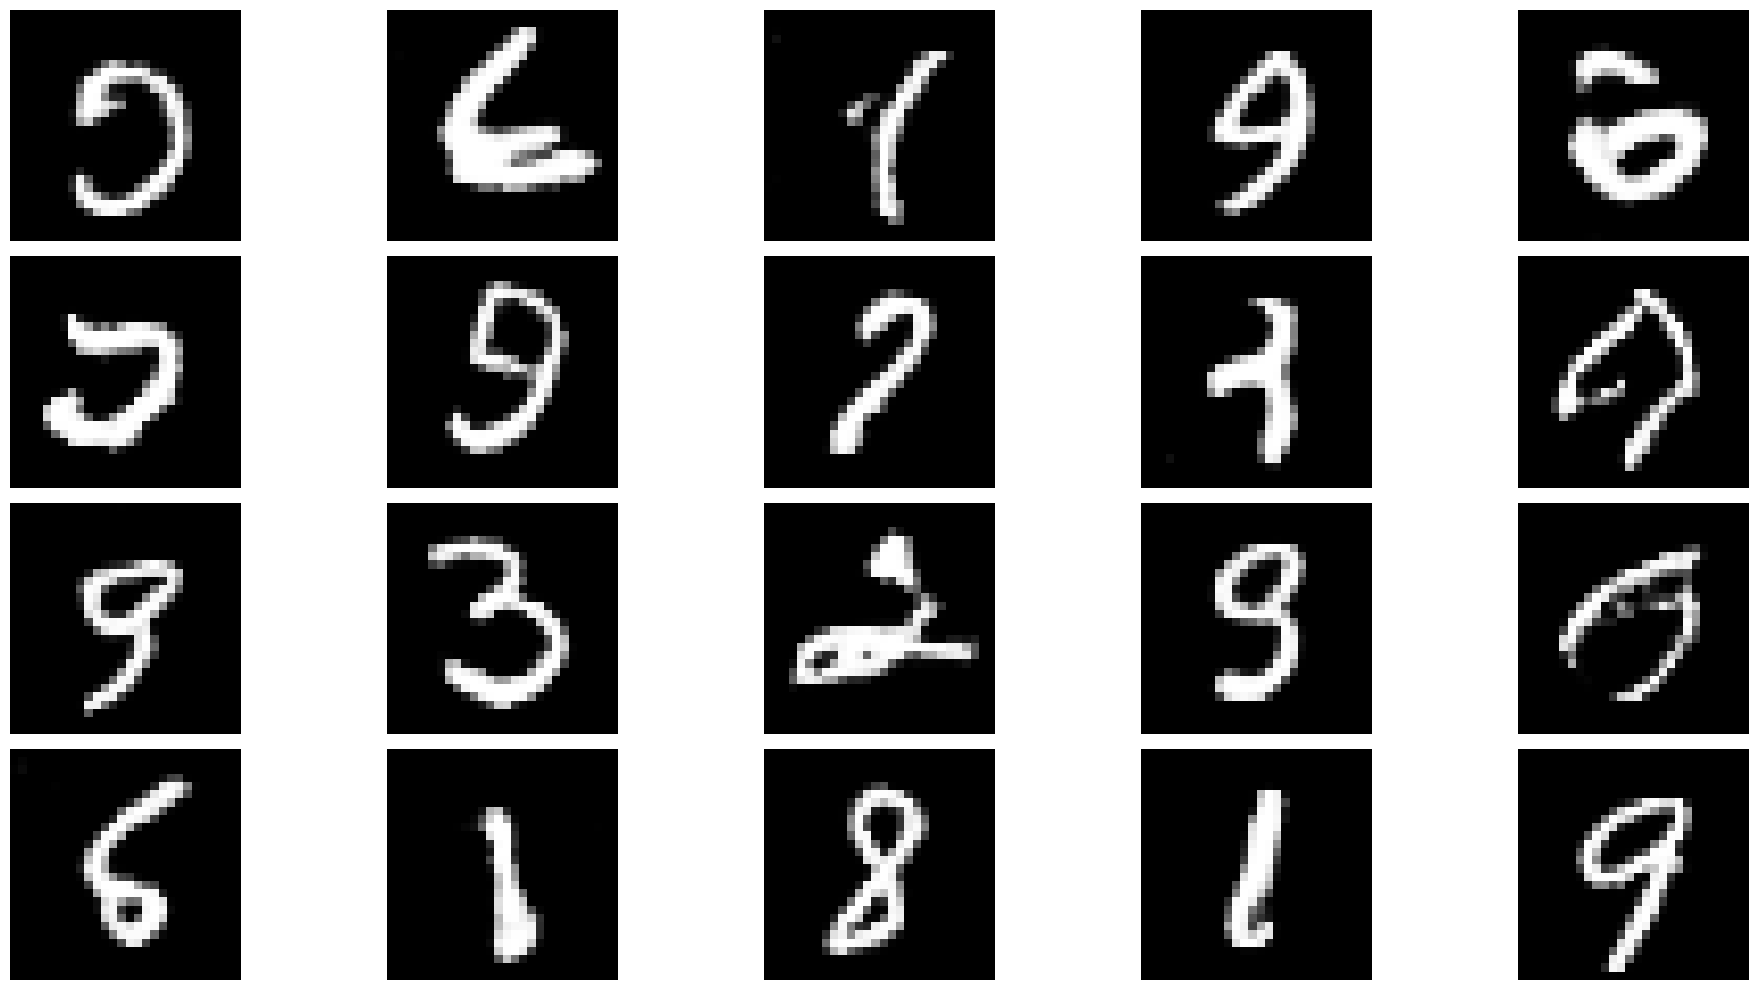

📈 Epoch 65 Summary:
   Train D Loss: 0.9163, Val D Loss: 1.1372
   Train G Loss: 1.3202, Val G Loss: 1.2077

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.912014	G_loss: 1.184817
Epoch: 66 [6400/60000 (11%)]	D_loss: 1.004442	G_loss: 0.796391
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.787243	G_loss: 1.125434
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.913326	G_loss: 1.915052
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.943073	G_loss: 1.189425
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.939775	G_loss: 1.051165
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.844737	G_loss: 1.970838
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.969328	G_loss: 1.143541
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.885543	G_loss: 1.230694
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.836874	G_loss: 1.190804
====> Epoch: 66 Train D_loss: 0.9170, Train G_loss: 1.3267
====> Epoch: 66 Val D_loss: 1.2073, Val G_loss: 1.4965
📈 Epoch 66 Summary:
   Train D Loss: 0.9170, Val D Loss: 1.2073
   Train G Loss: 1.3267

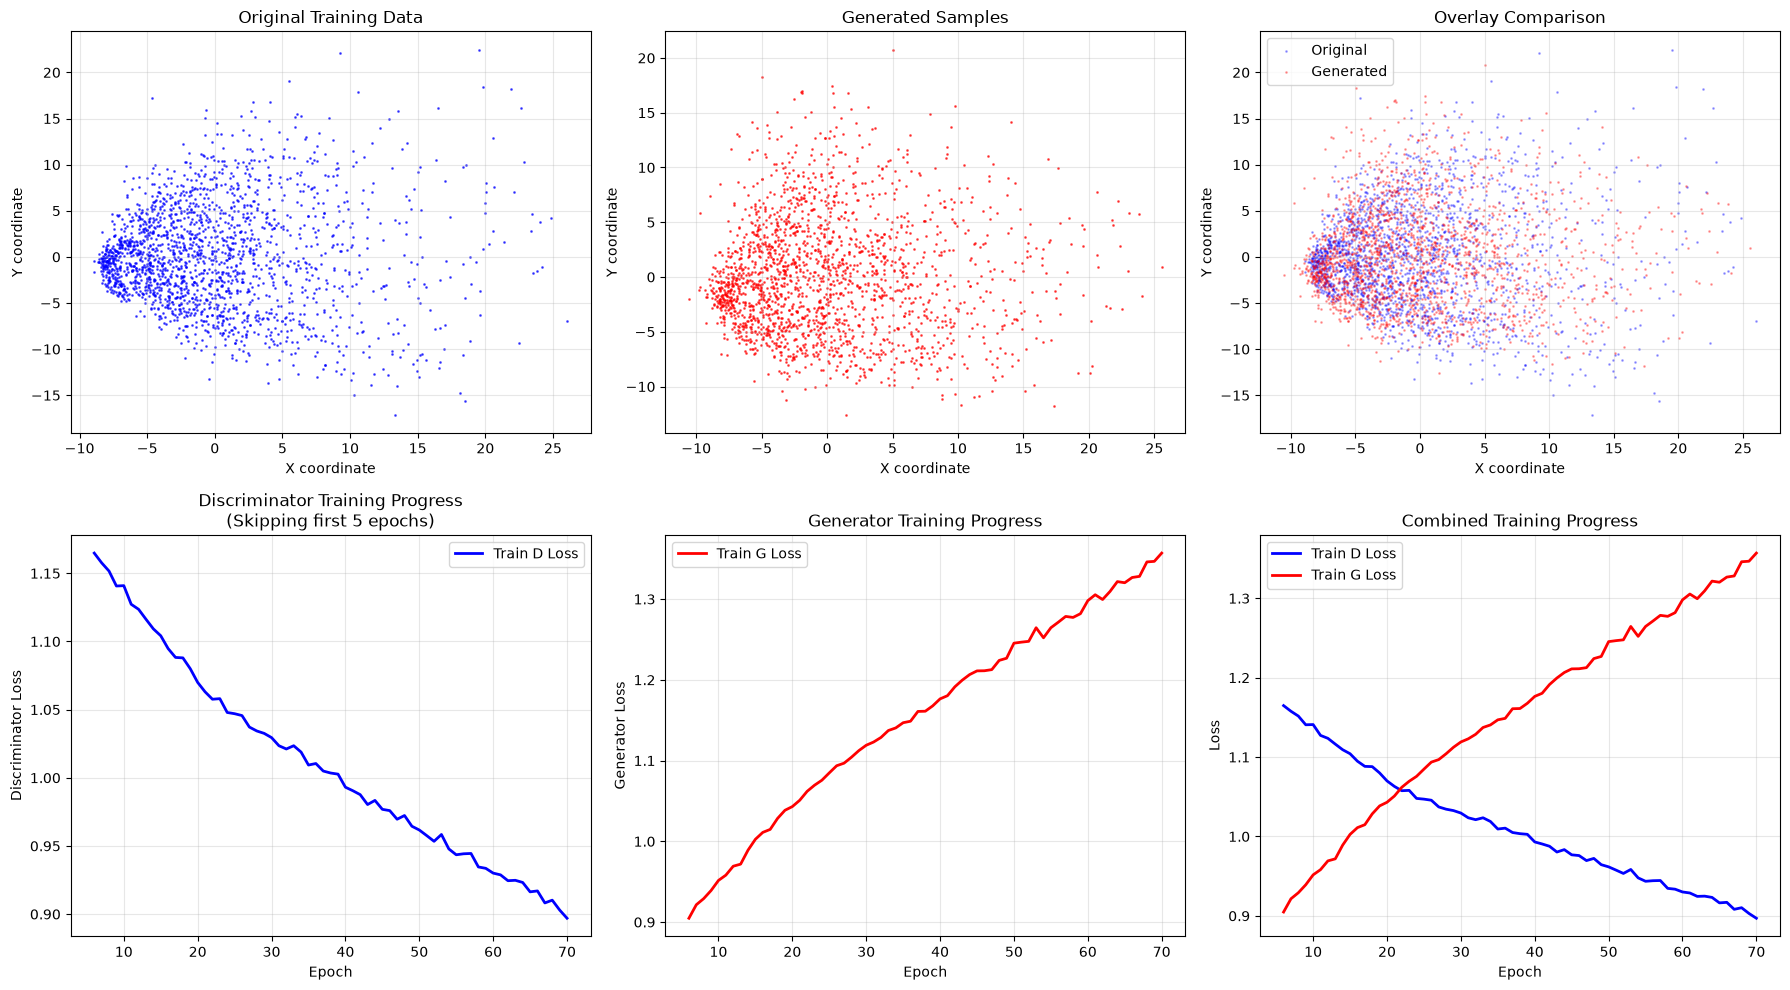

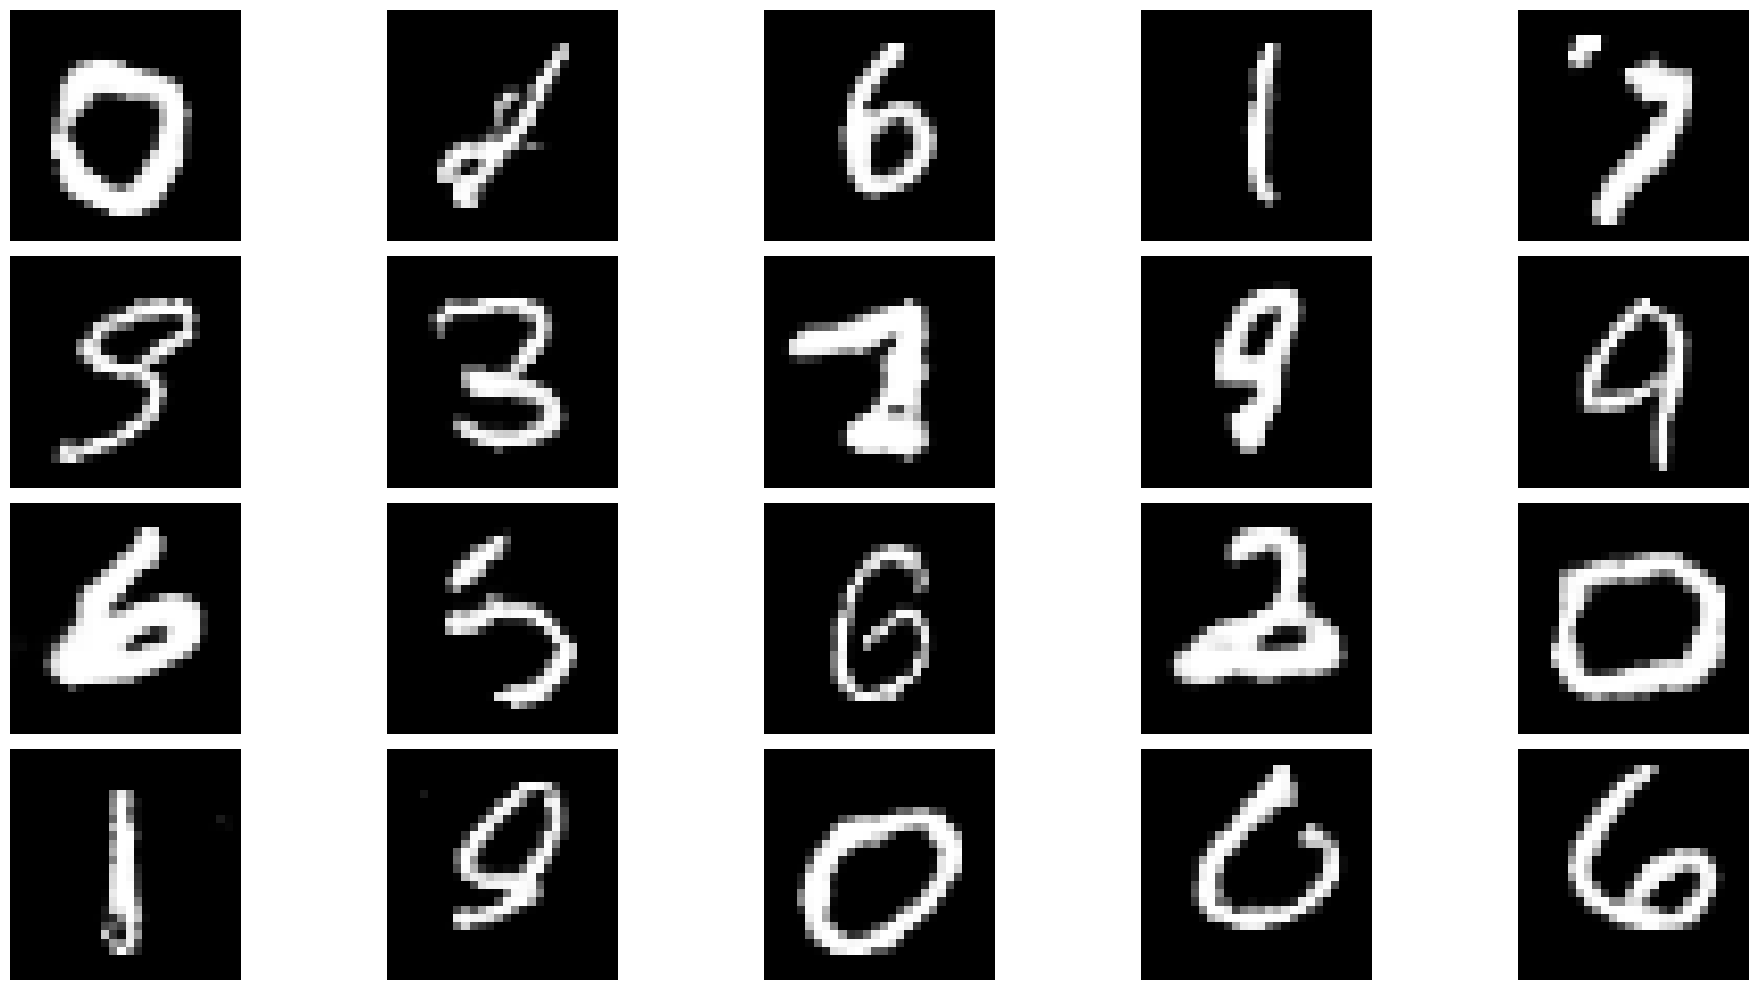

📈 Epoch 70 Summary:
   Train D Loss: 0.8970, Val D Loss: 1.1416
   Train G Loss: 1.3569, Val G Loss: 1.3545

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.793846	G_loss: 1.477936
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.972588	G_loss: 1.756790
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.972047	G_loss: 0.620308
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.776702	G_loss: 1.193650
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.813454	G_loss: 1.171936
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.816822	G_loss: 1.721366
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.996425	G_loss: 0.599734
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.809679	G_loss: 1.465285
Epoch: 71 [51200/60000 (85%)]	D_loss: 1.071158	G_loss: 2.519952
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.962077	G_loss: 0.986066
====> Epoch: 71 Train D_loss: 0.9021, Train G_loss: 1.3523
====> Epoch: 71 Val D_loss: 1.1310, Val G_loss: 0.9936
📈 Epoch 71 Summary:
   Train D Loss: 0.9021, Val D Loss: 1.1310
   Train G Loss: 1.3523

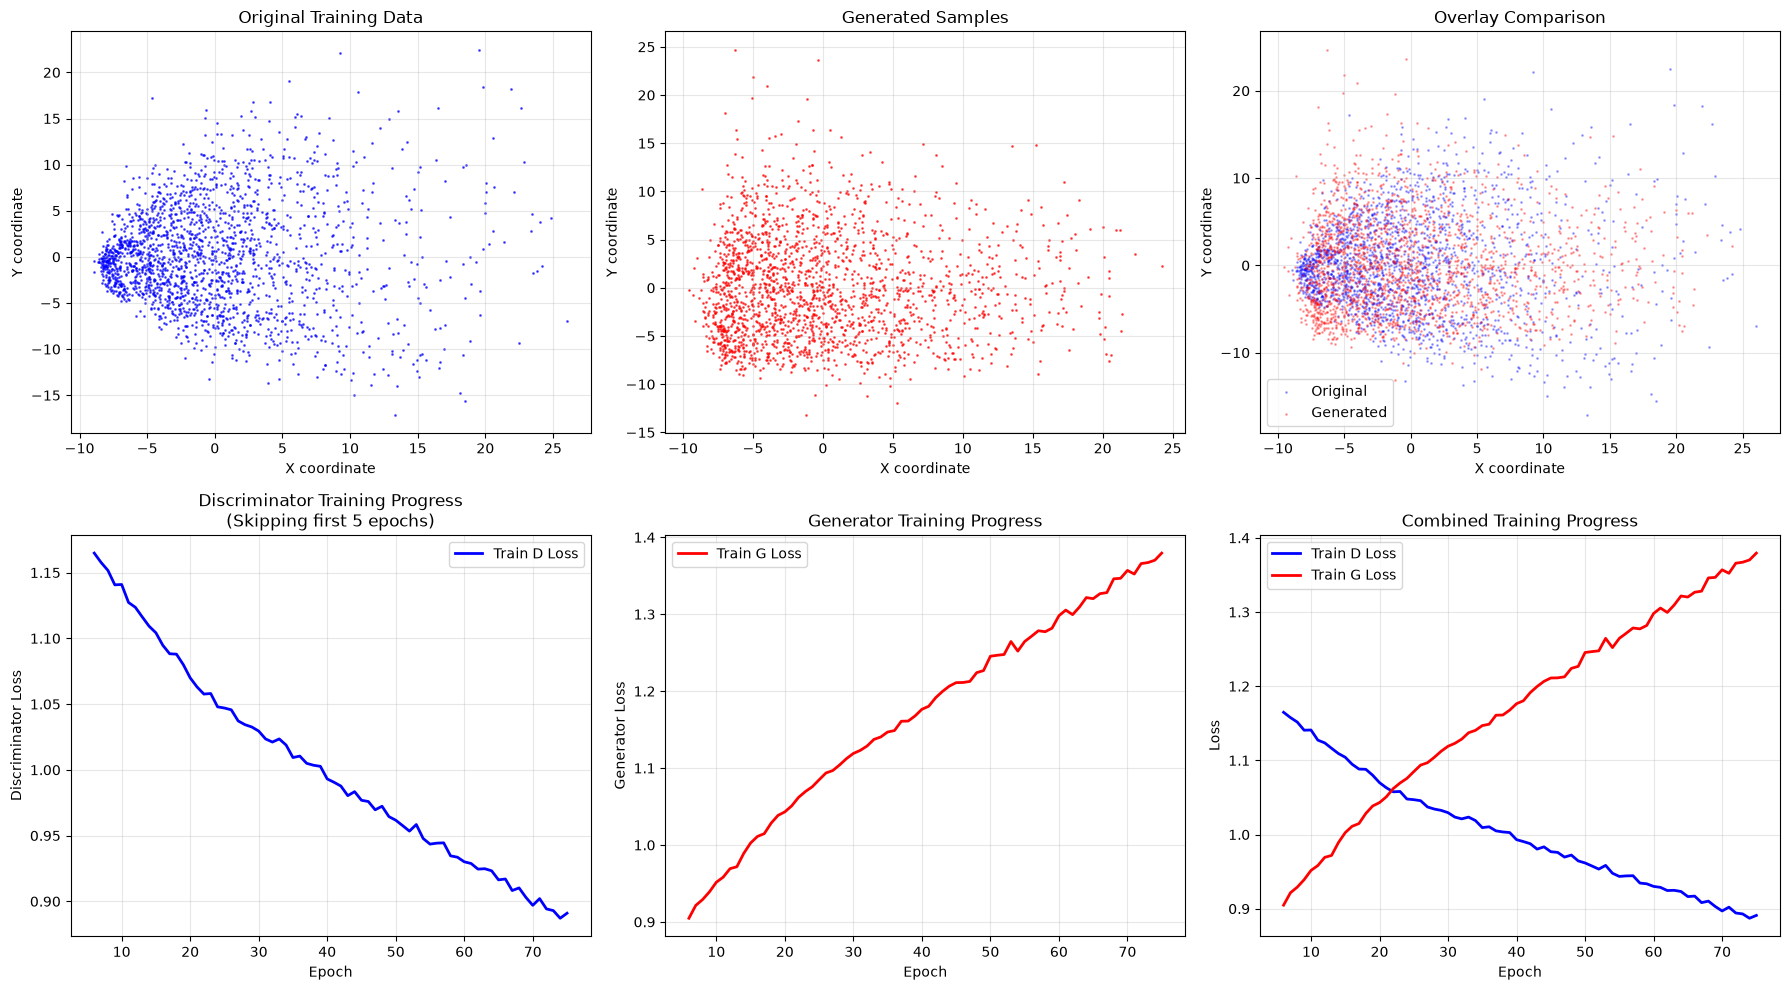

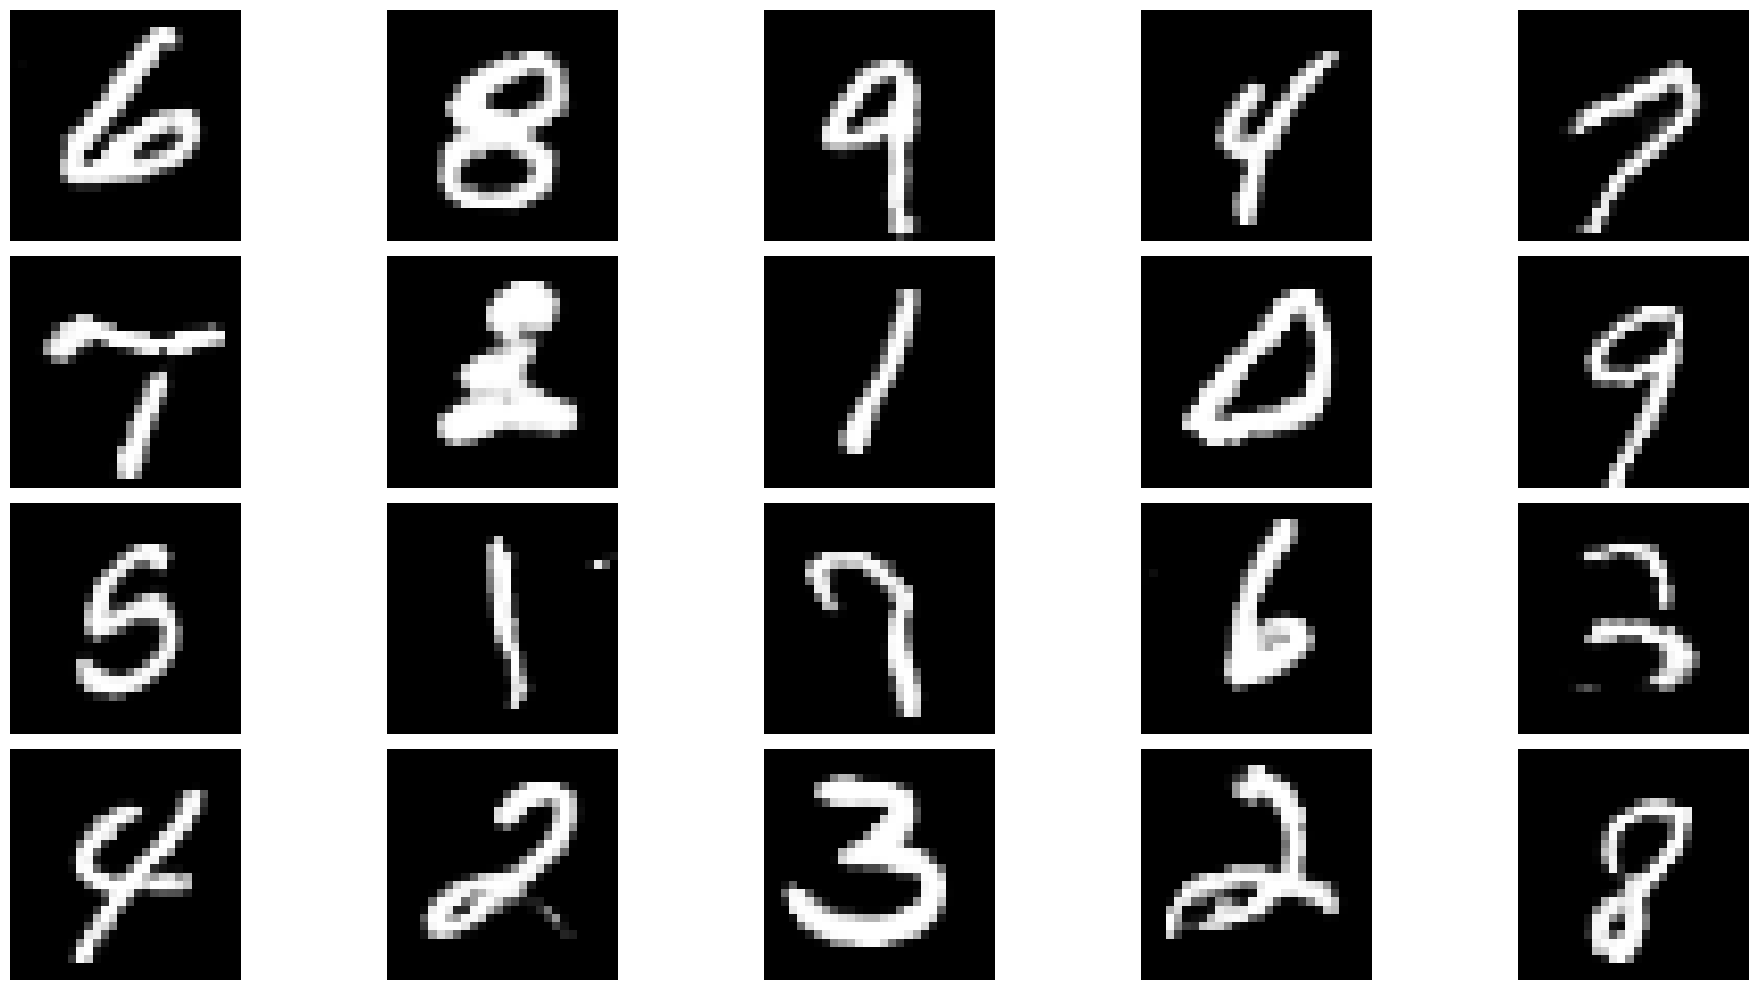

📈 Epoch 75 Summary:
   Train D Loss: 0.8910, Val D Loss: 1.3282
   Train G Loss: 1.3795, Val G Loss: 0.5741

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 1.106003	G_loss: 2.648954
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.823950	G_loss: 0.821581
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.931005	G_loss: 0.766020
Epoch: 76 [19200/60000 (32%)]	D_loss: 1.377834	G_loss: 2.121939
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.966257	G_loss: 1.985461
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.880508	G_loss: 1.756669
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.827329	G_loss: 1.743139
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.895506	G_loss: 1.251051
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.887208	G_loss: 1.251052
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.823374	G_loss: 1.266982
====> Epoch: 76 Train D_loss: 0.8887, Train G_loss: 1.3793
====> Epoch: 76 Val D_loss: 1.2769, Val G_loss: 1.6436
📈 Epoch 76 Summary:
   Train D Loss: 0.8887, Val D Loss: 1.2769
   Train G Loss: 1.3793

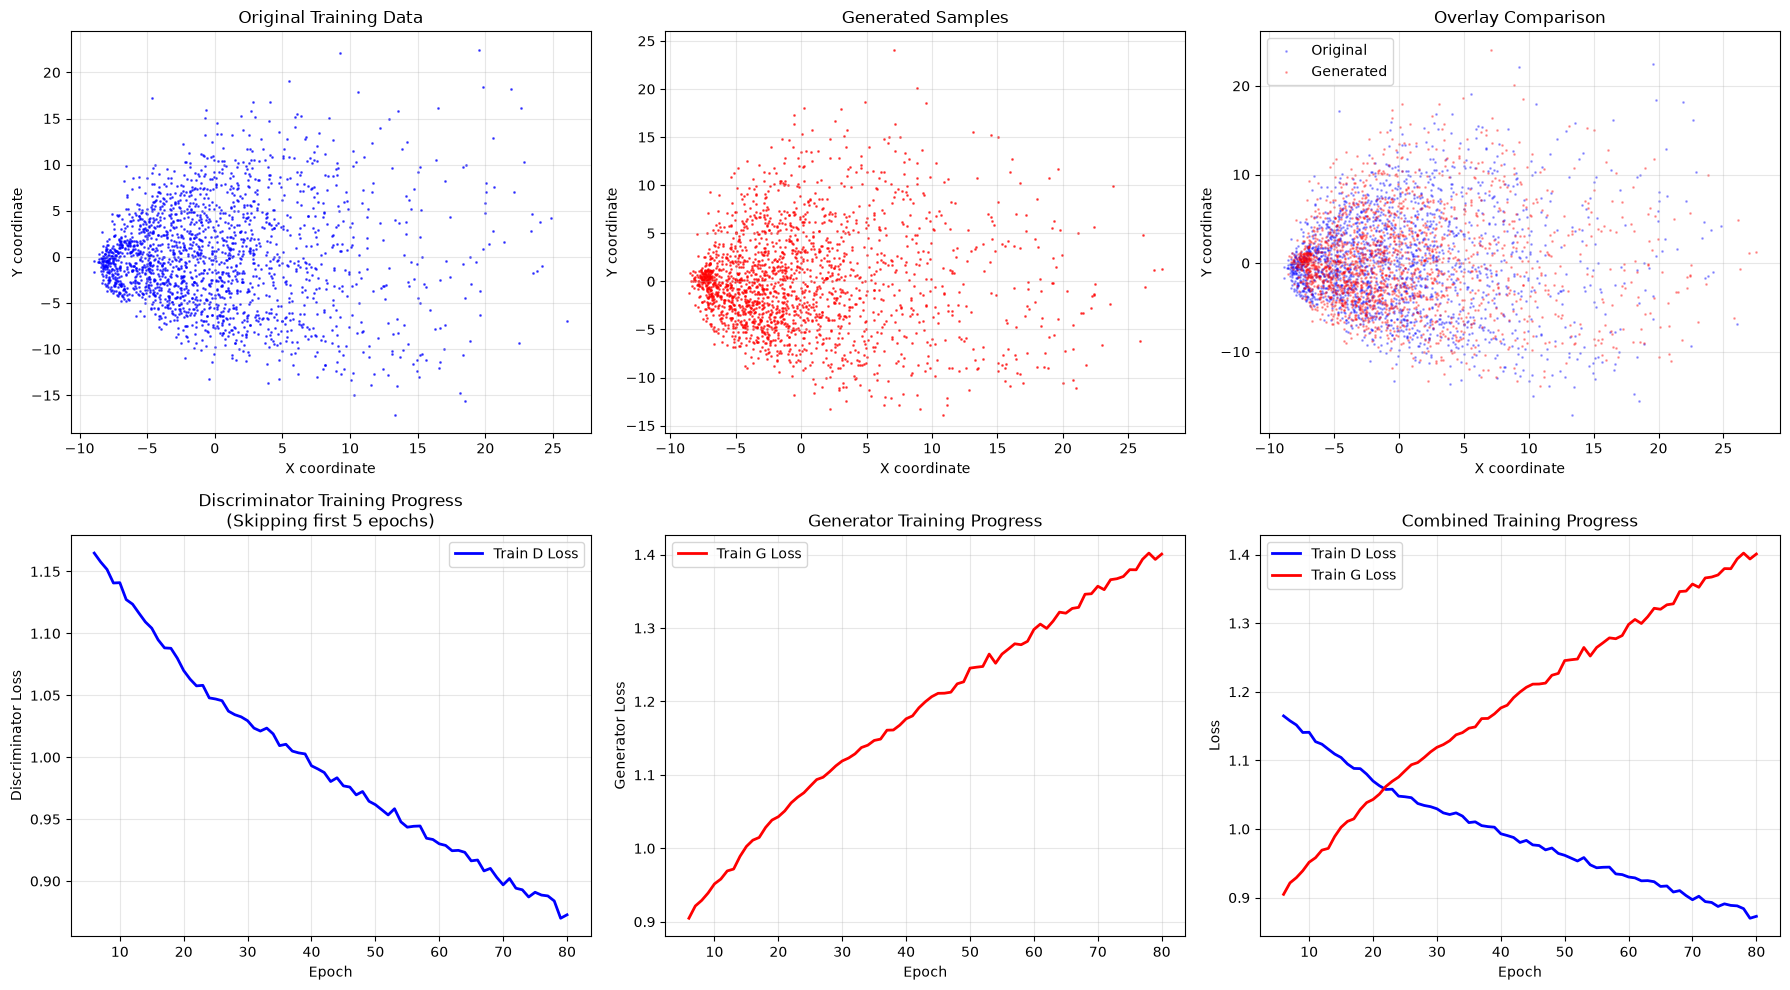

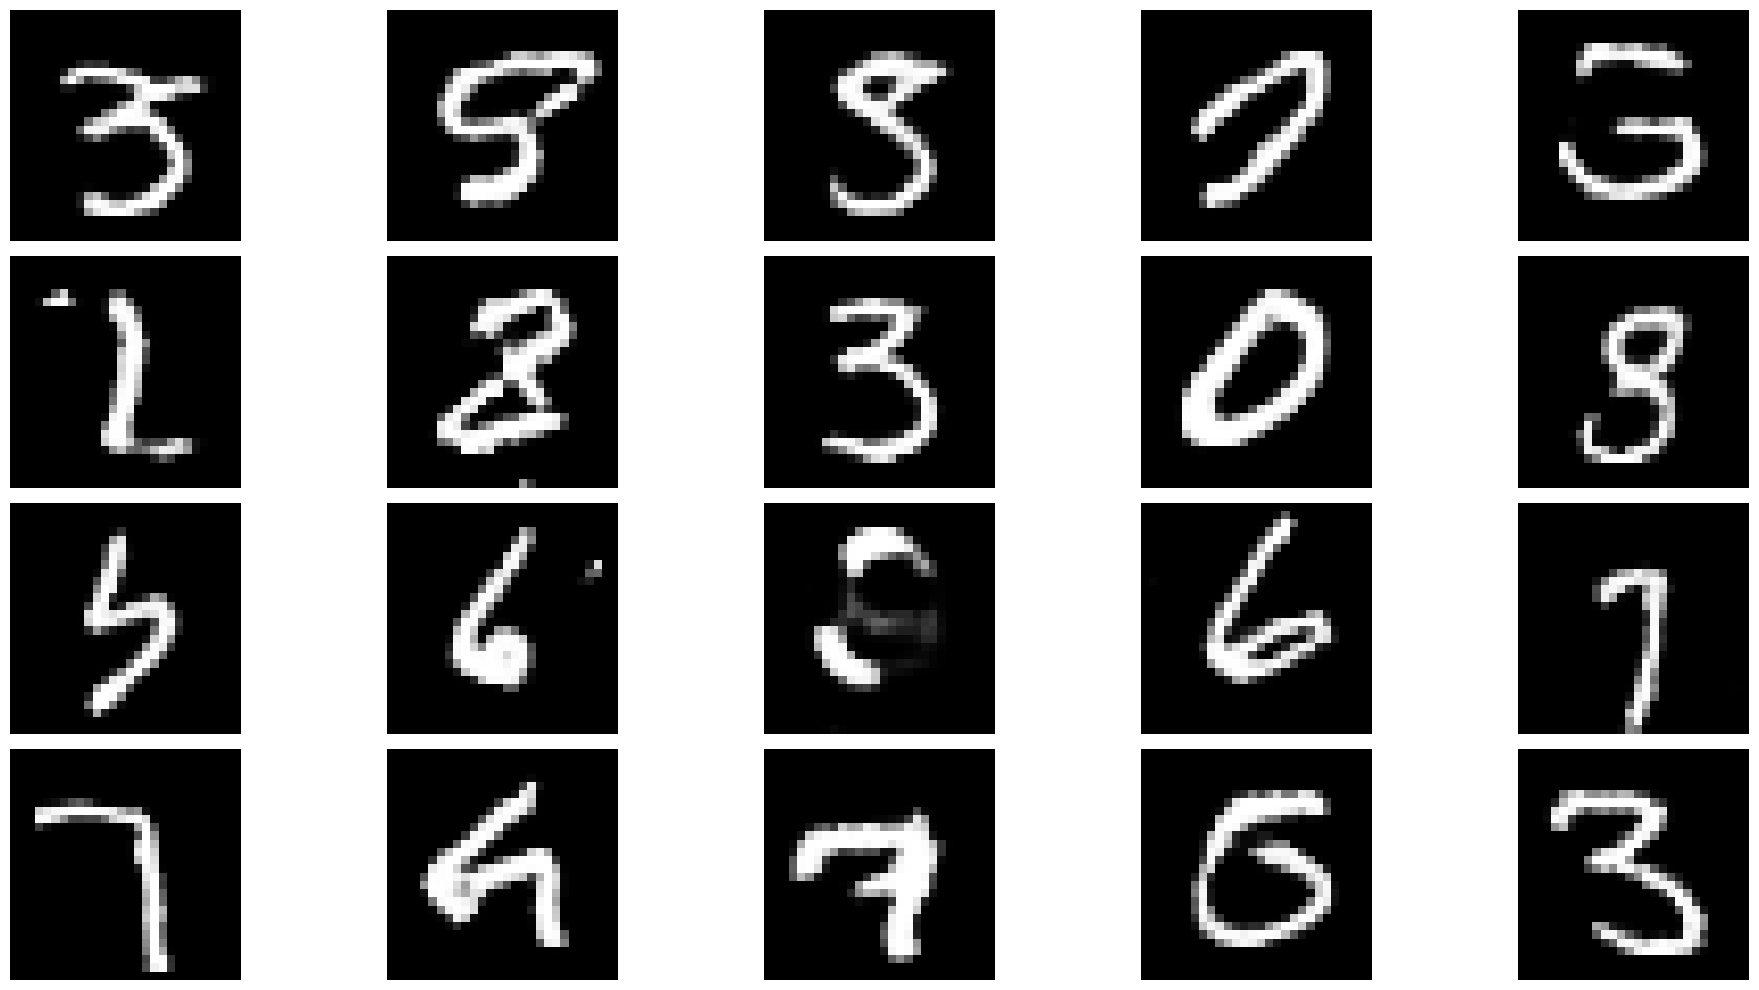

📈 Epoch 80 Summary:
   Train D Loss: 0.8728, Val D Loss: 1.1465
   Train G Loss: 1.4007, Val G Loss: 0.9467

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.856830	G_loss: 1.988993
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.766607	G_loss: 1.291775
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.869960	G_loss: 1.794824
Epoch: 81 [19200/60000 (32%)]	D_loss: 1.005619	G_loss: 0.785074
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.929564	G_loss: 1.379923
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.913275	G_loss: 1.755736
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.721086	G_loss: 1.161740
Epoch: 81 [44800/60000 (75%)]	D_loss: 1.194926	G_loss: 2.163962
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.942636	G_loss: 0.958608
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.857872	G_loss: 1.510281
====> Epoch: 81 Train D_loss: 0.8687, Train G_loss: 1.4101
====> Epoch: 81 Val D_loss: 1.1706, Val G_loss: 1.4062
📈 Epoch 81 Summary:
   Train D Loss: 0.8687, Val D Loss: 1.1706
   Train G Loss: 1.4101

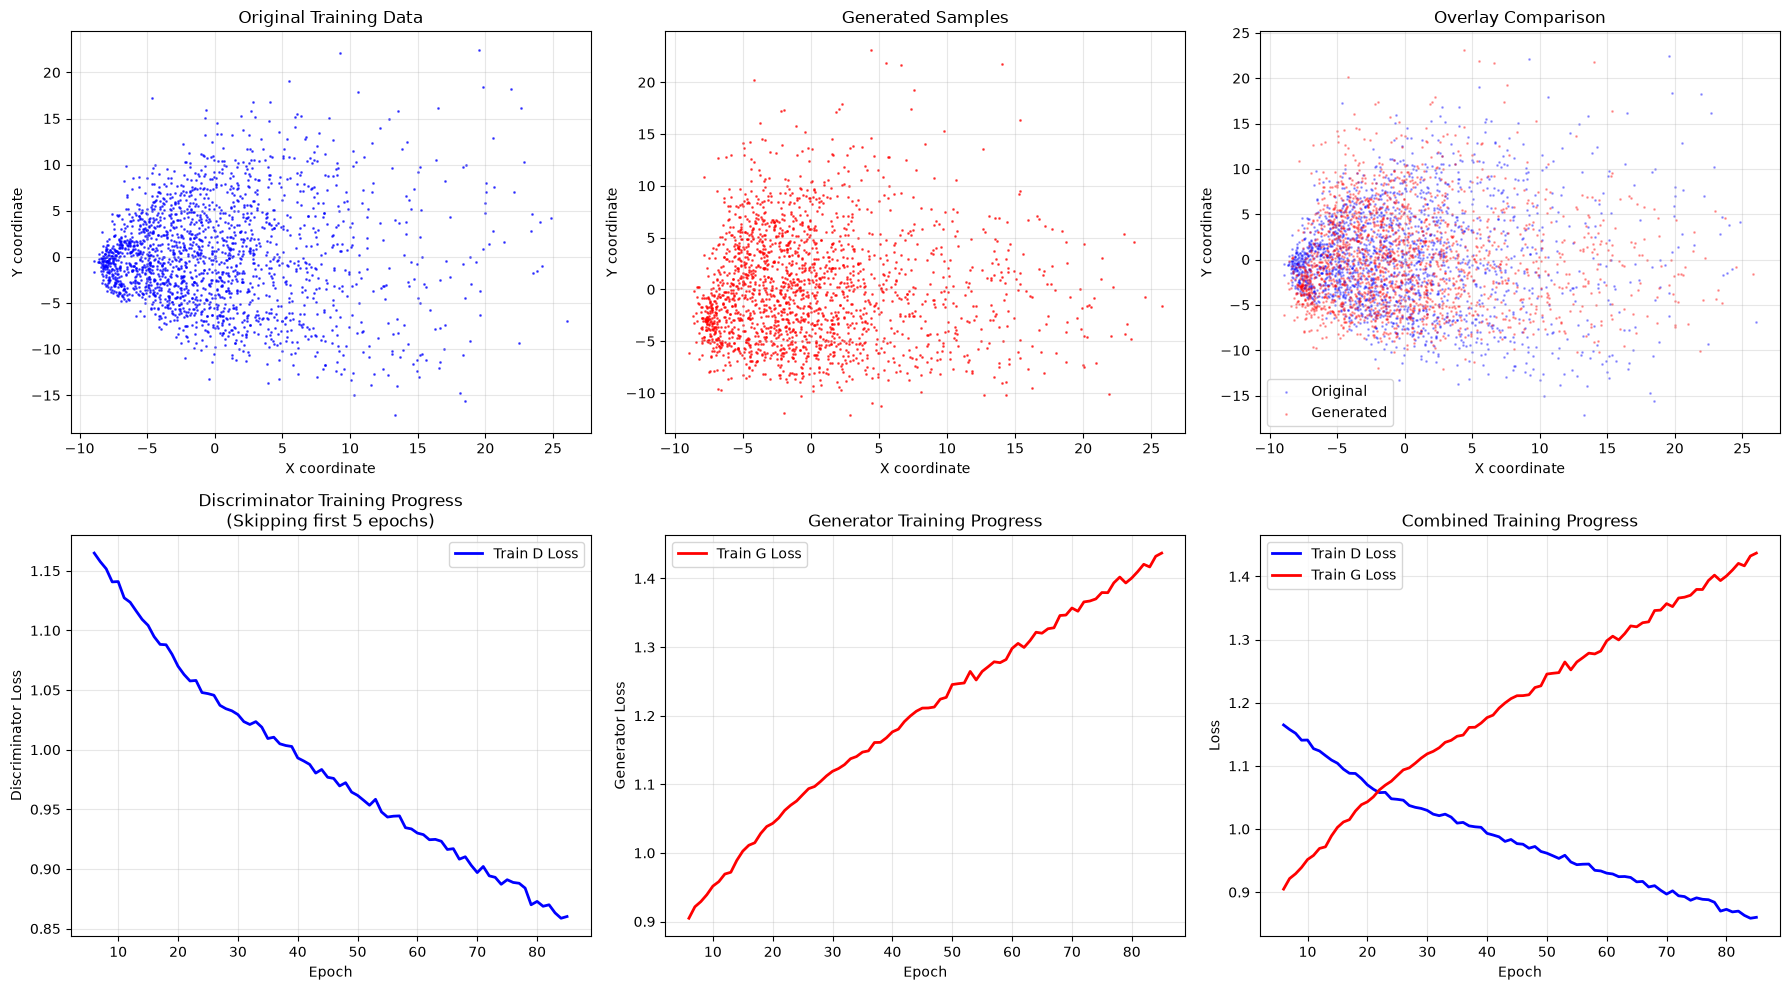

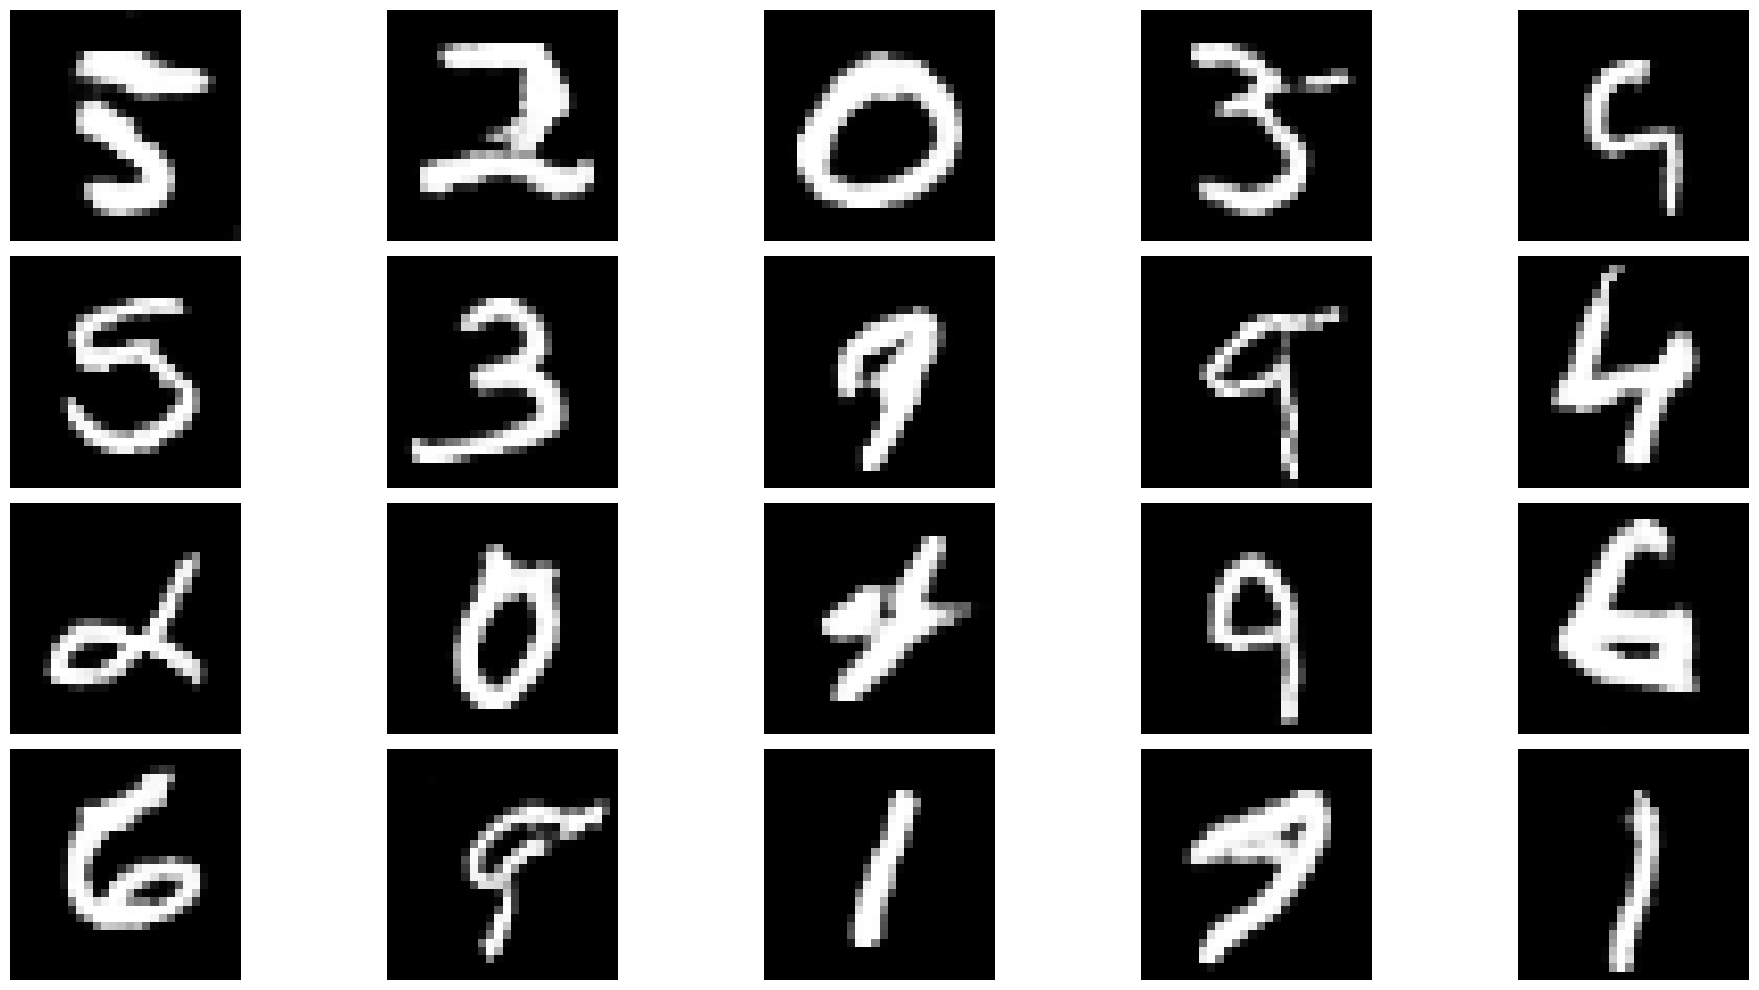

📈 Epoch 85 Summary:
   Train D Loss: 0.8601, Val D Loss: 1.1279
   Train G Loss: 1.4370, Val G Loss: 1.2565

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.831429	G_loss: 1.581665
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.801835	G_loss: 1.199599
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.802222	G_loss: 1.987303
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.891698	G_loss: 1.060894
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.928219	G_loss: 1.365061
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.777405	G_loss: 1.192606
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.949944	G_loss: 0.910670
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.910017	G_loss: 1.851024
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.793324	G_loss: 1.611857
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.820391	G_loss: 1.735100
====> Epoch: 86 Train D_loss: 0.8581, Train G_loss: 1.4457
====> Epoch: 86 Val D_loss: 1.1183, Val G_loss: 1.1699
📈 Epoch 86 Summary:
   Train D Loss: 0.8581, Val D Loss: 1.1183
   Train G Loss: 1.4457

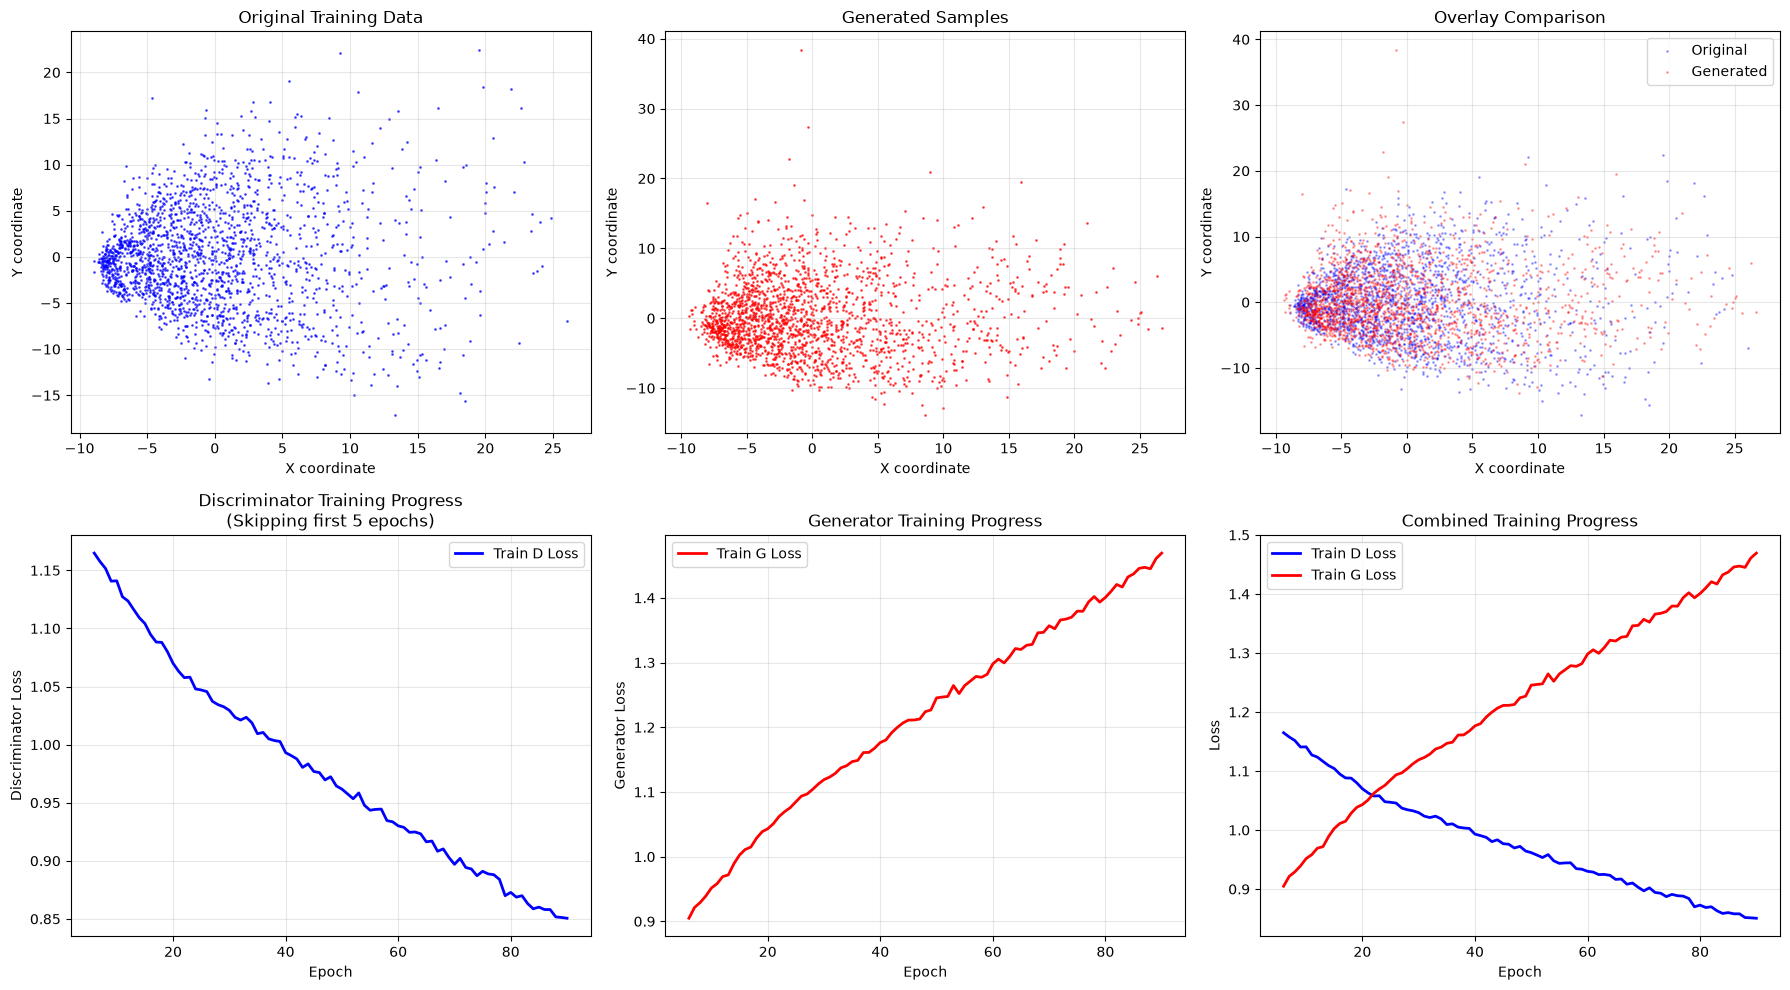

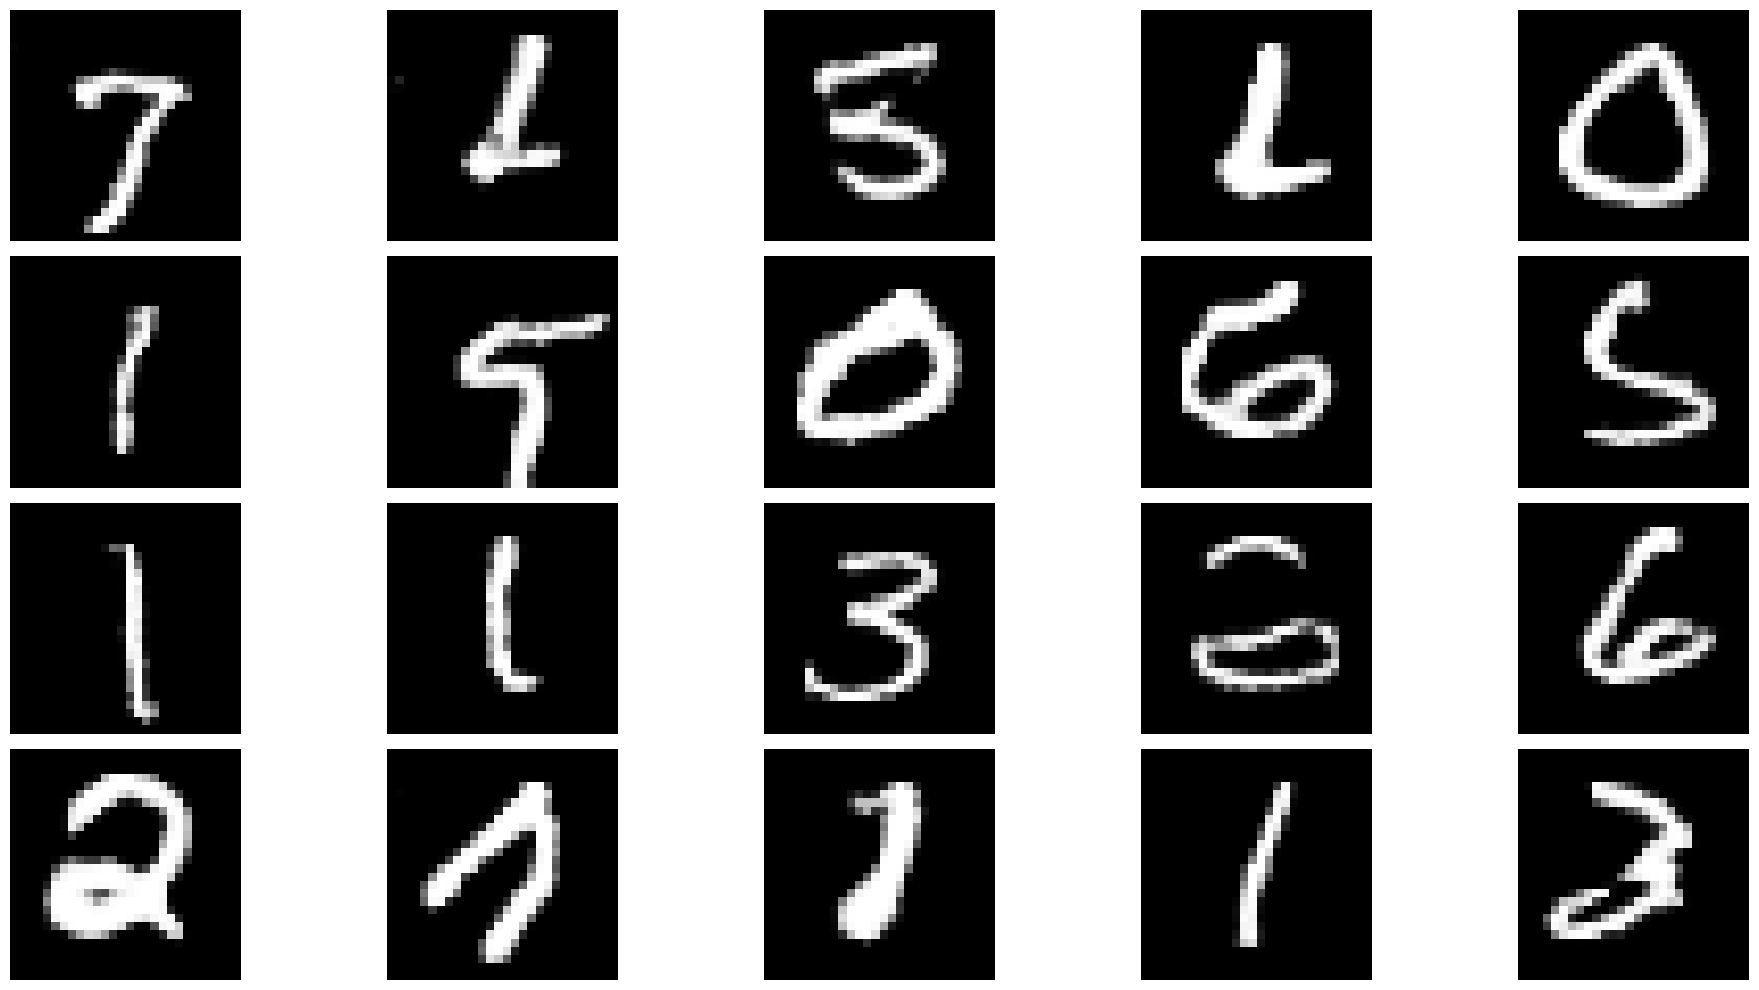

📈 Epoch 90 Summary:
   Train D Loss: 0.8506, Val D Loss: 1.1763
   Train G Loss: 1.4692, Val G Loss: 1.4855

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.692720	G_loss: 1.398574
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.997965	G_loss: 2.466368
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.773367	G_loss: 1.511809
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.902099	G_loss: 1.674529
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.812638	G_loss: 1.142559
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.776017	G_loss: 1.443410
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.868869	G_loss: 1.178248
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.820292	G_loss: 1.491079
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.813831	G_loss: 1.138801
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.735916	G_loss: 2.047400
====> Epoch: 91 Train D_loss: 0.8470, Train G_loss: 1.4660
====> Epoch: 91 Val D_loss: 1.1400, Val G_loss: 0.8778
📈 Epoch 91 Summary:
   Train D Loss: 0.8470, Val D Loss: 1.1400
   Train G Loss: 1.4660

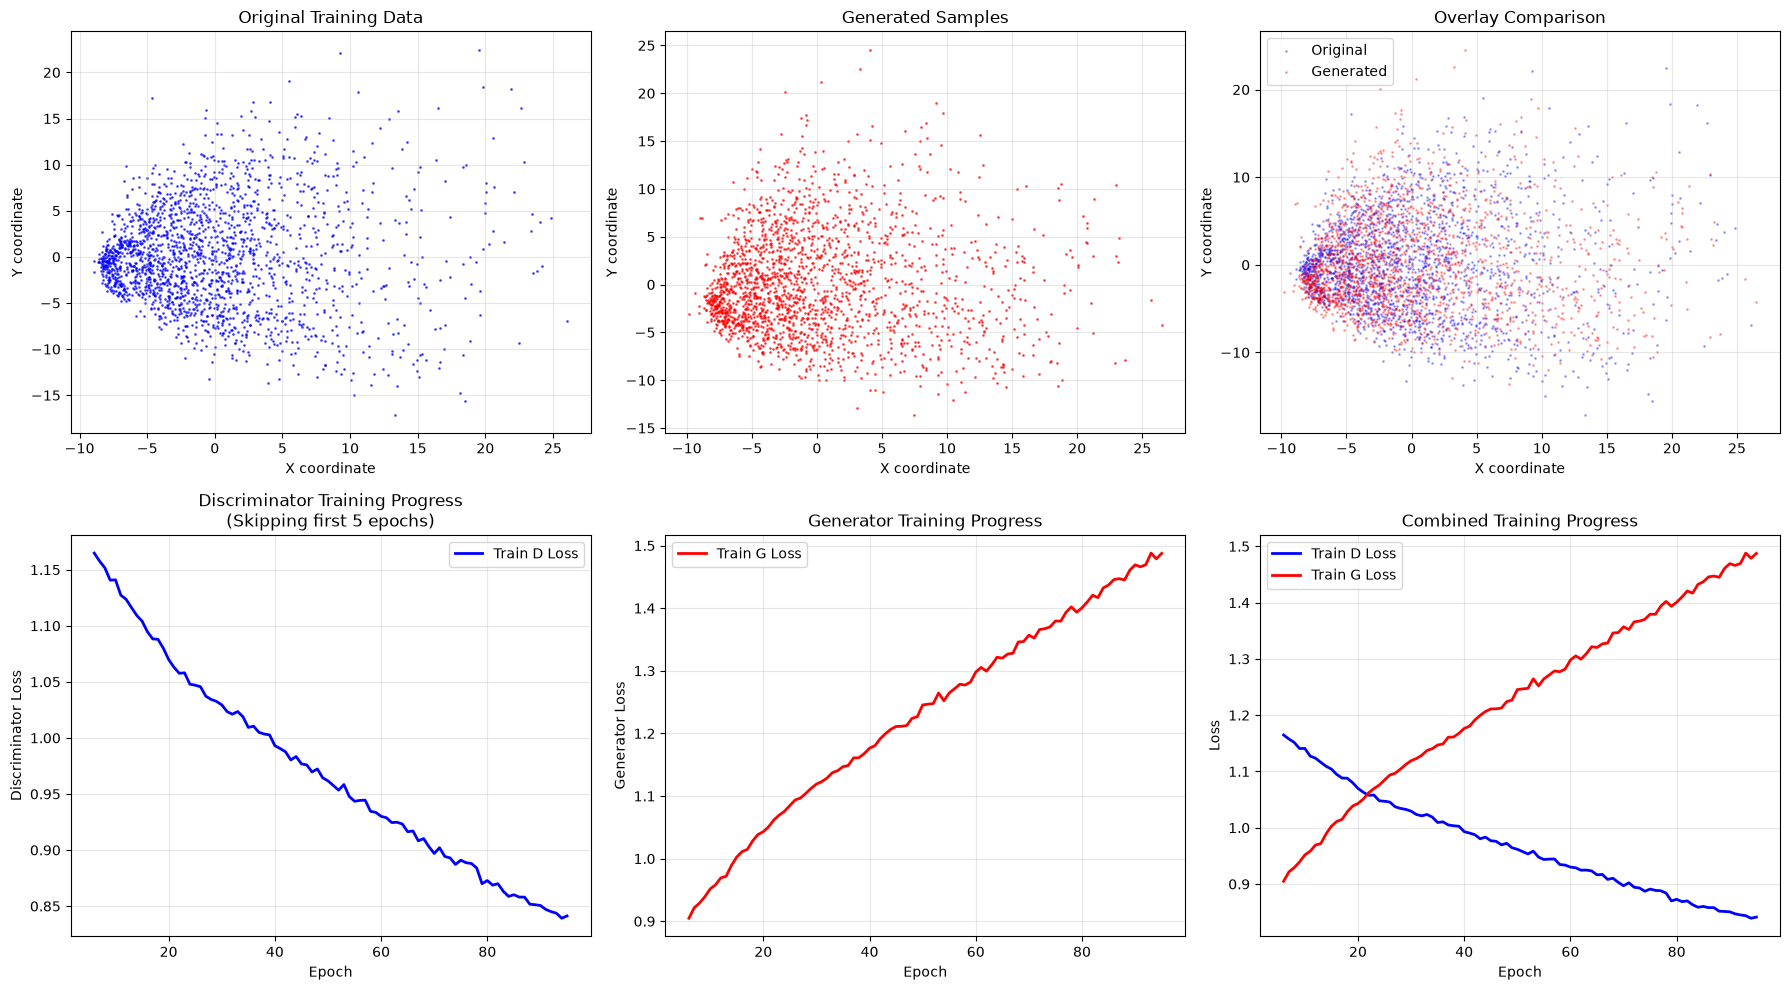

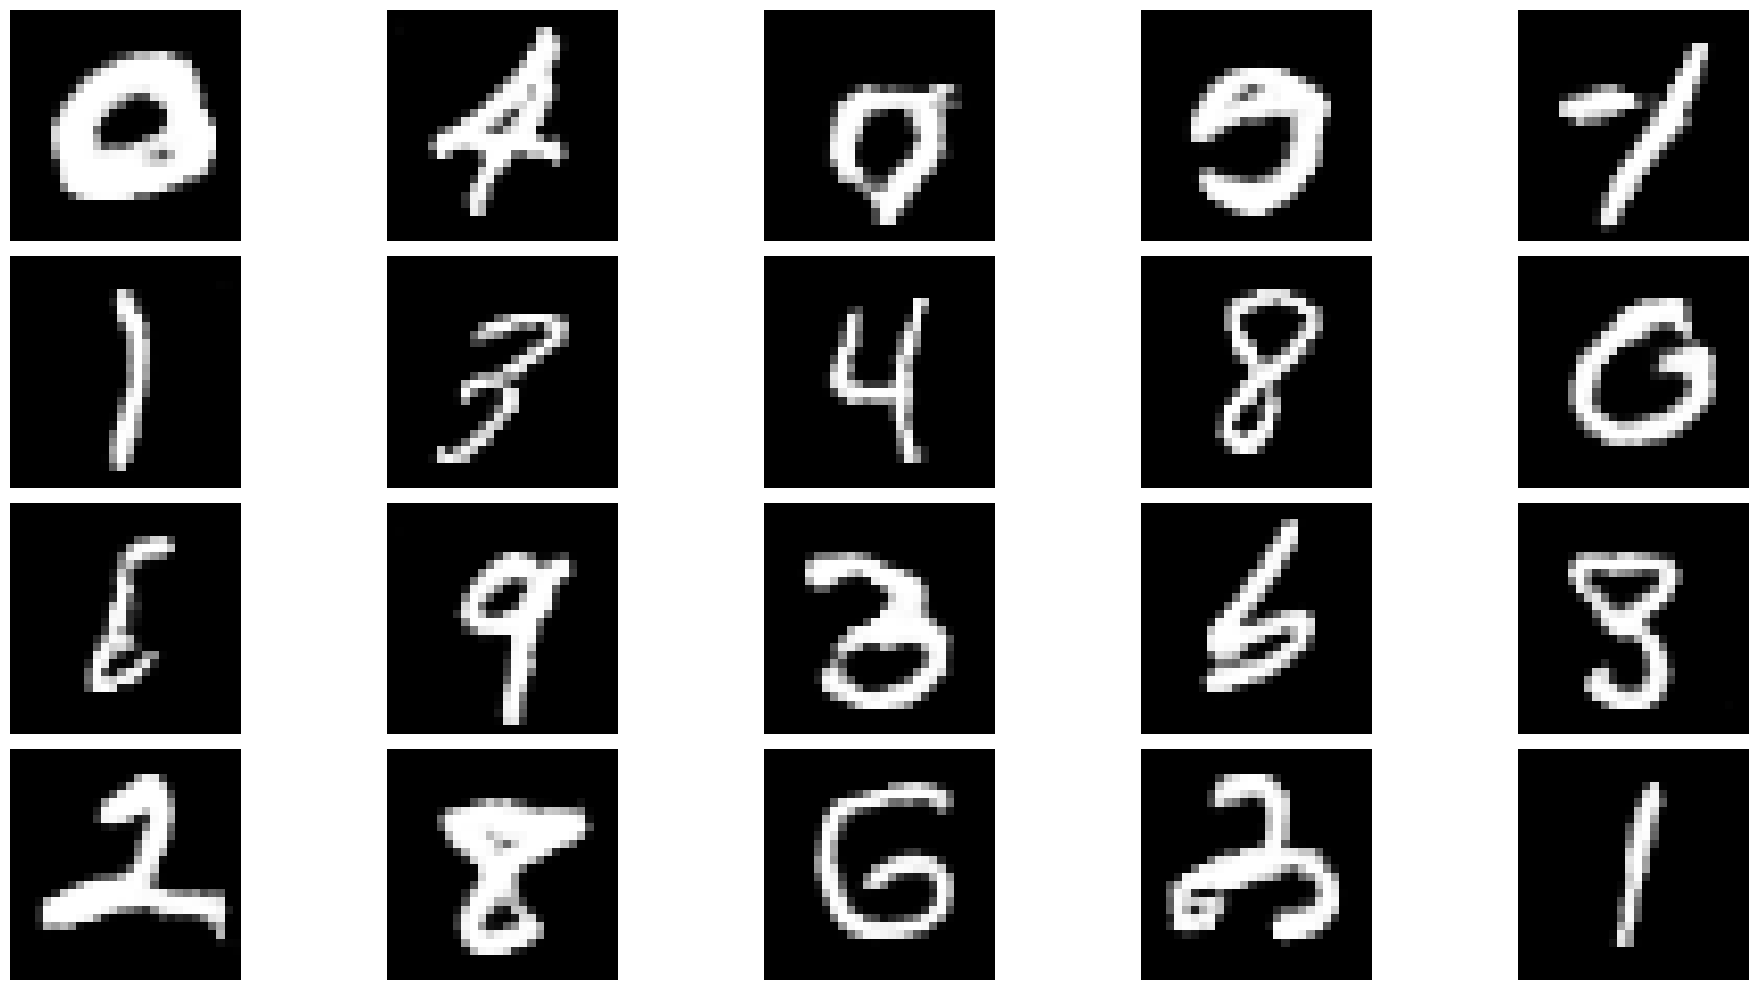

📈 Epoch 95 Summary:
   Train D Loss: 0.8412, Val D Loss: 1.1170
   Train G Loss: 1.4875, Val G Loss: 1.2678

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.907396	G_loss: 1.325055
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.882458	G_loss: 1.948519
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.775469	G_loss: 1.720367
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.859189	G_loss: 1.245353
Epoch: 96 [25600/60000 (43%)]	D_loss: 1.009820	G_loss: 2.283304
Epoch: 96 [32000/60000 (53%)]	D_loss: 1.098332	G_loss: 0.694974
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.710154	G_loss: 1.131836
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.720977	G_loss: 1.719342
Epoch: 96 [51200/60000 (85%)]	D_loss: 1.286484	G_loss: 0.850383
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.848165	G_loss: 1.714960
====> Epoch: 96 Train D_loss: 0.8295, Train G_loss: 1.4994
====> Epoch: 96 Val D_loss: 1.1347, Val G_loss: 1.4108
📈 Epoch 96 Summary:
   Train D Loss: 0.8295, Val D Loss: 1.1347
   Train G Loss: 1.4994

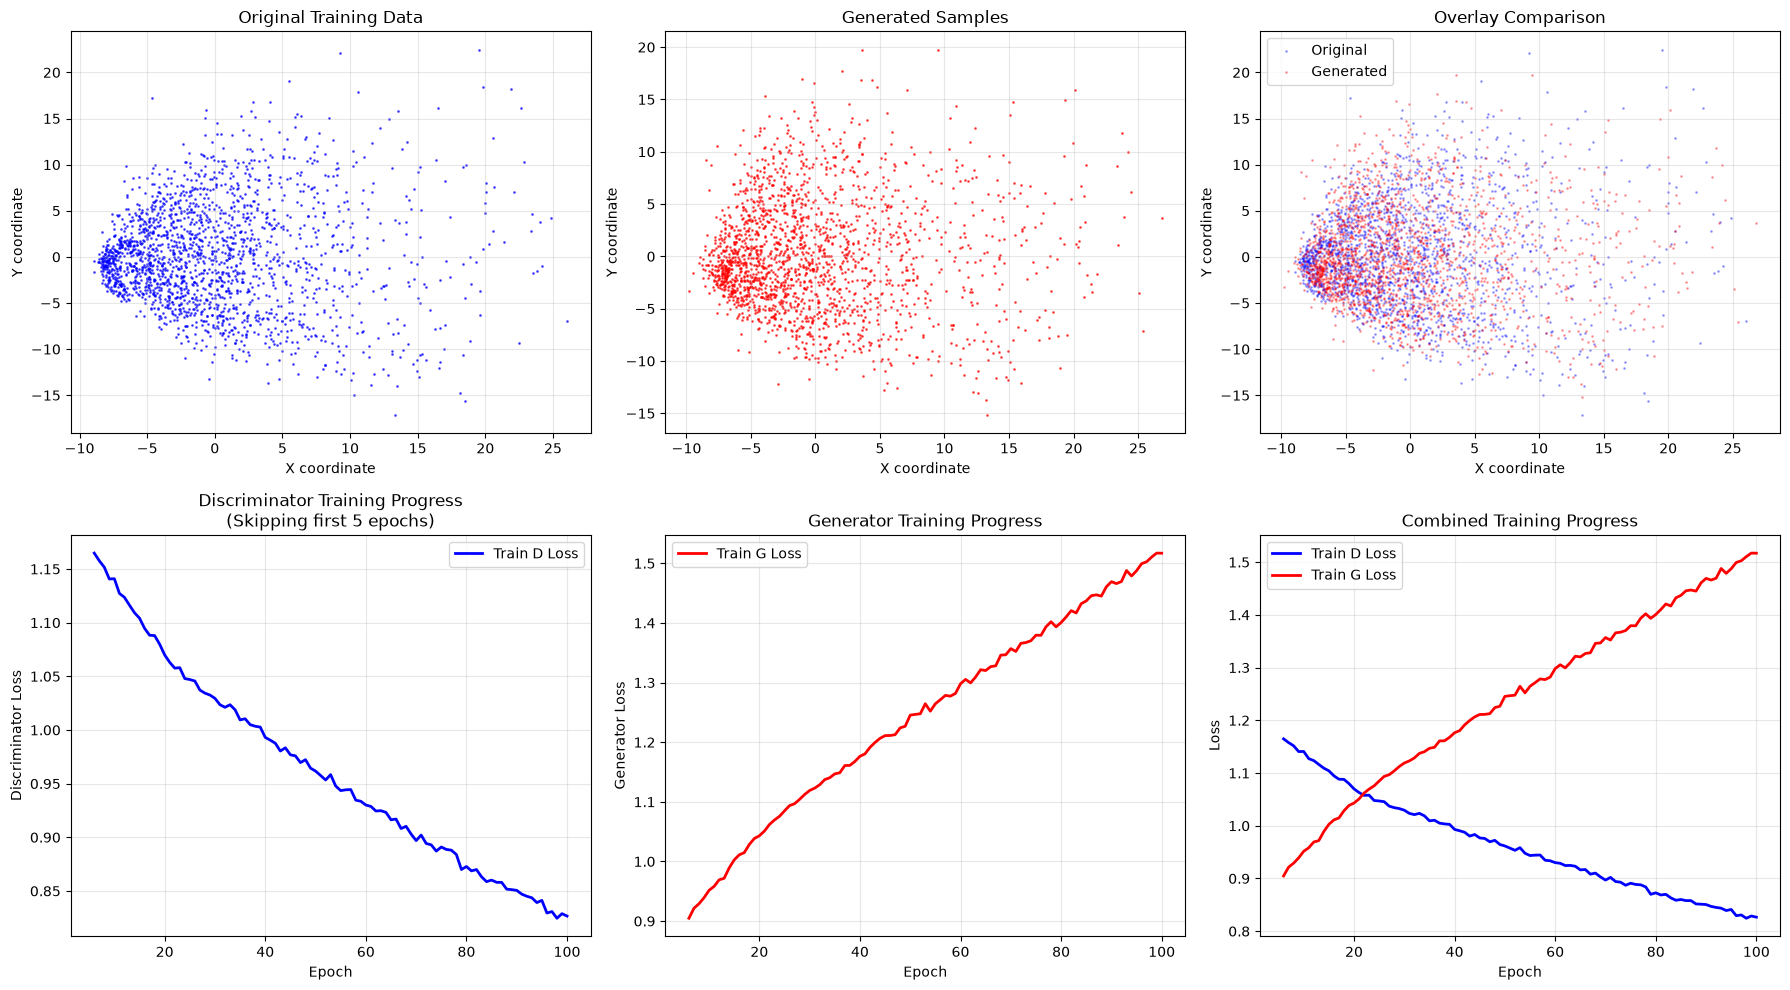

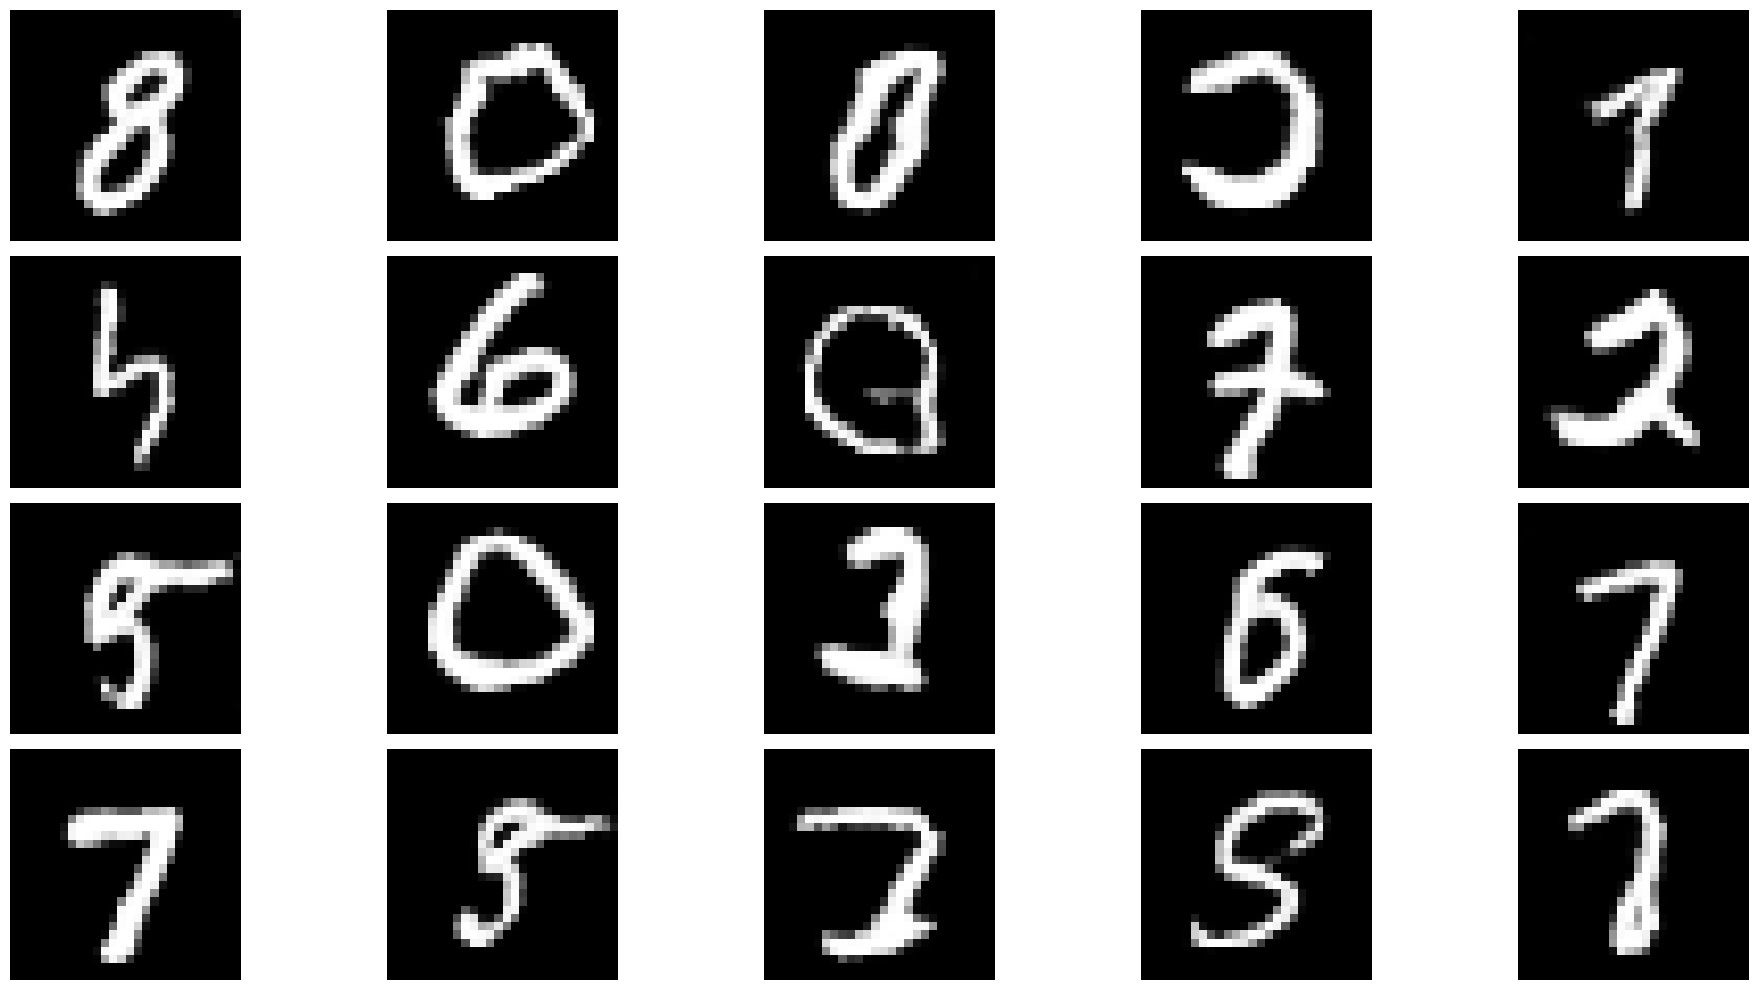

📈 Epoch 100 Summary:
   Train D Loss: 0.8267, Val D Loss: 1.1057
   Train G Loss: 1.5170, Val G Loss: 1.2543

🎉 Training completed!

🎨 Final comprehensive visualization:


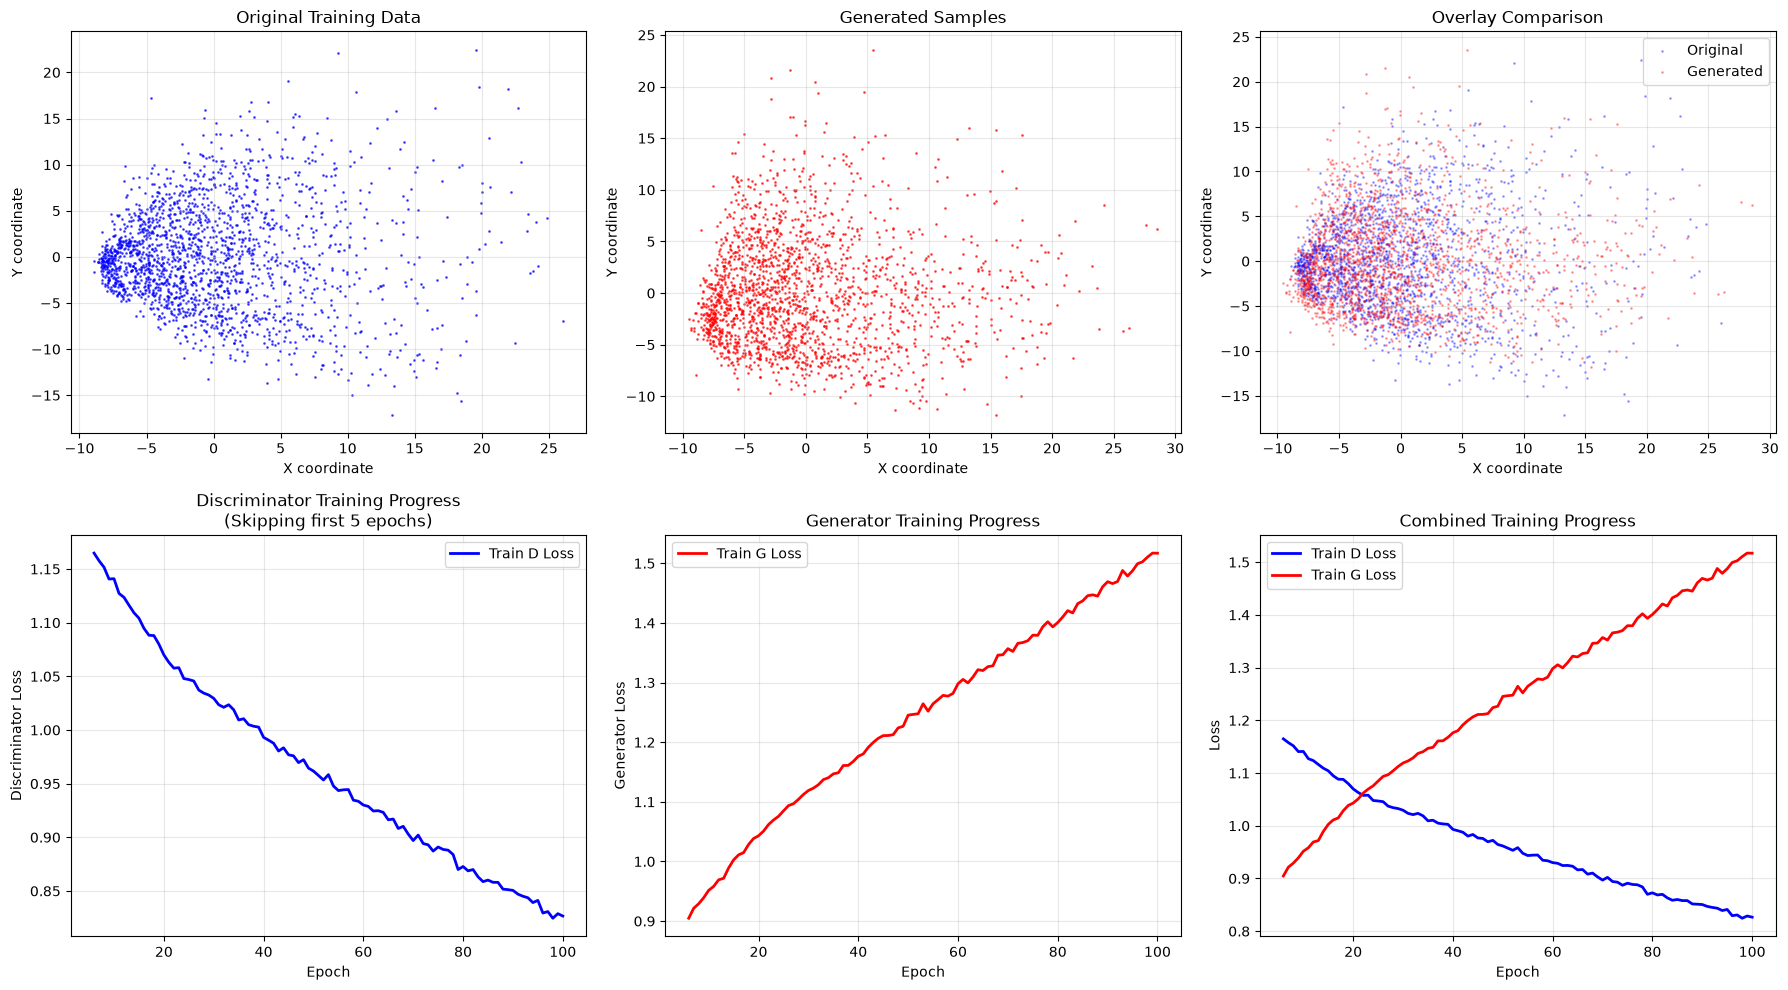

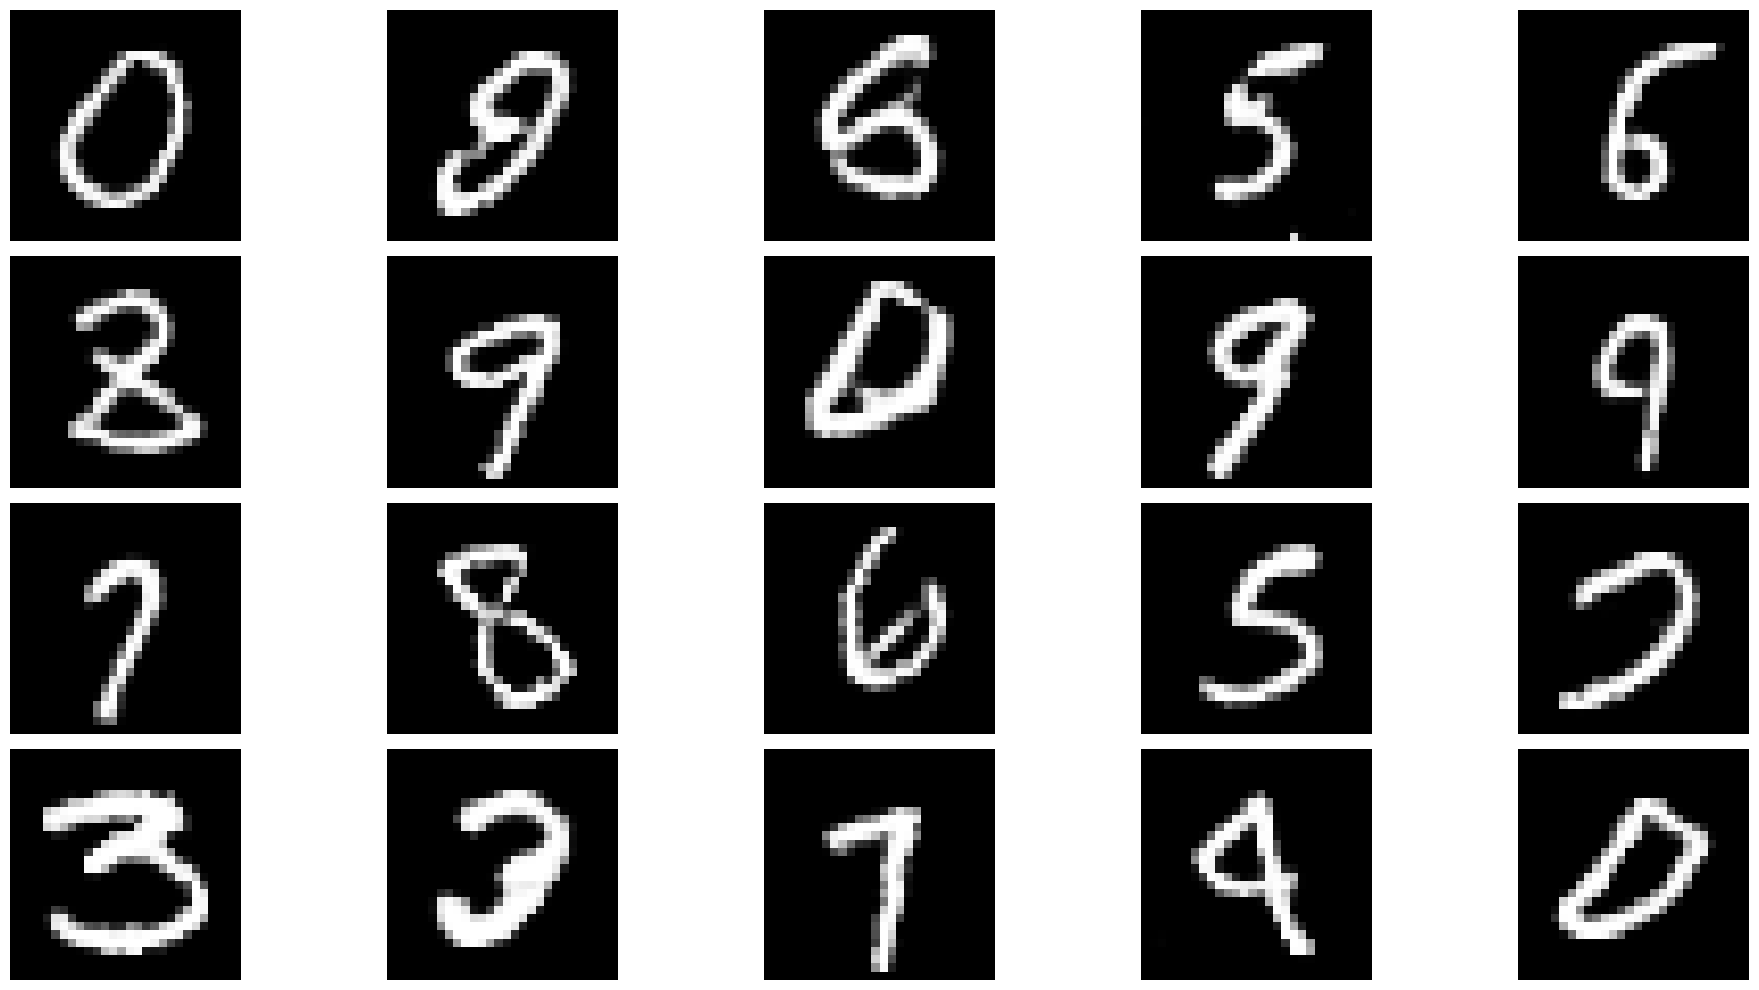

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


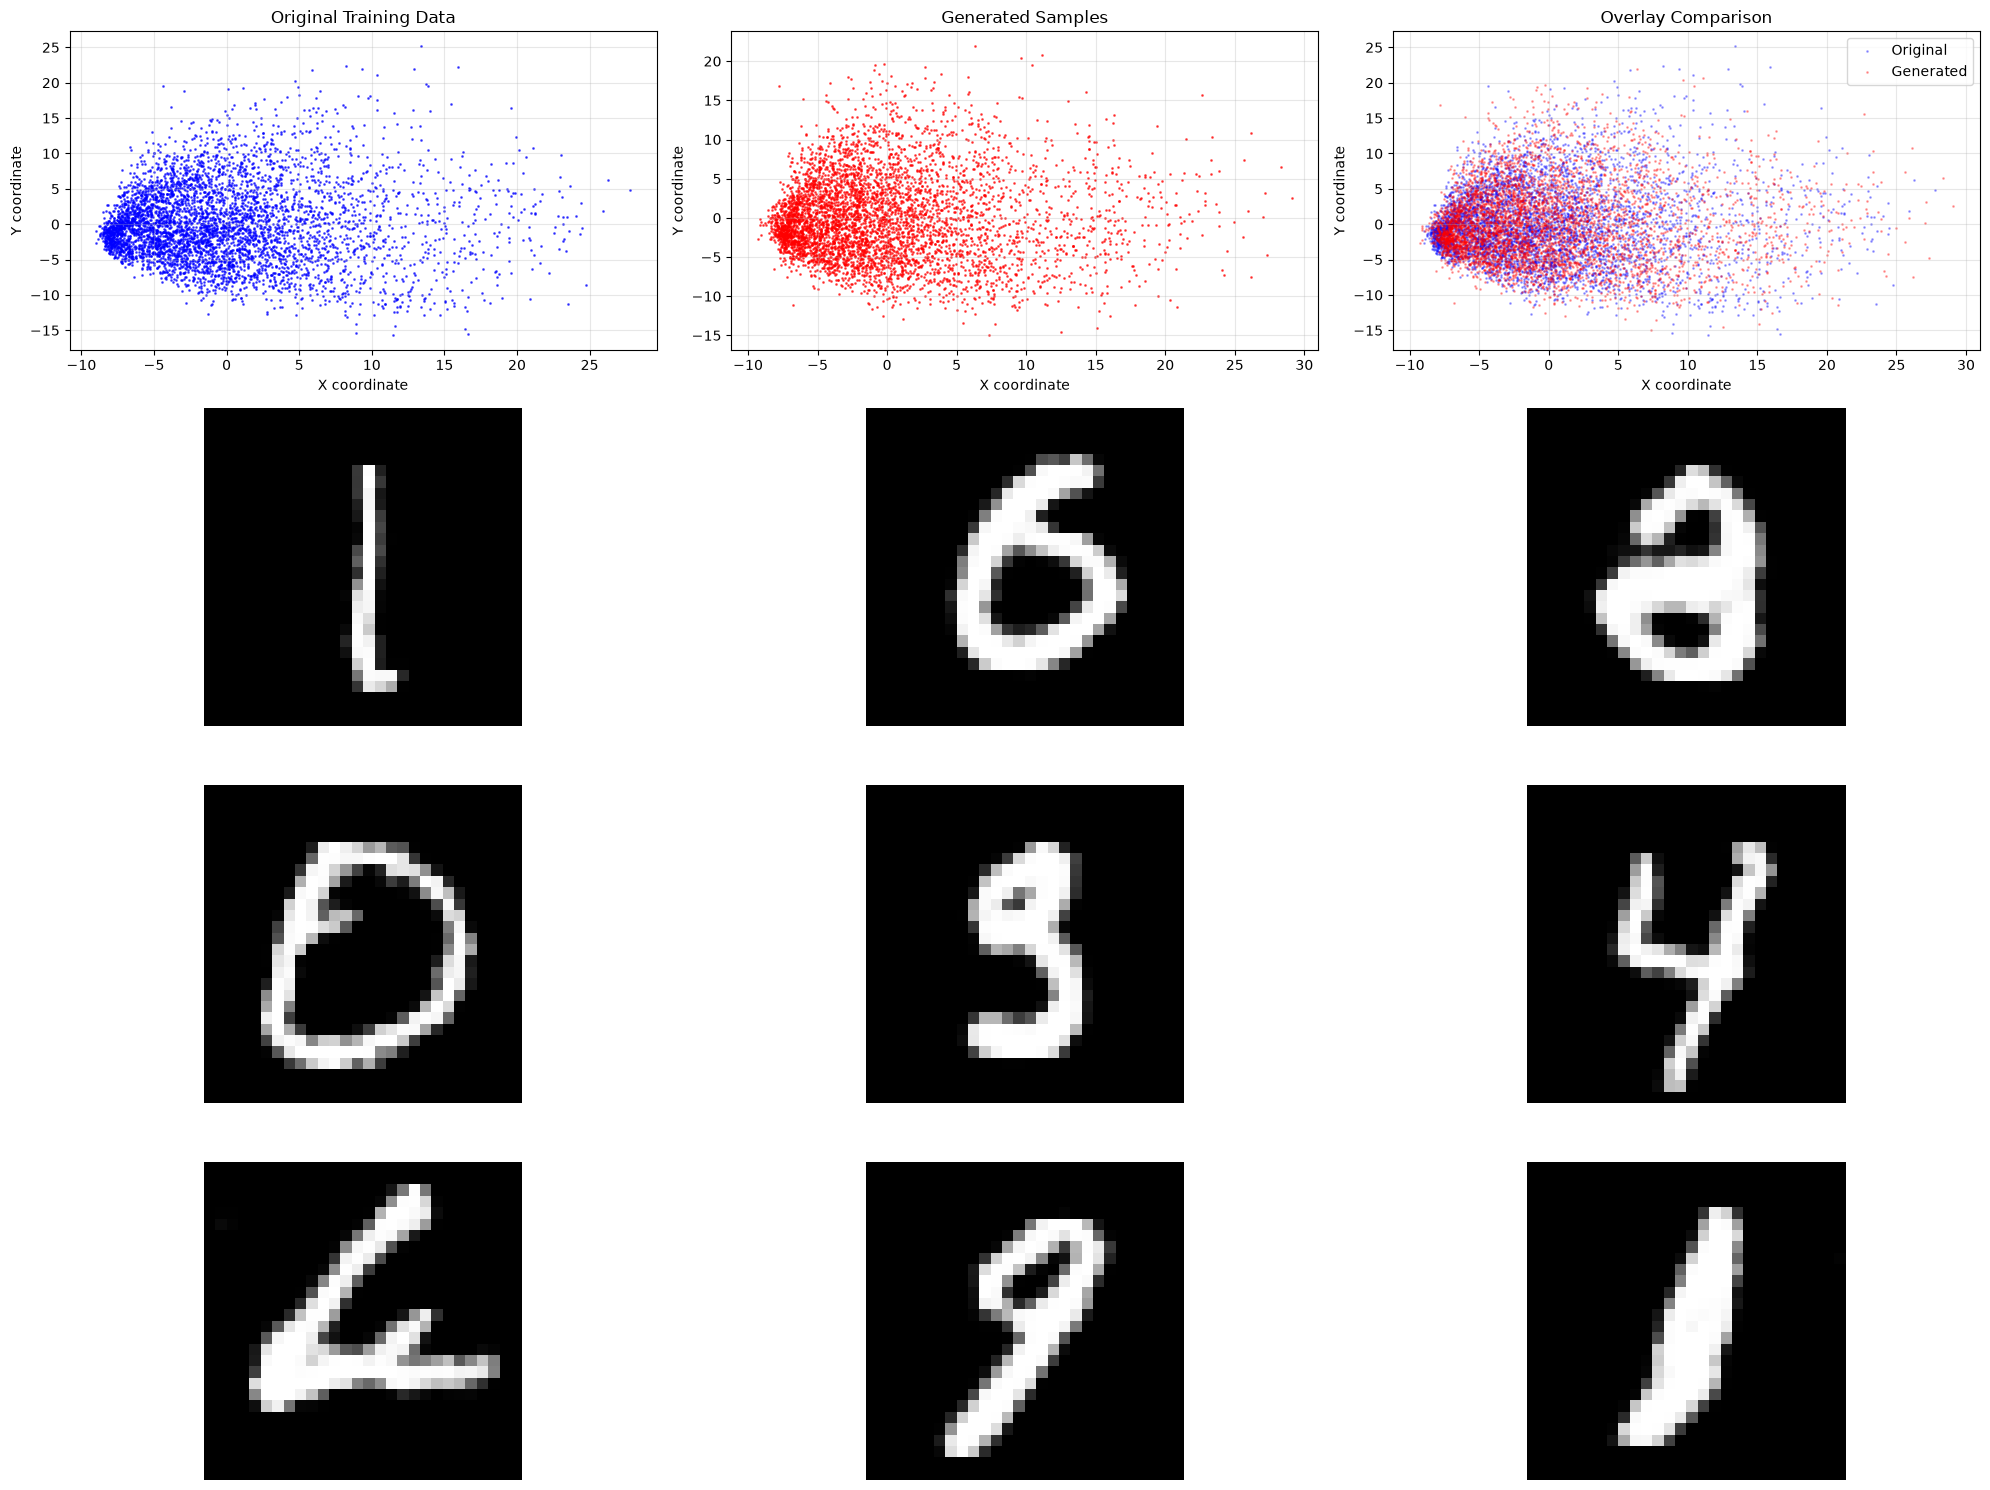

Real data confidence: 0.653
Fake data confidence: 0.304


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
